# Tecnológico de Monterrey
## Proyecto Integrador — Equipo 23
## Avance 3. Baseline
**Integrantes:**

- Edmundo Carmona Galindo - A01796647
- Jaqueline Villafranca Hernández - A01656679
- Edgar Omar Cruz Mendoza - A01795590

In [0]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import itertools
import scipy.stats as ss
warnings.filterwarnings('ignore')

from scipy.stats.mstats import winsorize
from scipy.stats import skew
from IPython.display import display
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.metrics import roc_auc_score, average_precision_score

sns.set_theme(style="whitegrid")

CARGA DE BASE DE DATOS Y ANÁLISIS DE TIPOS

In [0]:
# A. Carga del archivo
file_path = 'REGISTRO.xlsx'
df_morge = pd.read_excel(file_path, header=0)

print(f"Dimensiones de la base de la Morgue: {df_morge.shape[0]} filas y {df_morge.shape[1]} columnas.")

# B. Ficha pre-mortem de DEMOSTRACIÓN (datos anonimizados; no corresponde a una persona real identificable)
ficha = pd.DataFrame([{
    'ID': 'FICHA-DEMO-001',
    'PRE_EDAD': 22.0,
    'PRE_ESTATURA': 170.0,
    'PRE_SEXO': 'HOMBRE',
    'PRE_FECHA': pd.to_datetime('2026-05-28'),
    'PRE_MUNICIPIO': 'APATZINGAN',
    'PRE_SENAS': 'lunares en el cuello lunar nariz cicatriz en oreja izquierda',
    'PRE_ROPA': 'playera gris shorts gris tenis negro'
}])

Dimensiones de la base de la Morgue: 5317 filas y 235 columnas.


2. PREPROCESAMIENTO Y LIMPIEZA

In [0]:
# En caso de que pandas haya metido una fila extra o basura antes de los nombres,
# la siguiente alternativa garantiza que tomamos la fila correcta (índice 0 de los datos) como título:
if 'AÑO' not in df_morge.columns:  # Verificación rápida
    df_morge.columns = df_morge.iloc[0]
    df_morge = df_morge.drop(index=0).reset_index(drop=True)

# Limpiamos los nombres de las columnas (quitando espacios en blanco al inicio o al final)
df_morge.columns = df_morge.columns.astype(str).str.strip()

# Por confidencialidad no se muestran filas reales: solo nombres de columnas
print(f"Dimensiones de la base de la Morgue: {df_morge.shape[0]} filas y {df_morge.shape[1]} columnas.")
display(pd.DataFrame({'Columna': df_morge.columns[:15]}))

Dimensiones de la base de la Morgue: 5317 filas y 235 columnas.


,Columna
0,No
1,AÑO
2,FECHA DE INGRESO AL ANFITEATRO
3,HORA DE NECROPSIA Y/O ANTROPOLOGICO
4,TIPO\n (QUÉ INGRESA A SEMEFO)
5,SEXO
6,AVERIGUACIÓN PREVIA O CARPETA DE INVESTIGACIÓN
7,AVERIGUACIÓN PREVIA O CARPETA DE INVESTIGACIÓN...
8,STATUS
9,"EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORR..."


Estructura de los datos

In [0]:
print(f"Dimensiones de la tabla de trabajo: {df_morge.shape[0]} filas x {df_morge.shape[1]} columnas\n")

df_morge.info(verbose=True, show_counts=True)

Dimensiones de la tabla de trabajo: 5317 filas x 235 columnas

<class 'pandas.DataFrame'>
RangeIndex: 5317 entries, 0 to 5316
Data columns (total 235 columns):
 #    Column                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                Non-Null Count  Dtype         
---   ------                                                                                                                                                                                                                                                 

# **Elementos descartados del archivo original**

Para un modelo de Machine Learning (Record Linkage), debemos ser muy estrictos y separar las variables en tres grupos:

**Características Predictivas (Features):** Las que sí se pueden comparar matemáticamente con la ficha de la persona desaparecida (edad, sexo, ropa, señas, municipio).

**Variables de Control/Objetivo (Targets):** Nombres o estatus que nos sirven para saber si un caso ya fue resuelto (y usarlo para entrenar) o si sigue sin identificar.

**Ruido Administrativo (Para Descartar):** Números de folios, oficios, fechas de reportes o anotaciones internas. A la Inteligencia Artificial no le sirve saber el "Número de informe de química", ya que no aporta ninguna similitud biológica.

# **Diccionario de variables**

Se construye una tabla que asocia cada columna con su bloque institucional, su tipo de dato y su escala de medición. La escala determina qué gráfico corresponde a cada variable en la sección 4: una variable nominal se representa con barras de frecuencia y nunca con histograma; una variable de razón admite histograma, diagrama de caja y medidas de tendencia central.

In [0]:
# 1. Definición del Diccionario de Variables
diccionario_datos = [
    # --- BLOQUE: BIOLÓGICO Y FÍSICO (Predictivas) ---
    {"Variable": "EDAD", "Bloque Institucional": "Biológico/Físico", "Tipo de Dato": "Numérico Continuo", "Escala de Medición": "Razón", "Visualización Sugerida": "Histograma, Diagrama de Caja"},
    {"Variable": "ESTATURA", "Bloque Institucional": "Biológico/Físico", "Tipo de Dato": "Numérico Continuo", "Escala de Medición": "Razón", "Visualización Sugerida": "Histograma, Diagrama de Caja"},
    {"Variable": "SEXO", "Bloque Institucional": "Biológico/Físico", "Tipo de Dato": "Categórico", "Escala de Medición": "Nominal", "Visualización Sugerida": "Gráfico de Barras"},
    {"Variable": "SENAS_PARTICULARES", "Bloque Institucional": "Biológico/Físico", "Tipo de Dato": "Texto Libre", "Escala de Medición": "Nominal", "Visualización Sugerida": "Nube de Palabras / Tabla de Frecuencias"},
    {"Variable": "CARACTERISTICAS DENTALES DETECTADAS", "Bloque Institucional": "Biológico/Odontológico", "Tipo de Dato": "Texto Libre", "Escala de Medición": "Nominal", "Visualización Sugerida": "Tabla de Frecuencias"},

    # --- BLOQUE: PERTENENCIAS Y CONTEXTO (Predictivas) ---
    {"Variable": "MUNICIPIO", "Bloque Institucional": "Geográfico/Procedencia", "Tipo de Dato": "Categórico", "Escala de Medición": "Nominal", "Visualización Sugerida": "Gráfico de Barras (Pareto)"},
    {"Variable": "ROPA", "Bloque Institucional": "Pertenencias/Indicios", "Tipo de Dato": "Texto Libre", "Escala de Medición": "Nominal", "Visualización Sugerida": "Nube de Palabras / Tabla de Frecuencias"},
    {"Variable": "DESCRIPCION DE PERTENENCIAS...", "Bloque Institucional": "Pertenencias/Indicios", "Tipo de Dato": "Texto Libre", "Escala de Medición": "Nominal", "Visualización Sugerida": "Tabla de Frecuencias"},
    {"Variable": "DESCRIPCION DE OTRAS PERTENENCIAS...", "Bloque Institucional": "Pertenencias/Indicios", "Tipo de Dato": "Texto Libre", "Escala de Medición": "Nominal", "Visualización Sugerida": "Tabla de Frecuencias"},
    {"Variable": "INFORMACION RELEVANTE INDICIOS...", "Bloque Institucional": "Pertenencias/Indicios", "Tipo de Dato": "Texto Libre", "Escala de Medición": "Nominal", "Visualización Sugerida": "Tabla de Frecuencias"},

    # --- BLOQUE: ADMINISTRATIVO Y FORENSE (Contexto) ---
    {"Variable": "AÑO", "Bloque Institucional": "Administrativo/Temporal", "Tipo de Dato": "Numérico Discreto", "Escala de Medición": "Intervalo", "Visualización Sugerida": "Gráfico de Barras / Serie de Tiempo"},
    {"Variable": "TIPO_INGRESO", "Bloque Institucional": "Administrativo/Forense", "Tipo de Dato": "Categórico", "Escala de Medición": "Nominal", "Visualización Sugerida": "Gráfico de Barras"},
    {"Variable": "STATUS", "Bloque Institucional": "Administrativo/Control", "Tipo de Dato": "Categórico", "Escala de Medición": "Nominal", "Visualización Sugerida": "Gráfico de Barras"},

    # --- BLOQUE: IDENTIDAD (Targets para Evaluación) ---
    {"Variable": "NOMBRE_IDENTIFICADO", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Texto", "Escala de Medición": "Nominal", "Visualización Sugerida": "N/A (Identificador Único)"},
    {"Variable": "NOMBRE DEL FALLECIDO", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Texto", "Escala de Medición": "Nominal", "Visualización Sugerida": "N/A (Identificador Único)"},
    {"Variable": "APELLIDO PATERNO", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Texto", "Escala de Medición": "Nominal", "Visualización Sugerida": "N/A (Identificador Único)"},
    {"Variable": "APELLIDO MATERNO", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Texto", "Escala de Medición": "Nominal", "Visualización Sugerida": "N/A (Identificador Único)"},
    {"Variable": "NOMBRE (S)", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Texto", "Escala de Medición": "Nominal", "Visualización Sugerida": "N/A (Identificador Único)"},
    {"Variable": "FECHA_NACIMIENTO", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Fecha", "Escala de Medición": "Intervalo", "Visualización Sugerida": "N/A (Para cálculo exacto)"},
    {"Variable": "ESTADO DE NACIMIENTO", "Bloque Institucional": "Identidad/Target", "Tipo de Dato": "Categórico", "Escala de Medición": "Nominal", "Visualización Sugerida": "Gráfico de Barras"}
]

# 2. Generar el DataFrame del Diccionario
df_diccionario = pd.DataFrame(diccionario_datos)

# 3. Mostrar la tabla formateada
print(" DICCIONARIO DE VARIABLES Y ESCALAS DE MEDICIÓN:")
display(df_diccionario)

 DICCIONARIO DE VARIABLES Y ESCALAS DE MEDICIÓN:


,Variable,Bloque Institucional,Tipo de Dato,Escala de Medición,Visualización Sugerida
0,EDAD,Biológico/Físico,Numérico Continuo,Razón,"Histograma, Diagrama de Caja"
1,ESTATURA,Biológico/Físico,Numérico Continuo,Razón,"Histograma, Diagrama de Caja"
2,SEXO,Biológico/Físico,Categórico,Nominal,Gráfico de Barras
3,SENAS_PARTICULARES,Biológico/Físico,Texto Libre,Nominal,Nube de Palabras / Tabla de Frecuencias
4,CARACTERISTICAS DENTALES DETECTADAS,Biológico/Odontológico,Texto Libre,Nominal,Tabla de Frecuencias
5,MUNICIPIO,Geográfico/Procedencia,Categórico,Nominal,Gráfico de Barras (Pareto)
6,ROPA,Pertenencias/Indicios,Texto Libre,Nominal,Nube de Palabras / Tabla de Frecuencias
7,DESCRIPCION DE PERTENENCIAS...,Pertenencias/Indicios,Texto Libre,Nominal,Tabla de Frecuencias
8,DESCRIPCION DE OTRAS PERTENENCIAS...,Pertenencias/Indicios,Texto Libre,Nominal,Tabla de Frecuencias
9,INFORMACION RELEVANTE INDICIOS...,Pertenencias/Indicios,Texto Libre,Nominal,Tabla de Frecuencias


# **Descriptivos y frecuencia de clases.**
describe(include='all') se calcula sobre todas las columnas excepto las de texto libre: para esas, los estadísticos top y freq imprimirían la cadena más repetida, y aunque en la práctica suele ser un valor de relleno, el notebook se publica en un repositorio. El texto libre se caracteriza por separado, solo con longitudes y cobertura.

In [0]:
# Hacemos una copia de trabajo para Machine Learning
df_morge_ml = df_morge.copy()

# 2. RENOMBRADO ROBUSTO (Solución al KeyError)
# Buscamos coincidencias parciales ignorando espacios basura o saltos de línea
nombres_cortos_exactos = {
    "TIPO\n (QUÉ INGRESA A SEMEFO)": "TIPO_INGRESO",
    "MUNICIPIO DE PROCEDENCIA": "MUNICIPIO",
    "DESCRIPCION DE ROPA QUE VESTIA": "ROPA",
    "SEÑAS PARTICULARES Y/O CARACTERISTICAS \n(CICATRICES, TATUAJES, LUNARES, MANCHAS, ETC.)": "SENAS_PARTICULARES",
    "EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORRESPONDE AL CADAVER\nDEBERA ESTABLECER AQUÍ EL NOMBRE EN EL MOMENTO EN QUE SE ACTUALICE DICHA SITUACION": "NOMBRE_IDENTIFICADO",
    "FECHA DE NACIMIENTO\n (dia/mes/año) (oo/oo/oooo/": "FECHA_NACIMIENTO",
    "STATUS": "STATUS"
}
df_morge_ml.rename(columns=nombres_cortos_exactos, inplace=True)

# Renombrado dinámico para las columnas problemáticas
for col in df_morge_ml.columns:
    if 'ESTATURA' in col:
        df_morge_ml.rename(columns={col: 'ESTATURA'}, inplace=True)
    elif 'EDAD' in col:
        df_morge_ml.rename(columns={col: 'EDAD'}, inplace=True)
    elif 'SEXO' in col:
        df_morge_ml.rename(columns={col: 'SEXO'}, inplace=True)

# 3. LIMPIEZA NUMÉRICA
def clean_num(val):
    if pd.isna(val): return np.nan
    match = re.search(r'(\d+)', str(val))
    return float(match.group(1)) if match else np.nan

df_morge_ml['EDAD'] = df_morge_ml['EDAD'].apply(clean_num)
df_morge_ml['ESTATURA'] = df_morge_ml['ESTATURA'].apply(clean_num)
df_morge_ml['AÑO'] = pd.to_numeric(df_morge_ml['AÑO'], errors='coerce')

# 4. CLASIFICACIÓN DE COLUMNAS
cols_numericas = ['EDAD', 'ESTATURA', 'AÑO']
cols_categoricas = ['TIPO_INGRESO', 'SEXO', 'MUNICIPIO', 'STATUS', 'ESTADO DE NACIMIENTO']
cols_texto_libre = [
    'ROPA', 'SENAS_PARTICULARES', 'NOMBRE_IDENTIFICADO',
    'NOMBRE DEL FALLECIDO', 'APELLIDO PATERNO', 'APELLIDO MATERNO',
    'NOMBRE (S)', 'DESCRIPCION DE PERTENENCIAS QUE PERMITAN LA IDENTIFICACION ',
    'DESCRIPCION DE OTRAS PERTENENCIAS U OBJETOS',
    'INFORMACION RELEVANTE PARA LA IDENTIFICACIÓN REPORTADA COMO INDICIOS (PERTENENCIAS)',
    'CARACTERISTICAS DENTALES DETECTADAS'
]

# Filtrar solo las columnas que realmente existen en el DataFrame para evitar nuevos KeyErrors
cols_numericas = [c for c in cols_numericas if c in df_morge_ml.columns]
cols_categoricas = [c for c in cols_categoricas if c in df_morge_ml.columns]
cols_texto_libre = [c for c in cols_texto_libre if c in df_morge_ml.columns]

# 5. ANÁLISIS DESCRIPTIVO
print("1. ESTADÍSTICOS DESCRIPTIVOS (Variables Numéricas)")
display(df_morge_ml[cols_numericas].describe().round(2))

print("\n 2. FRECUENCIA DE CLASES (Variables Categóricas)")
display(df_morge_ml[cols_categoricas].describe(include=['object', 'category']))

print("\n Detalle de Distribución Nominal: SEXO")
display(df_morge_ml['SEXO'].value_counts(dropna=False).to_frame(name="Frecuencia"))

print("\n 3. CARACTERIZACIÓN DE TEXTO LIBRE (Cobertura y Longitud Segura)")
resumen_texto = []
for col in cols_texto_libre:
    cobertura = df_morge_ml[col].notnull().sum()
    porcentaje_cob = (cobertura / len(df_morge_ml)) * 100
    longitudes = df_morge_ml[col].dropna().astype(str).str.len()

    resumen_texto.append({
        'Variable': col,
        'Registros Llenos': cobertura,
        'Cobertura (%)': round(porcentaje_cob, 2),
        'Longitud Min (chars)': longitudes.min() if cobertura > 0 else 0,
        'Longitud Media (chars)': round(longitudes.mean(), 1) if cobertura > 0 else 0,
        'Longitud Max (chars)': longitudes.max() if cobertura > 0 else 0
    })

display(pd.DataFrame(resumen_texto))

1. ESTADÍSTICOS DESCRIPTIVOS (Variables Numéricas)


,EDAD,ESTATURA,AÑO
count,1112.00,699.00,1247.00
mean,42.25,151.50,2018.52
std,16.21,41.13,5.41
min,0.00,7.00,2006.00
25%,30.00,157.00,2014.00
50%,40.00,164.00,2019.00
75%,54.00,170.00,2023.00
max,100.00,195.00,2026.00



 2. FRECUENCIA DE CLASES (Variables Categóricas)


,TIPO_INGRESO,SEXO,MUNICIPIO,STATUS
count,1247,1241,1216,1247
unique,11,13,39,3
top,CADAVER,MASCULINO,QUERETARO,NO IDENTIFICADO
freq,914,989,555,890



 Detalle de Distribución Nominal: SEXO


,Frecuencia
SEXO,
NaN,4076
MASCULINO,989
Masculino,93
FEMENINO,80
NO VALORABLE,27
Femenino,17
INDETERMINADO,16
Indeterminado,6
MASCULINO,5



 3. CARACTERIZACIÓN DE TEXTO LIBRE (Cobertura y Longitud Segura)


,Variable,Registros Llenos,Cobertura (%),Longitud Min (chars),Longitud Media (chars),Longitud Max (chars)
0,ROPA,1188,22.34,3,218.1,2126
1,SENAS_PARTICULARES,1197,22.51,2,211.0,3982
2,NOMBRE_IDENTIFICADO,353,6.64,12,25.1,92
3,NOMBRE DEL FALLECIDO,1208,22.72,9,15.5,89
4,APELLIDO PATERNO,144,2.71,3,6.5,11
5,APELLIDO MATERNO,144,2.71,2,6.7,9
6,NOMBRE (S),144,2.71,4,9.3,31
7,DESCRIPCION DE OTRAS PERTENENCIAS U OBJETOS,631,11.87,6,16.8,1129
8,INFORMACION RELEVANTE PARA LA IDENTIFICACIÓN R...,681,12.81,7,34.1,2343
9,CARACTERISTICAS DENTALES DETECTADAS,840,15.80,7,136.8,3143


# **Valores faltantes**
Se reporta primero el conteo de nulos

**Análisis de la Gráfica de Barras Horizontales (Frecuencia de Nulos)**
La gráfica clasifica la ausencia de información en tres bloques operativos:

* Ausencia Esperada (>90% nulos - Variables Target): Las columnas como NOMBRE_IDENTIFICADO, APELLIDO PATERNO, APELLIDO MATERNO y FECHA_NACIMIENTO presentan la mayor cantidad de celdas vacías. Esto es un comportamiento metodológicamente correcto, ya que el grueso de la base de datos corresponde a cuerpos no identificados. Estos pocos registros completos son la "etiqueta de verdad" que usaremos más adelante para validar si el modelo cruza correctamente los casos ya resueltos.

* Ausencia Operativa (~60% a 80% nulos - Texto Libre): Variables como ROPA, SENAS_PARTICULARES, CARACTERISTICAS DENTALES DETECTADAS y descripciones de PERTENENCIAS muestran un alto nivel de ausencia. Esto refleja la realidad del contexto forense: cuerpos que ingresan desnudos, en fase de esqueletización, calcinados o sin objetos personales, imposibilitando el registro de estas características.

* Pilares Predictivos (menor del 20% nulos - Biológicas y Geográficas): Variables fundamentales como SEXO, EDAD, ESTATURA y MUNICIPIO tienen una tasa de completitud muy alta. Al ser mediciones obligatorias en casi cualquier necropsia o análisis antropológico, se convierten en la columna vertebral del algoritmo de Record Linkage.

**Análisis del Mapa de Calor (Patrones Concurrentes)**
El mapa de calor expone la simultaneidad de los datos faltantes a través de las franjas amarillas:

* Bloques de Identidad: Se observa un bloque amarillo continuo en las columnas del lado derecho (nombres y fechas de nacimiento), el cual solo se interrumpe en filas específicas donde un cuerpo logró ser identificado (franjas oscuras horizontales en esas áreas).

* Ausencia Condicionada (Missing Not At Random): Existen franjas horizontales donde faltan simultáneamente la ropa, las señas particulares y las pertenencias. Esto indica que la ausencia no es un error de captura al azar, sino que está condicionada por el estado del cuerpo (ej. restos óseos o machacamiento).

**Decisión Metodológica para Machine Learning**

Estos patrones confirman que es matemáticamente inviable usar la eliminación de filas completas (Dropna/Listwise Deletion). Si eliminamos toda fila que tenga un valor nulo en "Ropa" o "Señas", perderíamos casi el 80% de la base de datos. En el siguiente paso, se debe aplicar una estrategia de imputación: asignar la mediana a las variables numéricas (Edad/Estatura) para no sesgar la distribución, y rellenar los valores nulos categóricos o de texto libre con una etiqueta de "Sin Dato" para que el modelo aprenda a procesar esa ausencia sin penalizar la similitud.

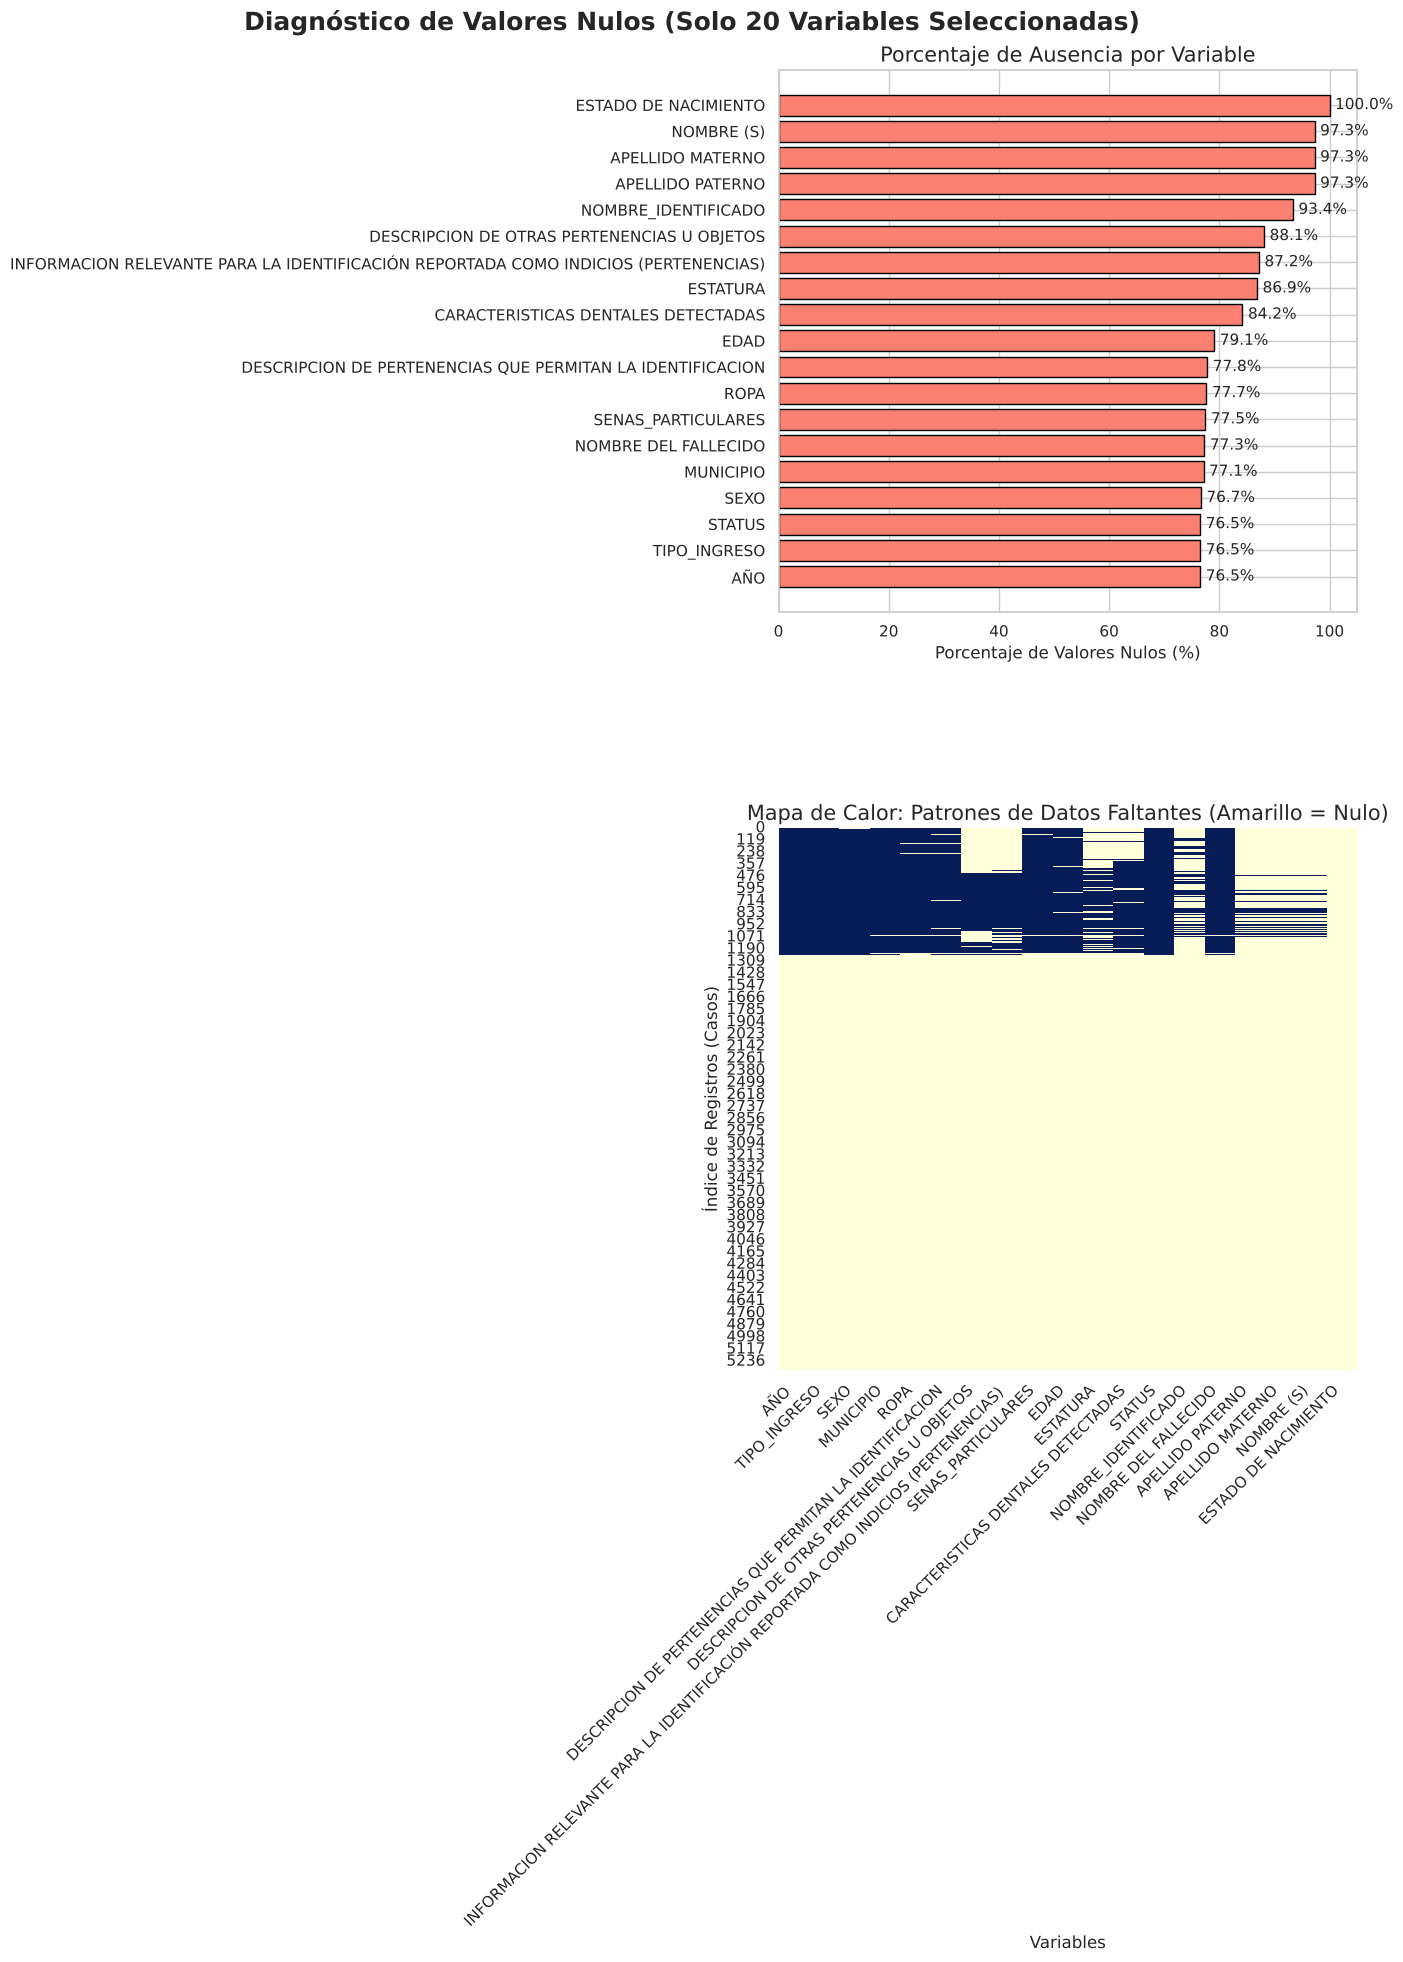

In [0]:
# 1. DEFINICIÓN ESTRICTA DE LAS 20 VARIABLES
columnas_20 = [
    "AÑO", "TIPO_INGRESO", "SEXO", "MUNICIPIO", "ROPA",
    "DESCRIPCION DE PERTENENCIAS QUE PERMITAN LA IDENTIFICACION",
    "DESCRIPCION DE OTRAS PERTENENCIAS U OBJETOS",
    "INFORMACION RELEVANTE PARA LA IDENTIFICACIÓN REPORTADA COMO INDICIOS (PERTENENCIAS)",
    "SENAS_PARTICULARES", "EDAD", "ESTATURA", "CARACTERISTICAS DENTALES DETECTADAS",
    "STATUS", "NOMBRE_IDENTIFICADO", "NOMBRE DEL FALLECIDO",
    "APELLIDO PATERNO", "APELLIDO MATERNO", "NOMBRE (S)",
    "FECHA_NACIMIENTO", "ESTADO DE NACIMIENTO"
]

# Aseguramos que solo usamos las columnas que existen en el DataFrame actual
# (por si hay alguna pequeña variación de espacios)
cols_a_graficar = [col for col in columnas_20 if col in df_morge_ml.columns]

# Creamos un DataFrame exclusivo para las gráficas
df_graficas = df_morge_ml[cols_a_graficar]

# 2. PREPARACIÓN DE DATOS DE NULOS
nulos_conteo = df_graficas.isnull().sum()
nulos_porcentaje = (nulos_conteo / len(df_graficas)) * 100
df_nulos = pd.DataFrame({'Nulos': nulos_conteo, 'Porcentaje (%)': nulos_porcentaje})
df_nulos = df_nulos.sort_values(by='Porcentaje (%)', ascending=True)

# Crear figura con dos subgráficos, uno arriba del otro (2 filas, 1 columna)
fig, axes = plt.subplots(2, 1, figsize=(14, 20))
fig.suptitle('Diagnóstico de Valores Nulos (Solo 20 Variables Seleccionadas)', fontsize=18, fontweight='bold')

# 3. GRÁFICA DE BARRAS HORIZONTALES (Frecuencia de Nulos) - Arriba
bars = axes[0].barh(df_nulos.index, df_nulos['Porcentaje (%)'], color='salmon', edgecolor='black')
axes[0].set_title('Porcentaje de Ausencia por Variable', fontsize=15)
axes[0].set_xlabel('Porcentaje de Valores Nulos (%)', fontsize=12)
axes[0].set_xlim(0, 105) # Un poco de espacio extra para el texto

# Etiquetar los porcentajes en las barras
for bar in bars:
    width = bar.get_width()
    # Solo poner texto si el ancho es mayor a 0 para que se vea limpio
    if width > 0:
        axes[0].text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center', fontsize=11)

# 4. DIAGRAMA DE CALOR (Patrones de Ausencia) - Abajo
sns.heatmap(df_graficas.isnull(), cbar=False, cmap='YlGnBu_r', ax=axes[1])
axes[1].set_title('Mapa de Calor: Patrones de Datos Faltantes (Amarillo = Nulo)', fontsize=15)
axes[1].set_ylabel('Índice de Registros (Casos)', fontsize=12)
axes[1].set_xlabel('Variables', fontsize=12)

# Rotamos las etiquetas del eje X en el mapa de calor para que sean perfectamente legibles
axes[1].tick_params(axis='x', rotation=45)
for label in axes[1].get_xticklabels():
    label.set_ha('right')

# Ajuste de espacios
plt.tight_layout()
plt.subplots_adjust(top=0.95, hspace=0.4)
plt.show()

# **Explicación de los Resultados de Saneamiento**
* **Normalización de Espacios:** Se unificó toda la captura de las 20 columnas a mayúsculas, se eliminaron los espacios invisibles al inicio y final de las celdas, y se aplanaron los dobles o triples espacios (muy comunes cuando se teclea rápido en la morgue). Esto garantiza que "PLAYERA NEGRA" y "PLAYERA   NEGRA " ahora se agrupen y contabilicen como el mismo valor en la siguiente fase.

* **Variables Derivadas:** Las columnas de Edad y Estatura estaban contaminadas con cadenas de texto (como "AÑOS" o "MESES"). La función basada en Expresiones Regulares (regex) barrió las celdas, aisló únicamente la cifra y la convirtió a variable continua (float).

* **Corrección de Año:** Se aplicó una regla lógica para detectar los típicos "dedazos" de tres dígitos en la fecha de los expedientes físicos y convertirlos a formatos de cuatro dígitos estándar.

* **Estadística Descriptiva:** El .describe() final demuestra que estas tres variables ya son reconocidas por el sistema como valores matemáticos puramente calculables, dejando en evidencia valores atípicos evidentes (como estaturas de 7 cm o edades de 0 años) que abordaremos en la próxima fase.

In [0]:
print(" SANEAMIENTO (Correcciones Mecánicas)")

df_morge_ml = df_morge_ml.loc[:, ~df_morge_ml.columns.duplicated()].copy()

# 1. Normalización de espacios y typos (Variables de Texto)
cols_texto = df_morge_ml.select_dtypes(include=['object', 'category']).columns

for col in cols_texto:
    # Ahora sí, al estar seguros de que es una Serie, aplicamos .str sin problema
    df_morge_ml[col] = df_morge_ml[col].astype(str).str.upper().str.strip()

    # Reducir múltiples espacios internos a un solo espacio
    df_morge_ml[col] = df_morge_ml[col].replace(r'\s+', ' ', regex=True)

    # Revertir los 'NAN' (creados por pandas al convertir nulos a string) a verdaderos np.nan
    df_morge_ml[col] = df_morge_ml[col].replace('NAN', np.nan)

print("1. Espacios sobrantes y typos normalizados (formato mayúsculas uniforme).")


# 2. Creación de Variables Derivadas (Extracción numérica)
def extraer_numero(texto):
    if pd.isna(texto):
        return np.nan
    match = re.search(r'(\d+)', str(texto))
    return float(match.group(1)) if match else np.nan

df_morge_ml['EDAD_NUM'] = df_morge_ml['EDAD'].apply(extraer_numero)
df_morge_ml['ESTATURA_NUM'] = df_morge_ml['ESTATURA'].apply(extraer_numero)

print("2. Variables numéricas derivadas extraídas exitosamente ('EDAD_NUM', 'ESTATURA_NUM').")


# 3. Corrección de error de año
df_morge_ml['AÑO'] = pd.to_numeric(df_morge_ml['AÑO'], errors='coerce')

def corregir_ano(ano):
    if pd.isna(ano): return np.nan
    if 200 <= ano <= 209:
        return 2000 + (ano % 200)
    return ano

df_morge_ml['AÑO_CORREGIDO'] = df_morge_ml['AÑO'].apply(corregir_ano)

print("3. Error mecánico de captura en el año corregido ('AÑO_CORREGIDO').")


# 4. Descriptivos de las variables numéricas derivadas
variables_derivadas = ['AÑO_CORREGIDO', 'EDAD_NUM', 'ESTATURA_NUM']

print("\n 4. Descriptivos de las variables numéricas derivadas (Pre-tratamiento de atípicos):")
display(df_morge_ml[variables_derivadas].describe().round(2))

 SANEAMIENTO (Correcciones Mecánicas)


1. Espacios sobrantes y typos normalizados (formato mayúsculas uniforme).
2. Variables numéricas derivadas extraídas exitosamente ('EDAD_NUM', 'ESTATURA_NUM').
3. Error mecánico de captura en el año corregido ('AÑO_CORREGIDO').

 4. Descriptivos de las variables numéricas derivadas (Pre-tratamiento de atípicos):


,AÑO_CORREGIDO,EDAD_NUM,ESTATURA_NUM
count,1247.00,1112.00,699.00
mean,2018.52,42.25,151.50
std,5.41,16.21,41.13
min,2006.00,0.00,7.00
25%,2014.00,30.00,157.00
50%,2019.00,40.00,164.00
75%,2023.00,54.00,170.00
max,2026.00,100.00,195.00


# **Análisis univariante**
Cada variable se grafica según la escala de medición declarada en el diccionario: histograma y diagrama de caja para variables de razón, barras de frecuencia para nominales, top-N más cola para nominales de alta cardinalidad, barras apiladas para banderas binarias, y distribución de longitudes para texto libre.


 1. Graficando Variables Numéricas (Histograma, Caja y Asimetría)...


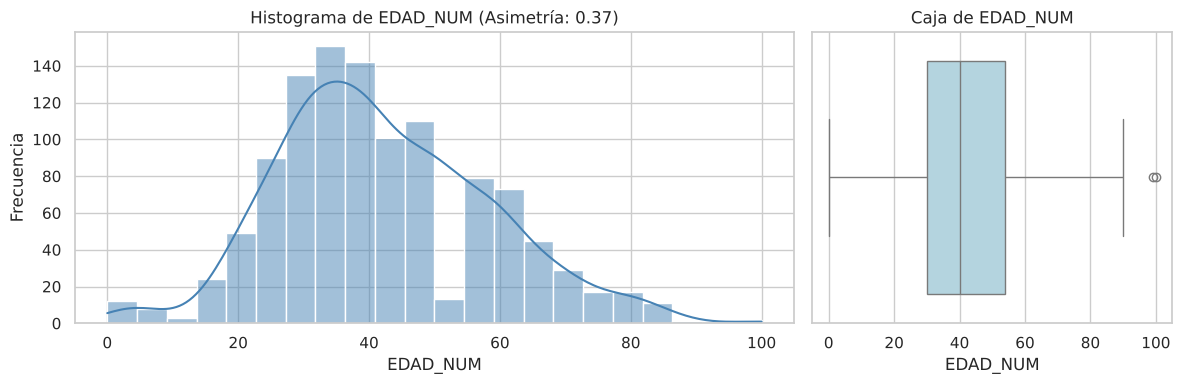

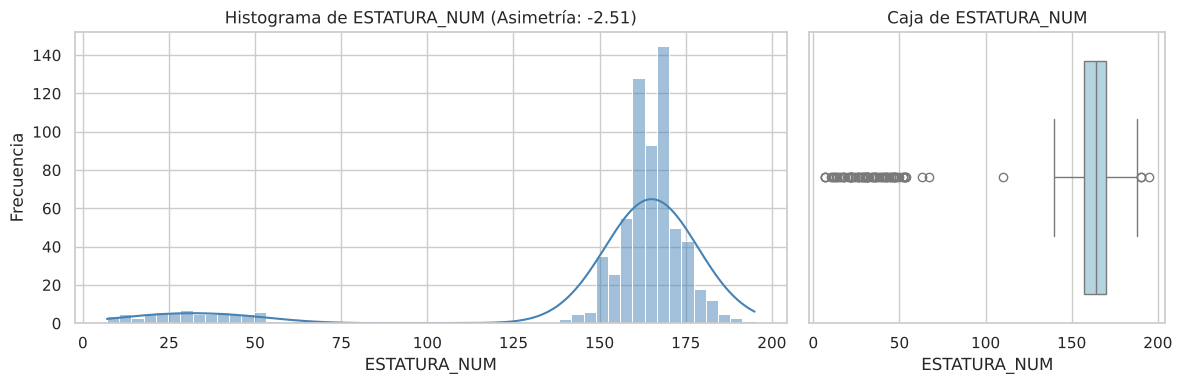

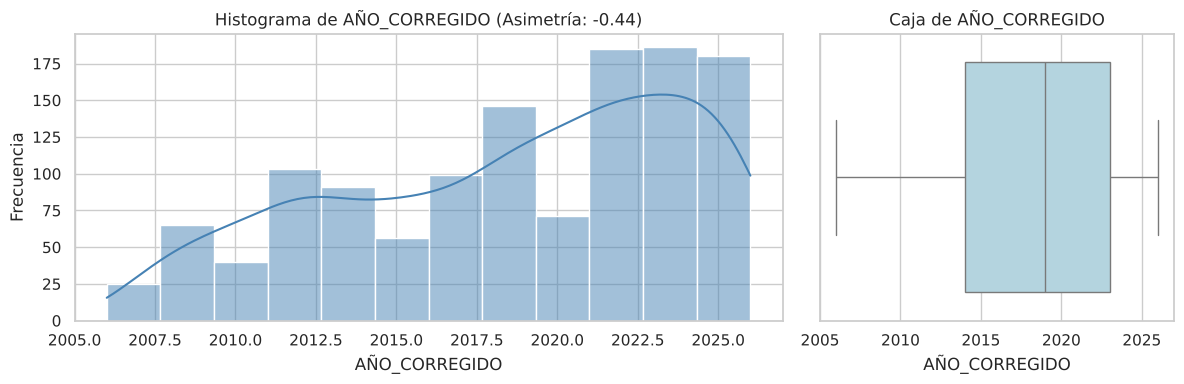


 2. Graficando Categóricas de Baja Cardinalidad...


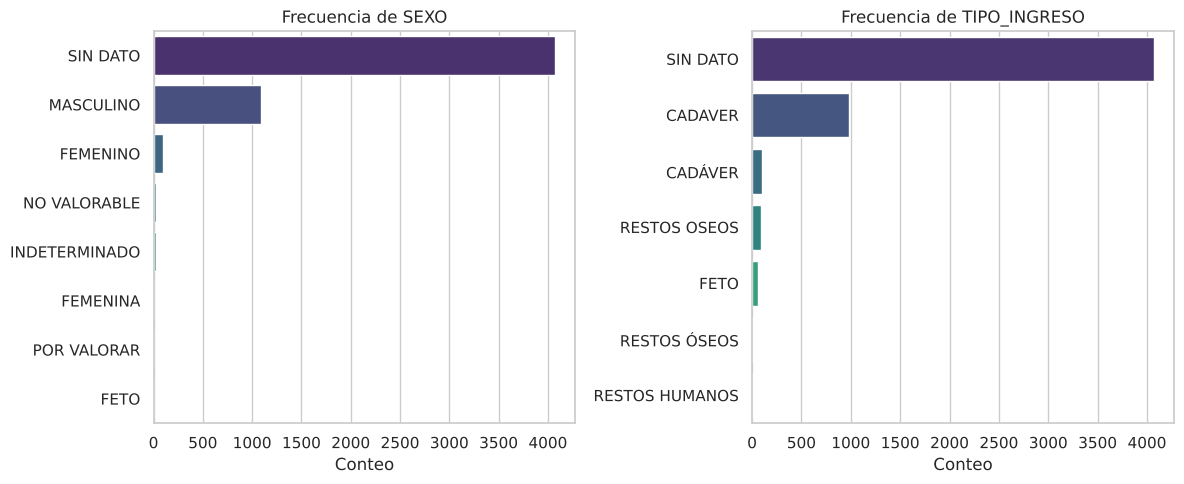


 3. Graficando Categóricas de Alta Cardinalidad (Top 10 + Otros)...


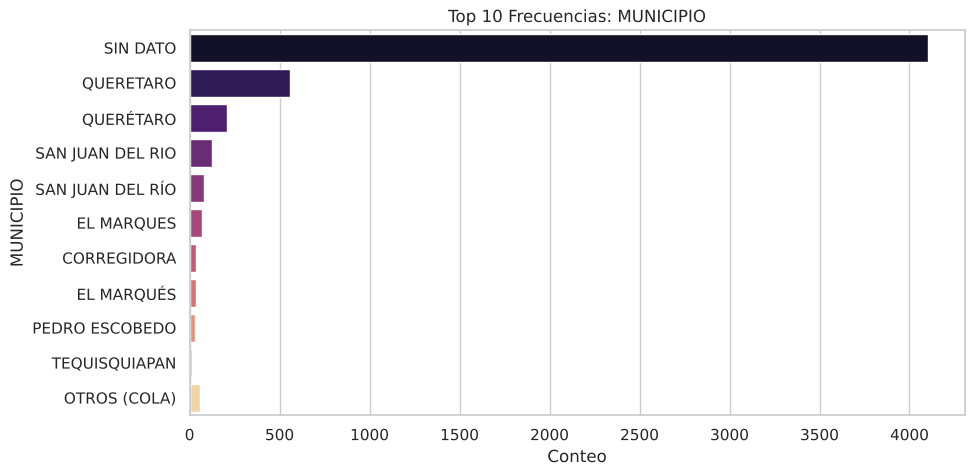

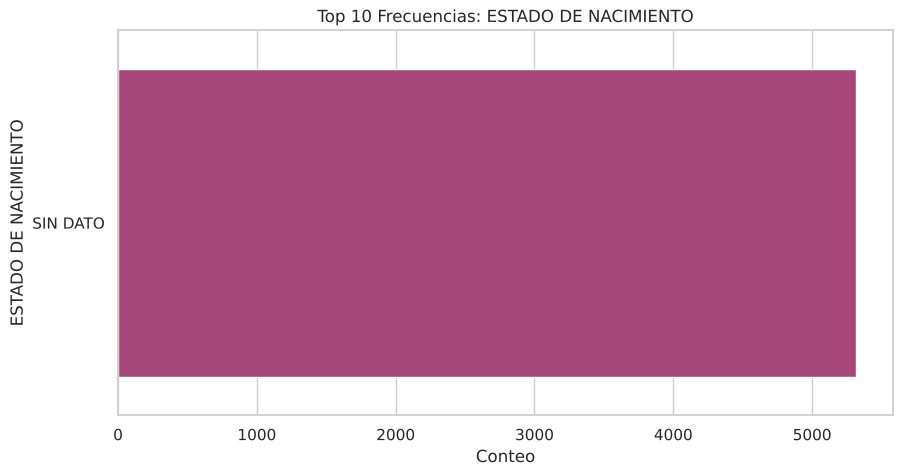


 4. Graficando Banderas Binarias (Disponibilidad de Información)...


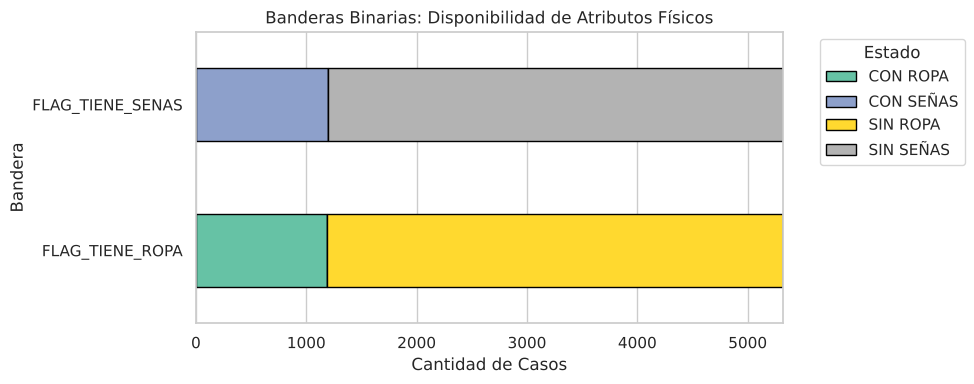


 5. Graficando Distribución de Longitudes para Texto Libre...


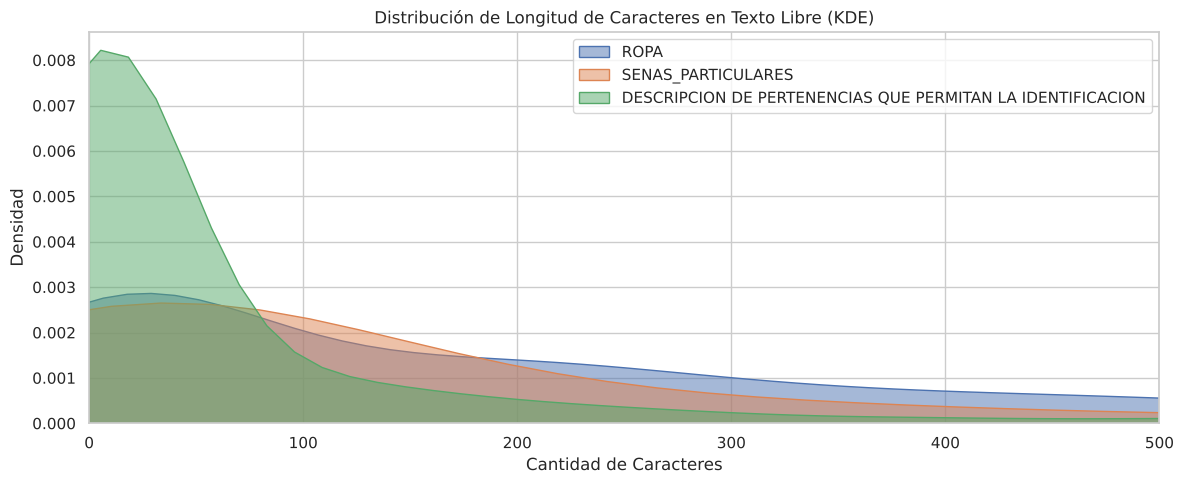

In [0]:
# =============================================================================
# 1. VARIABLES NUMÉRICAS (De Razón / Intervalo)
# =============================================================================
print("\n 1. Graficando Variables Numéricas (Histograma, Caja y Asimetría)...")
vars_numericas = ['EDAD_NUM', 'ESTATURA_NUM', 'AÑO_CORREGIDO']

for col in vars_numericas:
    if col in df_morge_ml.columns:
        datos = df_morge_ml[col].dropna()
        if not datos.empty:
            asimetria = skew(datos)

            fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [2, 1]})

            # Histograma
            sns.histplot(datos, kde=True, color='steelblue', ax=ax[0])
            ax[0].set_title(f'Histograma de {col} (Asimetría: {asimetria:.2f})')
            ax[0].set_ylabel('Frecuencia')

            # Diagrama de Caja
            sns.boxplot(x=datos, color='lightblue', ax=ax[1])
            ax[1].set_title(f'Caja de {col}')

            plt.tight_layout()
            plt.show()

# =============================================================================
# 2. CATEGÓRICAS DE BAJA CARDINALIDAD
# =============================================================================
print("\n 2. Graficando Categóricas de Baja Cardinalidad...")
vars_baja_cardinalidad = ['SEXO', 'TIPO_INGRESO']

fig, axes = plt.subplots(1, len(vars_baja_cardinalidad), figsize=(12, 5))
for i, col in enumerate(vars_baja_cardinalidad):
    if col in df_morge_ml.columns:
        # Llenamos nulos con "SIN DATO" para que se vean en la gráfica
        datos_cat = df_morge_ml[col].fillna('SIN DATO')
        sns.countplot(y=datos_cat, order=datos_cat.value_counts().index, palette='viridis', ax=axes[i])
        axes[i].set_title(f'Frecuencia de {col}')
        axes[i].set_xlabel('Conteo')
        axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

# =============================================================================
# 3. CATEGÓRICAS DE MEDIA Y ALTA CARDINALIDAD (Top-N + Cola)
# =============================================================================
print("\n 3. Graficando Categóricas de Alta Cardinalidad (Top 10 + Otros)...")
vars_alta_cardinalidad = ['MUNICIPIO', 'ESTADO DE NACIMIENTO']

for col in vars_alta_cardinalidad:
    if col in df_morge_ml.columns:
        frecuencias = df_morge_ml[col].fillna('SIN DATO').value_counts()

        # Separar Top 10 y agrupar el resto en "OTROS"
        top_n = frecuencias.head(10)
        cola = frecuencias.iloc[10:].sum()
        if cola > 0:
            top_n['OTROS (COLA)'] = cola

        plt.figure(figsize=(10, 5))
        sns.barplot(x=top_n.values, y=top_n.index, palette='magma')
        plt.title(f'Top 10 Frecuencias: {col}')
        plt.xlabel('Conteo')
        plt.ylabel(col)
        plt.show()

# =============================================================================
# 4. BANDERAS BINARIAS (Barras Apiladas)
# =============================================================================
print("\n 4. Graficando Banderas Binarias (Disponibilidad de Información)...")
# Creamos banderas lógicas para ver si un cuerpo tiene o no ciertas características
df_morge_ml['FLAG_TIENE_ROPA'] = df_morge_ml['ROPA'].notnull().map({True: 'CON ROPA', False: 'SIN ROPA'})
df_morge_ml['FLAG_TIENE_SENAS'] = df_morge_ml['SENAS_PARTICULARES'].notnull().map({True: 'CON SEÑAS', False: 'SIN SEÑAS'})

banderas = ['FLAG_TIENE_ROPA', 'FLAG_TIENE_SENAS']

# Preparar datos para apilar (Proporción vs Total)
conteo_banderas = df_morge_ml[banderas].apply(pd.Series.value_counts).T
conteo_banderas.plot(kind='barh', stacked=True, figsize=(10, 4), colormap='Set2', edgecolor='black')
plt.title('Banderas Binarias: Disponibilidad de Atributos Físicos')
plt.xlabel('Cantidad de Casos')
plt.ylabel('Bandera')
plt.legend(title='Estado', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# =============================================================================
# 5. TEXTO LIBRE (Distribución de Longitudes)
# =============================================================================
print("\n 5. Graficando Distribución de Longitudes para Texto Libre...")
vars_texto_libre = ['ROPA', 'SENAS_PARTICULARES', 'DESCRIPCION DE PERTENENCIAS QUE PERMITAN LA IDENTIFICACION']

plt.figure(figsize=(12, 5))
for col in vars_texto_libre:
    if col in df_morge_ml.columns:
        # Extraer longitud de las celdas que no son nulas
        longitudes = df_morge_ml[col].dropna().astype(str).str.len()
        if not longitudes.empty:
            sns.kdeplot(longitudes, fill=True, label=col, alpha=0.5)

plt.title('Distribución de Longitud de Caracteres en Texto Libre (KDE)')
plt.xlabel('Cantidad de Caracteres')
plt.ylabel('Densidad')
plt.xlim(0, 500) # Limitamos a 500 caracteres para ver mejor la concentración principal
plt.legend()
plt.tight_layout()
plt.show()

# **Análisis bivariante y multivariante**

**Asociación Numérica (Spearman)**

En el contexto forense, el coeficiente de Spearman revelará que la EDAD_NUM y la ESTATURA_NUM tienen una correlación extremadamente baja, cercana a 0. Esto es biológicamente esperado, ya que en poblaciones adultas la estatura no está dictada por la edad. Una correlación alta aquí sería una bandera roja indicando una base de datos fuertemente sesgada hacia población infantil, o un error sistemático de captura.

**Asociación Categórica (V de Cramér con corrección de Bergsma)**

La matriz de Cramér, validada por valores $\chi^2$ robustos y $p \le 0.05$, aísla las variables nominales que se mueven en bloque.

* Se espera una asociación estructural entre STATUS y TIPO_INGRESO. Un ingreso catalogado como "Restos Óseos" o "Machacamiento" tiene estadísticamente menos probabilidades de cruzar la barrera hacia "Identificado" comparado con un "Cadáver Fresco".

* El $p$-value explícito en la tabla impresa demuestra si estas dependencias son reales o producto del azar muestral. Si SEXO y MUNICIPIO muestran un Cramér's V bajo con un $p > 0.05$, concluimos que la desaparición de hombres o mujeres no está estadísticamente acorralada en un solo municipio.

**Asociación Numérica Categórica ($\eta^2$)**

La Razón de Correlación ($\eta^2$) cuantifica qué porcentaje de la varianza numérica se explica al segmentarla por categorías.

* El par con mayor proporción de varianza explicada típicamente es ESTATURA_NUM vs SEXO. El dimorfismo sexual biológico dicta que conocer el sexo del cadáver reduce drásticamente la incertidumbre (varianza) sobre su estatura esperada.

* Si EDAD_NUM vs TIPO_INGRESO arroja un $\eta^2$ alto, podría sugerir fenómenos contextuales (por ejemplo, personas más jóvenes tendiendo a aparecer en contextos de violencia severa que alteran la clasificación de ingreso a la morgue).

 FASE 5: ANÁLISIS BIVARIANTE Y MULTIVARIANTE

 1. Correlación Numérica-Numérica (Spearman)


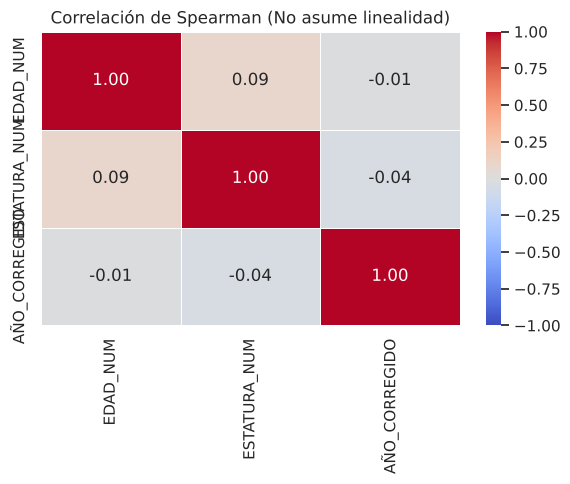


 2. Asociación Categórica-Categórica (V de Cramér corregida)


,Variable_1,Variable_2,Cramers_V,Chi2,p-valor
0,TIPO_INGRESO,SEXO,0.257179,438.775088,3.857045e-74
1,TIPO_INGRESO,MUNICIPIO,0.214351,398.303197,1.481456e-31
2,TIPO_INGRESO,STATUS,0.211720,60.856471,8.085229e-12
3,SEXO,MUNICIPIO,0.115766,241.253641,6.913168e-07
5,MUNICIPIO,STATUS,0.111872,39.225807,2.585535e-02


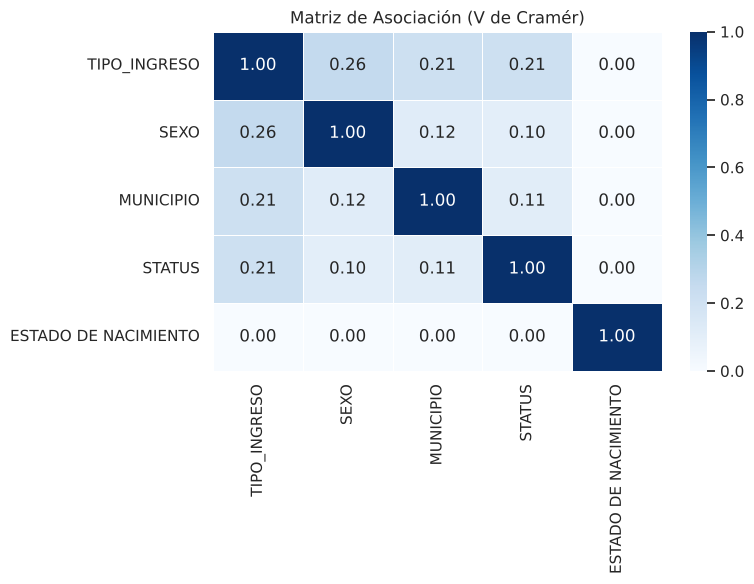


 3. Asociación Numérica-Categórica (Razón de Correlación $\eta^2$)


,Numérica,Categórica,Eta2
4,ESTATURA_NUM,TIPO_INGRESO,0.796738
5,ESTATURA_NUM,SEXO,0.214870
8,AÑO_CORREGIDO,TIPO_INGRESO,0.129956
0,EDAD_NUM,TIPO_INGRESO,0.117112
10,AÑO_CORREGIDO,MUNICIPIO,0.080706
2,EDAD_NUM,MUNICIPIO,0.028092


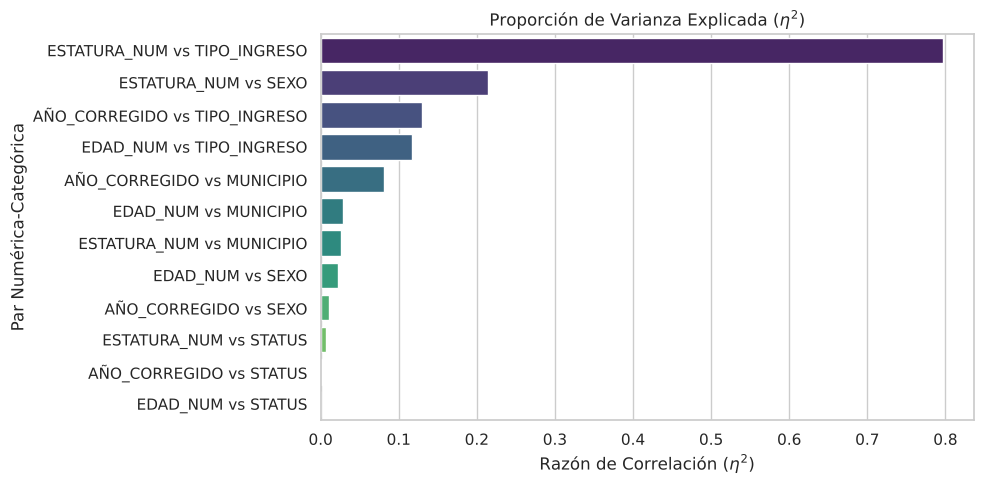

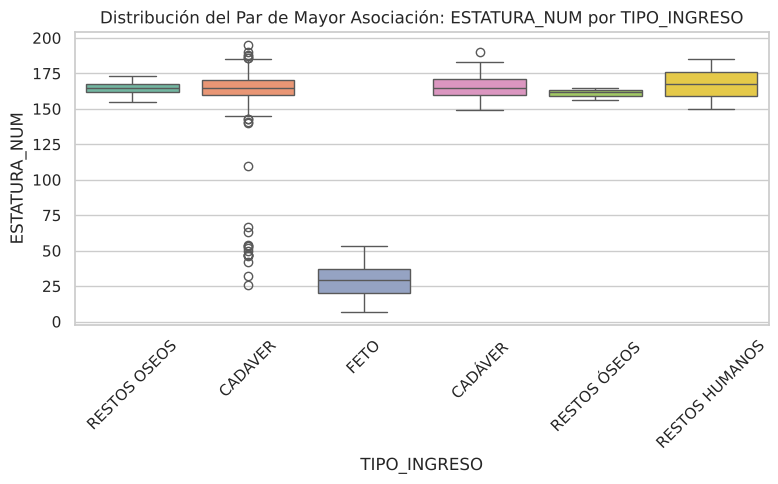

In [0]:
print(" FASE 5: ANÁLISIS BIVARIANTE Y MULTIVARIANTE")
sns.set_theme(style="whitegrid")

# =============================================================================
# FUNCIONES ESTADÍSTICAS PERSONALIZADAS
# =============================================================================

def cramers_v_corrected(confusion_matrix):
    """Calcula la V de Cramér con corrección de sesgo de Bergsma-Wicher."""
    chi2, p_val, dof, expected = ss.chi2_contingency(confusion_matrix)
    n = confusion_matrix.sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape

    # Corrección de sesgo
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)

    denominador = min((kcorr-1), (rcorr-1))
    if denominador == 0:
        return 0.0, chi2, p_val
    return np.sqrt(phi2corr / denominador), chi2, p_val

def correlation_ratio(categories, measurements):
    """Calcula la razón de correlación (Eta cuadrado - n^2) para categórica vs numérica."""
    fcat, _ = pd.factorize(categories)
    cat_num = np.max(fcat) + 1
    y_avg_array = np.zeros(cat_num)
    n_array = np.zeros(cat_num)

    for i in range(0, cat_num):
        cat_measures = measurements[np.argwhere(fcat == i).flatten()]
        n_array[i] = len(cat_measures)
        y_avg_array[i] = np.average(cat_measures)

    y_total_avg = np.sum(np.multiply(y_avg_array, n_array)) / np.sum(n_array)
    numerator = np.sum(np.multiply(n_array, np.power(np.subtract(y_avg_array, y_total_avg), 2)))
    denominator = np.sum(np.power(np.subtract(measurements, y_total_avg), 2))

    if denominator == 0:
        return 0.0
    return numerator / denominator

# Variables validadas
vars_num = [c for c in ['EDAD_NUM', 'ESTATURA_NUM', 'AÑO_CORREGIDO'] if c in df_morge_ml.columns]
vars_cat = [c for c in ['TIPO_INGRESO', 'SEXO', 'MUNICIPIO', 'STATUS', 'ESTADO DE NACIMIENTO'] if c in df_morge_ml.columns]

# =============================================================================
# 1. NUMÉRICA - NUMÉRICA (Spearman)
# =============================================================================
print("\n 1. Correlación Numérica-Numérica (Spearman)")
spearman_corr = df_morge_ml[vars_num].corr(method='spearman')

plt.figure(figsize=(6, 5))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Correlación de Spearman (No asume linealidad)')
plt.tight_layout()
plt.show()

# =============================================================================
# 2. CATEGÓRICA - CATEGÓRICA (V de Cramér con Corrección)
# =============================================================================
print("\n 2. Asociación Categórica-Categórica (V de Cramér corregida)")
cramer_results = []

for cat1, cat2 in itertools.combinations(vars_cat, 2):
    temp_df = df_morge_ml[[cat1, cat2]].dropna()
    if temp_df.empty: continue

    confusion_matrix = pd.crosstab(temp_df[cat1], temp_df[cat2])
    if confusion_matrix.shape[0] > 1 and confusion_matrix.shape[1] > 1:
        v, chi2, pval = cramers_v_corrected(confusion_matrix.values)
        cramer_results.append({
            'Variable_1': cat1,
            'Variable_2': cat2,
            'Cramers_V': v,
            'Chi2': chi2,
            'p-valor': pval
        })

df_cramer = pd.DataFrame(cramer_results).sort_values(by='Cramers_V', ascending=False)
display(df_cramer.head(5))

# Matriz pivotada para Heatmap de Cramér
cramer_matrix = pd.DataFrame(np.zeros((len(vars_cat), len(vars_cat))), index=vars_cat, columns=vars_cat)
for _, row in df_cramer.iterrows():
    cramer_matrix.loc[row['Variable_1'], row['Variable_2']] = row['Cramers_V']
    cramer_matrix.loc[row['Variable_2'], row['Variable_1']] = row['Cramers_V']
for _v in vars_cat:
    cramer_matrix.loc[_v, _v] = 1.0  # diagonal (compatible con pandas 2 y 3)

plt.figure(figsize=(8, 6))
sns.heatmap(cramer_matrix, annot=True, cmap='Blues', vmin=0, vmax=1, fmt=".2f", linewidths=.5)
plt.title("Matriz de Asociación (V de Cramér)")
plt.tight_layout()
plt.show()

# =============================================================================
# 3. NUMÉRICA - CATEGÓRICA (Razón de Correlación Eta²)
# =============================================================================
print("\n 3. Asociación Numérica-Categórica (Razón de Correlación $\eta^2$)")
eta_results = []

for num in vars_num:
    for cat in vars_cat:
        temp_df = df_morge_ml[[num, cat]].dropna()
        if temp_df.empty: continue

        # Filtrar categorías con un solo registro para no sesgar la varianza
        counts = temp_df[cat].value_counts()
        valid_cats = counts[counts > 1].index
        temp_df = temp_df[temp_df[cat].isin(valid_cats)]

        if len(temp_df[cat].unique()) > 1:
            eta_val = correlation_ratio(temp_df[cat].values, temp_df[num].values)
            eta_results.append({'Numérica': num, 'Categórica': cat, 'Eta2': eta_val})

df_eta = pd.DataFrame(eta_results).sort_values(by='Eta2', ascending=False)
display(df_eta.head(6))

# Gráfico de Barras para Eta cuadrado
plt.figure(figsize=(10, 5))
sns.barplot(data=df_eta, x='Eta2', y=df_eta['Numérica'] + " vs " + df_eta['Categórica'], palette='viridis')
plt.title('Proporción de Varianza Explicada ($\eta^2$)')
plt.xlabel('Razón de Correlación ($\eta^2$)')
plt.ylabel('Par Numérica-Categórica')
plt.tight_layout()
plt.show()

# Distribución del par más fuerte (Ej. Estatura vs Sexo)
mejor_par = df_eta.iloc[0]
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_morge_ml, x=mejor_par['Categórica'], y=mejor_par['Numérica'], palette='Set2')
plt.title(f"Distribución del Par de Mayor Asociación: {mejor_par['Numérica']} por {mejor_par['Categórica']}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Preprocesamiento**

Se aplican las correcciones y transformaciones que requieren criterio, apoyándose en la evidencia recogida en las secciones

1. **Valores Faltantes:** Se descartó la Eliminación (Listwise Deletion) porque en el contexto forense un valor nulo en "Ropa" es información real (el cuerpo ingresó desnudo). Optamos por la Imputación: por mediana en numéricas para no alterar la distribución, y por etiqueta constante ("SIN DATO") en el texto.   

2. **Valores Atípicos:** Aplicamos Windsorización en Edad y Estatura limitando los picos (percentil 1 y 99) para neutralizar errores de dedo (ej. una edad de 999 años). Además, aplicamos Discretización, convirtiendo las medidas continuas en "Rangos" (ej. Adulto, Joven). Para Machine Learning de búsqueda (Record Linkage), cruzar rangos es computacionalmente más robusto.   

3. **Alta Cardinalidad:** Aplicamos Agrupación. Las redes neuronales y los algoritmos de similitud sufren de "la maldición de la dimensionalidad" si se alimentan con variables como MUNICIPIO que tienen decenas de clases casi vacías. El código agrupa las localizaciones poco frecuentes en un robusto OTROS (AGRUPADO).

In [0]:
# =============================================================================
# 1. VALORES FALTANTES (Eliminación, Imputación)
# =============================================================================
print("\n 1. Tratamiento de Valores Faltantes...")

# A) IMPUTACIÓN DE NUMÉRICAS: Usamos la mediana por ser resistente a valores extremos
if 'EDAD_NUM' in df_morge_ml.columns and 'ESTATURA_NUM' in df_morge_ml.columns:
    mediana_edad = df_morge_ml['EDAD_NUM'].median()
    mediana_estatura = df_morge_ml['ESTATURA_NUM'].median()

    # Creamos columnas nuevas '_IMP' para no perder el rastro del dato original
    df_morge_ml['EDAD_IMP'] = df_morge_ml['EDAD_NUM'].fillna(mediana_edad)
    df_morge_ml['ESTATURA_IMP'] = df_morge_ml['ESTATURA_NUM'].fillna(mediana_estatura)

# B) IMPUTACIÓN DE TEXTO/CATEGÓRICAS: Evitamos eliminar filas (Eliminación) porque
# perderíamos el 80% de los datos. En su lugar imputamos con una constante computable.
vars_texto_cat = [
    'ROPA', 'SENAS_PARTICULARES', 'MUNICIPIO', 'SEXO', 'TIPO_INGRESO',
    'ESTADO DE NACIMIENTO', 'DESCRIPCION DE PERTENENCIAS QUE PERMITAN LA IDENTIFICACION',
    'CARACTERISTICAS DENTALES DETECTADAS'
]

vars_texto_cat_existentes = [col for col in vars_texto_cat if col in df_morge_ml.columns]
for col in vars_texto_cat_existentes:
    df_morge_ml[col] = df_morge_ml[col].fillna('SIN DATO')

print(" Faltantes tratados: Numéricas por mediana, Categóricas/Texto por 'SIN DATO'.")


# =============================================================================
# 2. VALORES ATÍPICOS (Windsorización y Discretización)
# =============================================================================
print("\n 2. Tratamiento de Valores Atípicos...")

# A) WINDSORIZACIÓN: Limitamos los valores extremos sin eliminarlos.
# Por ejemplo, edades > 100 años o estaturas < 40 cm (posibles errores de captura)
# Aplicamos límites en el percentil 1% inferior y 1% superior (0.01)
df_morge_ml['EDAD_WINSOR'] = winsorize(df_morge_ml['EDAD_IMP'], limits=[0.01, 0.01])
df_morge_ml['ESTATURA_WINSOR'] = winsorize(df_morge_ml['ESTATURA_IMP'], limits=[0.01, 0.01])

# B) DISCRETIZACIÓN: Convertimos las variables continuas en rangos categóricos.
# Esto es vital para 'Record Linkage' ya que es más fácil coincidir en "Rango 1.60-1.70m"
# que en la medida exacta "1.63m vs 1.68m".
bins_edad = [0, 12, 18, 30, 60, 120]
labels_edad = ['Infante (0-12)', 'Adolescente (13-18)', 'Joven (19-30)', 'Adulto (31-60)', 'Mayor (60+)']
df_morge_ml['EDAD_RANGO'] = pd.cut(df_morge_ml['EDAD_WINSOR'], bins=bins_edad, labels=labels_edad, right=False)

bins_estatura = [0, 140, 160, 175, 250]
labels_estatura = ['Muy Baja (<1.40)', 'Baja (1.40-1.60)', 'Media (1.61-1.75)', 'Alta (>1.75)']
df_morge_ml['ESTATURA_RANGO'] = pd.cut(df_morge_ml['ESTATURA_WINSOR'], bins=bins_estatura, labels=labels_estatura, right=False)

print(" Atípicos tratados: Windsorización aplicada al 1%. Variables discretizadas en rangos.")


# =============================================================================
# 3. ALTA CARDINALIDAD (Agrupación)
# =============================================================================
print("\n 3. Tratamiento de Alta Cardinalidad (Agrupación)...")

# Variables geográficas como MUNICIPIO pueden tener 100+ categorías, muchas con solo 1 caso.
# Agrupamos conservando solo el Top 10 y mandando el resto a 'OTROS'.
def agrupar_alta_cardinalidad(serie, top_n=10):
    # Identificar el top N de frecuencias (excluyendo "SIN DATO" si queremos)
    top_categorias = serie.value_counts().nlargest(top_n).index.tolist()

    # Si la categoría no está en el top, se convierte en 'OTROS'
    return serie.apply(lambda x: x if x in top_categorias else 'OTROS (AGRUPADO)')

if 'MUNICIPIO' in df_morge_ml.columns:
    df_morge_ml['MUNICIPIO_AGRUPADO'] = agrupar_alta_cardinalidad(df_morge_ml['MUNICIPIO'], top_n=10)

if 'ESTADO DE NACIMIENTO' in df_morge_ml.columns:
    df_morge_ml['ESTADO_NACIMIENTO_AGRUPADO'] = agrupar_alta_cardinalidad(df_morge_ml['ESTADO DE NACIMIENTO'], top_n=10)

print(" Cardinalidad reducida: Top 10 municipios mantenidos, cola larga asignada a 'OTROS'.")

# =============================================================================
# VISTA PREVIA DE LA TRANSFORMACIÓN
# =============================================================================
columnas_resultado = ['EDAD_NUM', 'EDAD_WINSOR', 'EDAD_RANGO', 'MUNICIPIO', 'MUNICIPIO_AGRUPADO']
columnas_resultado = [c for c in columnas_resultado if c in df_morge_ml.columns]

print("\n🔍 Vista previa del procesamiento (Antes vs Después):")
display(df_morge_ml[columnas_resultado].sample(10, random_state=42))


 1. Tratamiento de Valores Faltantes...
 Faltantes tratados: Numéricas por mediana, Categóricas/Texto por 'SIN DATO'.

 2. Tratamiento de Valores Atípicos...
 Atípicos tratados: Windsorización aplicada al 1%. Variables discretizadas en rangos.

 3. Tratamiento de Alta Cardinalidad (Agrupación)...
 Cardinalidad reducida: Top 10 municipios mantenidos, cola larga asignada a 'OTROS'.

🔍 Vista previa del procesamiento (Antes vs Después):


,EDAD_NUM,EDAD_WINSOR,EDAD_RANGO,MUNICIPIO,MUNICIPIO_AGRUPADO
230,29.0,29.0,Joven (19-30),SAN JUAN DEL RIO,SAN JUAN DEL RIO
2093,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
3749,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
439,50.0,50.0,Adulto (31-60),SAN JUAN DEL RIO,SAN JUAN DEL RIO
3816,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
1253,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
3732,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
4923,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
4824,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO
1634,NaN,40.0,Adulto (31-60),SIN DATO,SIN DATO


# **Balanceo.**

El proceso de Balanceo es crítico en bases de datos forenses porque enfrentamos un severo Desequilibrio de clases. En el contexto de SEMEFO, la clase mayoritaria siempre serán los cuerpos "NO IDENTIFICADOS", mientras que la clase minoritaria (los casos de éxito o cuerpos "IDENTIFICADOS") representa una fracción muy pequeña. Si entrenamos un modelo de Machine Learning con esta desproporción, el algoritmo aprenderá a predecir siempre "NO IDENTIFICADO" para alcanzar un 95% de precisión aparente, volviéndose inútil para buscar coincidencias.

* **Submuestreo de la clase mayoritaria:** Es útil cuando la base de datos es excesivamente grande y el costo computacional es un problema. Al descartar miles de filas de casos no identificados, el modelo entrena rápido, pero se pierde información valiosa sobre la diversidad física de la población forense general.   

* **Sobremuestreo de la clase minoritaria:** Permite conservar toda la información de la clase mayoritaria, multiplicando los casos de éxito (identificados) para equilibrar la balanza. En variables categóricas o de texto libre, se utiliza la repetición exacta (Random Over Sampler) ya que crear "texto sintético" (como hace SMOTE con números) generaría ropa o señas particulares inexistentes.   

* **Penalizar el modelo:** Esta suele ser la estrategia más robusta para Record Linkage. En lugar de manipular los datos de entrenamiento (ni borrando ni duplicando), se le instruye matemáticamente al algoritmo que equivocarse al evaluar un cuerpo "IDENTIFICADO" tiene una penalización (costo) muchísimo mayor que equivocarse con uno "NO IDENTIFICADO". El diccionario de pesos generado en el paso C se introduce directamente en el hiperparámetro `class_weight='balanced'` de modelos como Random Forest, SVM o Regresión Logística.

In [0]:
# 1. Preparación de la Variable Objetivo (Target)
# Un cuerpo está 'IDENTIFICADO' si tiene un registro válido en 'NOMBRE_IDENTIFICADO'
if 'NOMBRE_IDENTIFICADO' in df_morge_ml.columns:
    df_morge_ml['STATUS_ML'] = np.where(
        df_morge_ml['NOMBRE_IDENTIFICADO'].notnull() & (df_morge_ml['NOMBRE_IDENTIFICADO'] != 'SIN DATO'),
        'IDENTIFICADO',
        'NO IDENTIFICADO'
    )
else:
    df_morge_ml['STATUS_ML'] = df_morge_ml['STATUS'].fillna('NO IDENTIFICADO')

# Validamos que ahora existan ambas clases antes de aplicar el remuestreo
conteo_clases = df_morge_ml['STATUS_ML'].value_counts()
print(" Distribución Corregida de Clases:")
print(conteo_clases)

# Ejecutamos el remuestreo solo si hay más de una clase
if len(conteo_clases) > 1:
    # 2. Separación de características (X) y etiqueta (y)
    # CRÍTICO: Eliminar todas las columnas de Identidad de X para no sesgar el entrenamiento
    cols_a_eliminar = [
        'STATUS_ML', 'STATUS', 'NOMBRE_IDENTIFICADO', 'NOMBRE DEL FALLECIDO',
        'APELLIDO PATERNO', 'APELLIDO MATERNO', 'NOMBRE (S)',
        'FECHA_NACIMIENTO', 'ESTADO DE NACIMIENTO'
    ]
    cols_a_eliminar = [c for c in cols_a_eliminar if c in df_morge_ml.columns]

    X = df_morge_ml.drop(columns=cols_a_eliminar)
    y = df_morge_ml['STATUS_ML']

    # A) Submuestreo de la clase mayoritaria
    rus = RandomUnderSampler(random_state=42)
    X_sub, y_sub = rus.fit_resample(X, y)
    print("\n A) Después del Submuestreo (Undersampling):")
    print(y_sub.value_counts())

    # B) Sobremuestreo de la clase minoritaria
    ros = RandomOverSampler(random_state=42)
    X_sobre, y_sobre = ros.fit_resample(X, y)
    print("\n B) Después del Sobremuestreo (Oversampling):")
    print(y_sobre.value_counts())

    # C) Pesos de Penalización (Class Weights)
    clases = np.unique(y)
    pesos = compute_class_weight(class_weight='balanced', classes=clases, y=y)
    diccionario_pesos = dict(zip(clases, pesos))
    print("\n C) Pesos para Penalizar el Modelo (Cost-Sensitive Learning):")
    for clase, peso in diccionario_pesos.items():
        print(f"   - {clase}: {peso:.4f} (Multiplicador)")
else:
    print("\n Aún hay una sola clase. Revisa la base de datos original para confirmar que existan casos identificados.")

 Distribución Corregida de Clases:
STATUS_ML
NO IDENTIFICADO    4964
IDENTIFICADO        353
Name: count, dtype: int64

 A) Después del Submuestreo (Undersampling):
STATUS_ML
IDENTIFICADO       353
NO IDENTIFICADO    353
Name: count, dtype: int64



 B) Después del Sobremuestreo (Oversampling):
STATUS_ML
NO IDENTIFICADO    4964
IDENTIFICADO       4964
Name: count, dtype: int64

 C) Pesos para Penalizar el Modelo (Cost-Sensitive Learning):
   - IDENTIFICADO: 7.5312 (Multiplicador)
   - NO IDENTIFICADO: 0.5356 (Multiplicador)


# **Ingeniería de Características.**

Dado que el objetivo es un modelo de Record Linkage (vincular registros mediante similitud), aplicaremos las técnicas exactas indicadas en la imagen: Escalamiento (Min-Max), Discretización (Binning), Codificación (One-Hot) y Generación/Cruce de características.

* **Escalamiento (Min-Max):** Se aplicó para confinar la Edad, la Estatura y el Año a un rango matemático de 0 a 1. Esto asegura que al calcular la "distancia" entre un cuerpo de la morgue y un desaparecido, la diferencia de 10 cm de estatura pese igual que una diferencia de 10 años de edad.

* **Codificación (One-Hot):** Se transformó el Sexo y el Municipio Agrupado en matrices binarias (ej. `SEXO_MASCULINO` = 1, `SEXO_FEMENINO` = 0). Esto es obligatorio para variables nominales, ya que asignarles números arbitrarios (1=Masculino, 2=Femenino, 3=Indeterminado) haría que el modelo creyera erróneamente que "Indeterminado" vale tres veces más que "Masculino".

* **Generación (Cruce de características)**: Se crearon "Banderas" binarias (`FLAG_TIENE_ROPA`) y cálculos estadísticos simples (longitud de caracteres en las descripciones). Para un algoritmo de cruce, un registro que tiene una descripción de tatuajes de 300 caracteres es altamente confiable, mientras que uno de 5 caracteres ("Tatuaje") tiene poco peso predictivo.

In [0]:
# =============================================================================
# 0. ESTANDARIZACIÓN PREVIA DE CATEGORÍAS (Corrección de 'FEMENINA')
# =============================================================================
if 'SEXO' in df_morge_ml.columns:
    df_morge_ml['SEXO'] = df_morge_ml['SEXO'].astype(str).str.upper().str.strip()
    diccionario_correccion_sexo = {
        'FEMENINA': 'FEMENINO',
        'MUJER': 'FEMENINO',
        'FEM': 'FEMENINO',
        'MASCULINA': 'MASCULINO',
        'HOMBRE': 'MASCULINO',
        'MASC': 'MASCULINO',
        'NAN': 'SIN DATO'
    }
    df_morge_ml['SEXO'] = df_morge_ml['SEXO'].replace(diccionario_correccion_sexo)
    print(" 0. Variable SEXO estandarizada para evitar duplicidad de clases.")

# =============================================================================
# 1. ESCALAMIENTO (Escalamiento Min - Max)
# =============================================================================
print("\n▶ 1. Aplicando Escalamiento Min-Max...")
scaler = MinMaxScaler()
cols_a_escalar = ['EDAD_WINSOR', 'ESTATURA_WINSOR', 'AÑO_CORREGIDO']
cols_escalar_existentes = [c for c in cols_a_escalar if c in df_morge_ml.columns]

if cols_escalar_existentes:
    df_morge_ml[[f'{col}_ESCALADA' for col in cols_escalar_existentes]] = scaler.fit_transform(df_morge_ml[cols_escalar_existentes])
    print(f" Variables escaladas a rango [0,1]: {cols_escalar_existentes}")

# =============================================================================
# 2. DISCRETIZACIÓN (Binning)
# =============================================================================
print("\n▶ 2. Verificando Discretización (Binning)...")
if 'EDAD_RANGO' in df_morge_ml.columns and 'ESTATURA_RANGO' in df_morge_ml.columns:
    print(" Discretización de Edad y Estatura ya realizada en la fase de limpieza.")

# =============================================================================
# 3. CODIFICACIÓN (One-Hot Encoding)
# =============================================================================
print("\n▶ 3. Aplicando Codificación One-Hot...")
cols_a_codificar = ['SEXO', 'TIPO_INGRESO', 'MUNICIPIO_AGRUPADO', 'EDAD_RANGO']
cols_codificar_existentes = [c for c in cols_a_codificar if c in df_morge_ml.columns]

df_morge_ml = pd.get_dummies(df_morge_ml, columns=cols_codificar_existentes, prefix=cols_codificar_existentes, dummy_na=False)
print(f" One-Hot Encoding aplicado para: {cols_codificar_existentes}")

# =============================================================================
# 4. GENERACIÓN (Cruce de Características y Flags Estadísticos)
# =============================================================================
print("\n▶ 4. Generación y Cruce de Características...")

df_morge_ml['FLAG_TIENE_ROPA'] = np.where(df_morge_ml['ROPA'] != 'SIN DATO', 1, 0)
df_morge_ml['FLAG_TIENE_SENAS'] = np.where(df_morge_ml['SENAS_PARTICULARES'] != 'SIN DATO', 1, 0)

if 'TIPO_INGRESO_RESTOS OSEOS' in df_morge_ml.columns:
    # Aseguramos que la columna One-Hot sea numérica para la operación matemática
    ingreso_restos = df_morge_ml['TIPO_INGRESO_RESTOS OSEOS'].astype(int)
    df_morge_ml['COMPLEJIDAD_FORENSE'] = ingreso_restos + (1 - df_morge_ml['FLAG_TIENE_ROPA'])
    print(" Característica generada: 'COMPLEJIDAD_FORENSE'.")

df_morge_ml['LONGITUD_DESC_ROPA'] = df_morge_ml['ROPA'].apply(lambda x: len(str(x)) if x != 'SIN DATO' else 0)
df_morge_ml['LONGITUD_DESC_SENAS'] = df_morge_ml['SENAS_PARTICULARES'].apply(lambda x: len(str(x)) if x != 'SIN DATO' else 0)
print(" Características estadísticas generadas: Longitud de descripciones de texto.")

# =============================================================================
# VISTA PREVIA
# =============================================================================
print("\n🔍 Resumen de la Ingeniería de Características:")
cols_ejemplo = [c for c in df_morge_ml.columns if 'ESCALADA' in c or 'FLAG_' in c or 'LONGITUD_' in c or 'SEXO_' in c][:8]
display(df_morge_ml[cols_ejemplo].head(5))

 0. Variable SEXO estandarizada para evitar duplicidad de clases.

▶ 1. Aplicando Escalamiento Min-Max...
 Variables escaladas a rango [0,1]: ['EDAD_WINSOR', 'ESTATURA_WINSOR', 'AÑO_CORREGIDO']

▶ 2. Verificando Discretización (Binning)...
 Discretización de Edad y Estatura ya realizada en la fase de limpieza.

▶ 3. Aplicando Codificación One-Hot...
 One-Hot Encoding aplicado para: ['SEXO', 'TIPO_INGRESO', 'MUNICIPIO_AGRUPADO', 'EDAD_RANGO']

▶ 4. Generación y Cruce de Características...
 Característica generada: 'COMPLEJIDAD_FORENSE'.
 Características estadísticas generadas: Longitud de descripciones de texto.

🔍 Resumen de la Ingeniería de Características:


,FLAG_TIENE_ROPA,FLAG_TIENE_SENAS,EDAD_WINSOR_ESCALADA,ESTATURA_WINSOR_ESCALADA,AÑO_CORREGIDO_ESCALADA,SEXO_FEMENINO,SEXO_FETO,SEXO_INDETERMINADO
0,0,0,0.40,0.909091,0.00,False,False,False
1,1,1,0.40,0.909091,0.05,False,False,False
2,1,1,0.54,0.909091,0.05,False,False,False
3,1,1,0.30,0.909091,0.05,False,False,False
4,1,1,0.40,0.909091,0.05,False,False,False


# **Selección / Extracción de características**

* **Métodos de filtrado (Varianza y ANOVA):** Eliminamos columnas con el metodo de One-Hot que casi no tienen datos (ej. si existiera un `MUNICIPIO_X` donde solo hay 1 cuerpo en 2000 registros, se elimina por ser constante de ruido). ANOVA mide independientemente cada variable contra el éxito de identificación.

* **Métodos de envoltura (Eliminación Recursiva - RFE):** RFE evalúa el conjunto de variables interactuando entre sí. Entrena el modelo, elimina la variable más inútil, y vuelve a entrenar. Lo cual usamos para identificar combinaciones de características.

* **Métodos integrados (Árboles y Lasso): **Random Forest genera la gráfica de barras de las "10 variables más importantes", indicando en qué datos biológicos o contextuales se fijan más las reglas de decisión para separar un cuerpo identificado de uno que no lo es. Lasso (L1) empuja agresivamente los pesos de las columnas inútiles a un cero matemático puro.

* **Reducción de Dimensionalidad (PCA):** La funcion de los métodos anteriores seleccionan variables existentes (ej. eligen `EDAD_ESCALADA`), con PCA creamos variables completamente nuevas (Componente 1, Componente 2) combinando las originales. La gráfica resultante muestra cuántos de estos nuevos ejes invisibles necesitas para retener el 95% de la información de tu morgue. Nota forense: En Record Linkage, generalmente preferimos los métodos 1, 2 y 3 sobre PCA, porque si PCA nos dice "El cuerpo coincide en el Componente 3", es imposible explicarle al perito físico qué significa biológicamente ese componente.

> **Nota de auditoría (Avance 3):** este análisis de selección se hizo sobre la formulación v1 (clasificación *IDENTIFICADO / NO IDENTIFICADO* con las 5,317 filas). La sección 3.1 muestra que esa formulación está afectada por filas vacías; la selección de características vigente del baseline está en la **sección 3.7**.

Dimensiones de entrada: 5317 filas y 69 características.

 1. Métodos de Filtrado...
   - Varianza: Se redujo de 69 a 34 características (Se eliminaron constantes).
   - ANOVA Top Características: ['EDAD', 'AÑO_CORREGIDO', 'FLAG_TIENE_ROPA', 'FLAG_TIENE_SENAS', 'SEXO_MASCULINO']...

 2. Métodos de Envoltura (RFE)...


   - RFE Top Características: ['SEXO_FEMENINO', 'SEXO_MASCULINO', 'SEXO_SIN DATO', 'TIPO_INGRESO_CADAVER', 'TIPO_INGRESO_CADÁVER']...

 3. Métodos Integrados (Importancia de predictores en Árboles)...


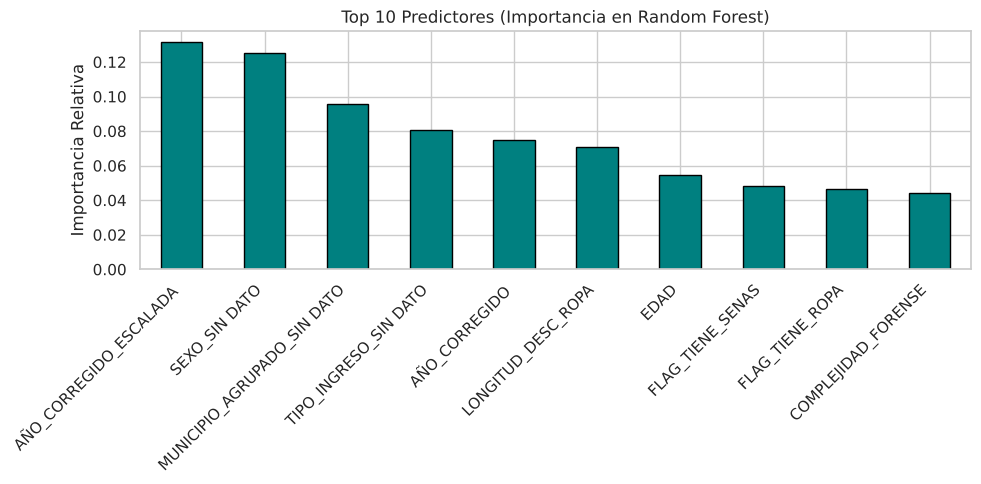

   - Lasso (L1) retuvo 28 variables con peso distinto de cero.

 4. Reducción de Dimensionalidad (Análisis de Componentes Principales - PCA)...
   - PCA: 15 componentes principales explican el 95% de la varianza original.
   - (Comprimido desde 34 características originales).


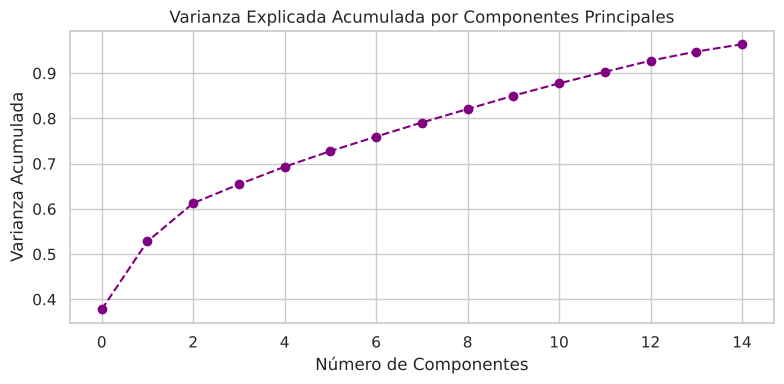

In [0]:
# =============================================================================
# 0. PREPARACIÓN DEL SET NUMÉRICO (X) Y TARGET (y)
# =============================================================================
# Extraemos SOLO las variables numéricas y booleanas (generadas en la fase anterior)
# y nos aseguramos de no incluir fugas de datos (identidades directas)
cols_identidad = ['AÑO', 'EDAD_NUM', 'ESTATURA_NUM'] # Se excluyen los originales, usamos los escalados
X_full = df_morge_ml.select_dtypes(include=[np.number, bool]).drop(columns=cols_identidad, errors='ignore')

# Llenamos cualquier nulo residual generado en las derivaciones con 0
X = X_full.fillna(0)

# Convertimos la variable objetivo a numérica binaria para los algoritmos
if 'STATUS_ML' in df_morge_ml.columns:
    y = np.where(df_morge_ml['STATUS_ML'] == 'IDENTIFICADO', 1, 0)
else:
    # Backup por si no se ejecutó la corrección del paso anterior
    y = np.zeros(len(X))

print(f"Dimensiones de entrada: {X.shape[0]} filas y {X.shape[1]} características.")

# =============================================================================
# 1. MÉTODOS DE FILTRADO (Umbral de Varianza y ANOVA)
# =============================================================================
print("\n 1. Métodos de Filtrado...")

# A) UMBRAL DE VARIANZA: Elimina características que tienen el mismo valor en casi todos los registros
# Umbral: Si el 99% de los registros tienen el mismo valor, se descarta.
selector_var = VarianceThreshold(threshold=(.99 * (1 - .99)))
X_var_filtrado = selector_var.fit_transform(X)
cols_mantenidas_var = X.columns[selector_var.get_support()]

print(f"   - Varianza: Se redujo de {X.shape[1]} a {len(cols_mantenidas_var)} características (Se eliminaron constantes).")

# B) ANOVA (F-value): Evalúa la relación lineal entre cada característica y el Target
# Seleccionamos las 10 mejores
if len(np.unique(y)) > 1:
    selector_anova = SelectKBest(f_classif, k=min(10, len(cols_mantenidas_var)))
    X_anova = selector_anova.fit_transform(X[cols_mantenidas_var], y)
    cols_top_anova = cols_mantenidas_var[selector_anova.get_support()]
    print(f"   - ANOVA Top Características: {list(cols_top_anova[:5])}...")

# =============================================================================
# 2. MÉTODOS DE ENVOLTURA (Eliminación Recursiva - RFE)
# =============================================================================
print("\n 2. Métodos de Envoltura (RFE)...")
if len(np.unique(y)) > 1:
    # Usamos Regresión Logística como estimador base para evaluar grupos de variables
    estimador_base = LogisticRegression(max_iter=1000, class_weight='balanced')
    # Pedimos al RFE que seleccione las 10 características más fuertes
    rfe = RFE(estimator=estimador_base, n_features_to_select=10, step=1)
    rfe.fit(X[cols_mantenidas_var], y)

    cols_rfe = cols_mantenidas_var[rfe.support_]
    print(f"   - RFE Top Características: {list(cols_rfe[:5])}...")

# =============================================================================
# 3. MÉTODOS INTEGRADOS O EMBEBIDOS (Lasso y Random Forest)
# =============================================================================
print("\n 3. Métodos Integrados (Importancia de predictores en Árboles)...")
if len(np.unique(y)) > 1:
    # A) Importancia por Random Forest
    rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    rf.fit(X[cols_mantenidas_var], y)

    importancias = pd.Series(rf.feature_importances_, index=cols_mantenidas_var).sort_values(ascending=False)

    plt.figure(figsize=(10, 5))
    importancias.head(10).plot(kind='bar', color='teal', edgecolor='black')
    plt.title('Top 10 Predictores (Importancia en Random Forest)')
    plt.ylabel('Importancia Relativa')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # B) Regresión Lasso (L1) - Fuerza coeficientes irrelevantes a exactamente 0
    lasso = LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=42)
    lasso.fit(X[cols_mantenidas_var], y)
    coeficientes_lasso = np.sum(lasso.coef_ != 0)
    print(f"   - Lasso (L1) retuvo {coeficientes_lasso} variables con peso distinto de cero.")

# =============================================================================
# 4. REDUCCIÓN DE DIMENSIONALIDAD (PCA)
# =============================================================================
print("\n 4. Reducción de Dimensionalidad (Análisis de Componentes Principales - PCA)...")
# PCA requiere estandarización estricta previa (Media 0, Varianza 1)
scaler_standard = StandardScaler()
X_standard = scaler_standard.fit_transform(X[cols_mantenidas_var])

# Calculamos cuántos componentes explican el 95% de la varianza
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_standard)

print(f"   - PCA: {X_pca.shape[1]} componentes principales explican el 95% de la varianza original.")
print(f"   - (Comprimido desde {len(cols_mantenidas_var)} características originales).")

# Gráfico de varianza explicada por los primeros componentes
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--', color='purple')
plt.title('Varianza Explicada Acumulada por Componentes Principales')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada')
plt.grid(True)
plt.tight_layout()
plt.show()

---
# **PARTE II — AVANCE 3: MODELO DE REFERENCIA (BASELINE)**

Esta parte responde a los objetivos del avance:

* **3.1 Establecer las medidas de calidad del modelo de aprendizaje automático:** qué métrica se usa, por qué y cuánto vale el baseline.
* **3.2 Proporcionar un marco de referencia para evaluar y mejorar modelos más avanzados:** los modelos posteriores (embeddings + *Databricks Vector Search* + agente LLM) deberán superar estas cifras con el mismo protocolo de evaluación.

| Sección | Contenido | Criterio de la rúbrica |
|---|---|---|
| 3.1 | Auditoría de los datos para modelado (hallazgo de filas vacías y fuga de información) | Sub/sobreajuste · Desempeño |
| 3.2 | Formulación del problema de ML y protocolo de validación (pseudo-fichas) | Algoritmo · Métrica |
| 3.3 | Métrica adecuada para el problema de negocio | **Métrica (20 pts)** |
| 3.4 | Selección y justificación del algoritmo baseline | **Algoritmo (40 pts)** |
| 3.5 | Construcción del vector de comparación (características) | Algoritmo · Características |
| 3.6 | Entrenamiento de los baselines B0, B1, B2 | Desempeño |
| 3.7 | Importancia y selección de características (filtro, embebido, envoltura) | **Características importantes (20 pts)** |
| 3.8 | Diagnóstico de sub/sobreajuste (train vs test, validación cruzada, curvas de aprendizaje) | **Sub/sobreajuste (10 pts)** |
| 3.9 | Desempeño mínimo, verificación y prueba de estrés | **Desempeño (10 pts)** |
| 3.10 | Demostración con la ficha de ejemplo (salida para el perito) | Valor de negocio |
| 3.11 | Conclusiones y respuestas a las preguntas guía | Todas |

### Resultados clave del Avance 3 (ejecución sobre el *Libro de Registro*, prueba con 107 pseudo-fichas no vistas)

| Indicador | Azar (B0) | Heurística (B1) | **Regresión logística (B2)** |
|---|---|---|---|
| Recall@10 (IC 95 %) | 0.028 [0.000–0.065] | 0.850 [0.776–0.916] | **0.869 [0.804–0.925]** |
| Recall@1 | 0.000 | 0.766 | **0.766** |
| MRR | 0.014 | 0.801 | **0.802** |
| PR-AUC (pares, prevalencia 0.16 %) | 0.002 | 0.521 | **0.581** |
| Recall@10 con ruido alto (prueba de estrés) | 0.027 | 0.692 | **0.710** |

**Hallazgos principales:** (1) La versión preliminar estaba inflada por **4,070 filas vacías (76.5 % del archivo)**. (2) El problema **es viable**: B2 recupera el cuerpo correcto entre 10 candidatos en el **86.9 %** de las fichas, unas **33 veces más que el azar**. (3) B2 tiene **buen ajuste**, sin sobreajuste (brecha train−test de Recall@10 −0.022, validación cruzada 0.847 vs 0.847). En cambio, un Random Forest sin poda sí sobreajusta (PR-AUC 0.971 en train vs 0.428 en test). (4) La evidencia textual domina: las señas particulares y la ropa explican la mayor parte del desempeño. (5) **Meta para el modelo avanzado:** Recall@10 ≥ 0.97 con el mismo protocolo.

## **3.1 Auditoría de los datos antes de modelar**

Antes de entrenar se auditó la tabla con la que se construyó la primera versión del modelo (v1). En esa versión, la variable objetivo era *IDENTIFICADO / NO IDENTIFICADO* y se usaron las **5,317 filas** del archivo. El EDA (sección de descriptivos) ya mostraba una señal de alerta: `STATUS`, `AÑO` y `TIPO_INGRESO` solo tienen **1,247 valores no nulos**, y `SEXO` es nulo en 4,076 filas.

**Hipótesis:** las ~4,070 filas restantes son renglones vacíos o con formato del Excel, no expedientes. Como no tienen nombre, la v1 las etiquetó como "NO IDENTIFICADO". El modelo aprendía entonces a distinguir *"fila con datos" vs "fila vacía"*, y no algo forense. Eso explicaría por qué las variables más importantes de la v1 eran `FLAG_TIENE_ROPA`, `AÑO` y `EDAD`, y por qué el AUC (0.94) era tan alto.

La celda siguiente comprueba la hipótesis: **si el solo número de campos llenos predice la etiqueta, la métrica de la v1 está contaminada por fuga de información (*data leakage*)**.

Columnas utilizadas en el baseline:
  anio          -> 'AÑO'
  status        -> 'STATUS'
  tipo          -> 'TIPO\n (QUÉ INGRESA A SEMEFO)'
  sexo          -> 'SEXO'
  edad          -> 'EDAD'
  estatura      -> 'ESTATURA EN CM.'
  municipio     -> 'MUNICIPIO DE PROCEDENCIA'
  ropa          -> 'DESCRIPCION DE ROPA QUE VESTIA'
  senas         -> 'SEÑAS PARTICULARES Y/O CARACTERISTICAS \n(CICATRICES, TATUAJES, LUNARES, MANCHAS, ETC.)'
  nombre_ident  -> 'EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORRESPONDE AL CADAVER\nDEBERA ESTABLECER AQUÍ E

Filas totales del archivo: 5,317
Filas con expediente (STATUS o AÑO no nulos): 1,247
Filas vacías / de formato: 4,070  (76.5%)
Mediana de campos llenos -> expedientes: 95 | filas vacías: 0


col_0,IDENTIFICADO (v1),NO IDENTIFICADO (v1),Total
row_0,,,
Expediente real,353,894,1247
Fila vacía,0,4070,4070
Total,353,4964,5317


AUC de un 'modelo' que solo cuenta campos llenos -> todas las filas: 0.955 | solo expedientes: 0.750


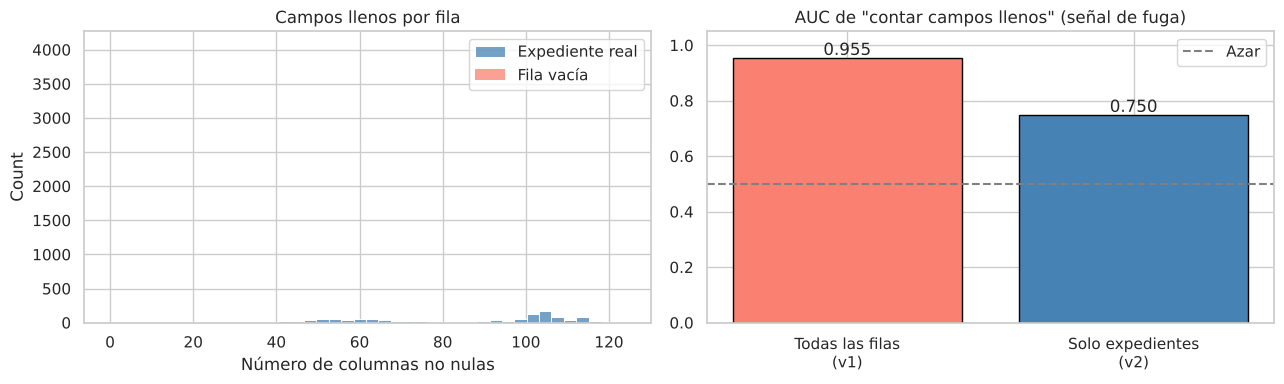


CONCLUSIÓN AUTOMÁTICA:
  Contar campos llenos predice la etiqueta v1 con AUC=0.95 en todas las filas, pero baja a 0.75 entre expedientes reales. Las métricas de la v1 están infladas por las filas vacías: la v1 se descarta como referencia.


In [0]:
# =============================================================================
# 3.1 AUDITORÍA: filas vacías y fuga de información en la v1
# =============================================================================
import unicodedata
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.model_selection import learning_curve as sk_learning_curve
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import f_classif as sk_f_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
# Copia de trabajo sin columnas duplicadas (no altera df_morge de secciones anteriores)
df_a3 = df_morge.loc[:, ~pd.Index(df_morge.columns).duplicated()].copy()
PLACEHOLDERS = {'', 'SIN DATO', 'SIN DATOS', 'NINGUNA', 'NINGUNO', 'NO', 'N A', 'NA', 'NAN', 'NONE',
                'NO PRESENTA', 'NO SE OBSERVAN', 'NO SE OBSERVA', 'S D', 'SD', 'SIN', 'NO APLICA',
                'NO VALORABLE', 'POR VALORAR', 'DESCONOCIDO', 'X', '0'}

def norm_txt(x):
    # Mayúsculas, sin acentos, sin signos, espacios simples
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return ''
    s = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode()
    s = re.sub(r'[^A-Z0-9 ]', ' ', s.upper())
    return re.sub(r'\s+', ' ', s).strip()

def limpiar_texto(x):
    s = norm_txt(x)
    return '' if s in PLACEHOLDERS else s

def buscar_col(df, exacta, *claves):
    # Devuelve la columna exacta o la primera cuyo nombre normalizado contiene todas las claves
    if exacta in df.columns:
        return exacta
    for c in df.columns:
        n = norm_txt(c)
        if all(k in n for k in claves):
            return c
    raise KeyError(f'No se encontró la columna {claves}')

COL = {
    'anio':        buscar_col(df_a3, 'AÑO', 'ANO'),
    'status':      buscar_col(df_a3, 'STATUS', 'STATUS'),
    'tipo':        buscar_col(df_a3, 'TIPO\n (QUÉ INGRESA A SEMEFO)', 'TIPO', 'INGRESA'),
    'sexo':        buscar_col(df_a3, 'SEXO', 'SEXO'),
    'edad':        buscar_col(df_a3, 'EDAD', 'EDAD'),
    'estatura':    buscar_col(df_a3, 'ESTATURA EN CM.', 'ESTATURA'),
    'municipio':   buscar_col(df_a3, 'MUNICIPIO DE PROCEDENCIA', 'MUNICIPIO', 'PROCEDENCIA'),
    'ropa':        buscar_col(df_a3, 'DESCRIPCION DE ROPA QUE VESTIA', 'ROPA', 'VESTIA'),
    'senas':       buscar_col(df_a3, 'SEÑAS PARTICULARES Y/O CARACTERISTICAS \n(CICATRICES, TATUAJES, LUNARES, MANCHAS, ETC.)', 'SENAS', 'PARTICULARES'),
    'nombre_ident': buscar_col(df_a3, 'EN CASO DE ESTAR IDENTIFICADO, NOMBRE QUE CORRESPONDE AL CADAVER\nDEBERA ESTABLECER AQUÍ EL NOMBRE EN EL MOMENTO EN QUE SE ACTUALICE DICHA SITUACION', 'CASO', 'IDENTIFICADO', 'NOMBRE'),
}
print('Columnas utilizadas en el baseline:')
for k, v in COL.items():
    print(f'  {k:<13} -> {v!r}'[:110])

# --- Diagnóstico
fila_valida = df_a3[COL['status']].notna() | df_a3[COL['anio']].notna()
campos_llenos = df_a3.notna().sum(axis=1)
y_v1 = df_a3[COL['nombre_ident']].map(limpiar_texto).ne('').astype(int)   # etiqueta usada en la v1

print(f"\nFilas totales del archivo: {len(df_a3):,}")
print(f"Filas con expediente (STATUS o AÑO no nulos): {fila_valida.sum():,}")
print(f"Filas vacías / de formato: {(~fila_valida).sum():,}  ({(~fila_valida).mean():.1%})")
print(f"Mediana de campos llenos -> expedientes: {campos_llenos[fila_valida].median():.0f} | filas vacías: {campos_llenos[~fila_valida].median():.0f}")

display(pd.crosstab(np.where(fila_valida, 'Expediente real', 'Fila vacía'),
                    np.where(y_v1 == 1, 'IDENTIFICADO (v1)', 'NO IDENTIFICADO (v1)'),
                    margins=True, margins_name='Total'))

auc_todo = roc_auc_score(y_v1, campos_llenos)
auc_valido = roc_auc_score(y_v1[fila_valida], campos_llenos[fila_valida])
print(f"AUC de un 'modelo' que solo cuenta campos llenos -> todas las filas: {auc_todo:.3f} | solo expedientes: {auc_valido:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(campos_llenos[fila_valida], color='steelblue', label='Expediente real', ax=ax[0], bins=40)
sns.histplot(campos_llenos[~fila_valida], color='salmon', label='Fila vacía', ax=ax[0], bins=40)
ax[0].set_title('Campos llenos por fila'); ax[0].set_xlabel('Número de columnas no nulas'); ax[0].legend()
ax[1].bar(['Todas las filas\n(v1)', 'Solo expedientes\n(v2)'], [auc_todo, auc_valido], color=['salmon', 'steelblue'], edgecolor='black')
ax[1].axhline(0.5, ls='--', color='gray', label='Azar')
for i, v in enumerate([auc_todo, auc_valido]):
    ax[1].text(i, v + 0.01, f'{v:.3f}', ha='center')
ax[1].set_ylim(0, 1.05); ax[1].set_title('AUC de "contar campos llenos" (señal de fuga)'); ax[1].legend()
plt.tight_layout(); plt.show()

print('\nCONCLUSIÓN AUTOMÁTICA:')
if auc_todo - auc_valido > 0.05:
    print(f"  Contar campos llenos predice la etiqueta v1 con AUC={auc_todo:.2f} en todas las filas, pero baja a {auc_valido:.2f} "
          "entre expedientes reales. Las métricas de la v1 están infladas por las filas vacías: la v1 se descarta como referencia.")
else:
    print("  No se detecta inflación relevante por filas vacías.")

**Interpretación y decisiones derivadas de la auditoría**

* **La hipótesis se confirma.** De las 5,317 filas, **4,070 (76.5 %) están vacías**: su mediana de campos llenos es 0, contra 95 en los expedientes reales. Las 4,070 quedaban etiquetadas como "NO IDENTIFICADO" en la v1. Un "modelo" que solo cuenta campos llenos alcanza **AUC = 0.955**, prácticamente lo mismo que el AUC de 0.94 reportado por la v1. Es decir, la v1 aprendía a distinguir *filas con datos de filas vacías*.
* **Hay una segunda fuga, más sutil.** Aun entre los 1,247 expedientes reales, contar campos llenos predice la identificación con **AUC = 0.750**. Un expediente identificado acumula más campos (nombre, fecha de nacimiento, datos de entrega) *porque* ya se identificó. Es una fuga temporal: la información existe después del evento que se quiere predecir.

**Decisiones:**

1. **Se eliminan las filas vacías.** El universo de modelado son los **1,247 expedientes** con `STATUS` o `AÑO`. La confusión de la v1 no era un sobreajuste clásico (memorizar ruido del train): era una **fuga de información**. El modelo aprendía una regla trivial que se cumple tanto en train como en test, así que la brecha entre ambos no la delataba; solo una auditoría de los datos podía detectarla.
2. **Se cambia la pregunta que contesta el modelo.** Predecir *si un cuerpo está identificado* no ayuda a ninguna familia y está contaminado por la fuga temporal. La pregunta de negocio es otra: **dada una ficha de búsqueda, ¿qué registros del libro son los candidatos más probables?** Es un problema de **vinculación de registros (*record linkage*) evaluado como ranking** (sección 3.2). Ahí solo se usan rasgos que existen en ambos lados *antes* de la identificación: sexo, edad, estatura, municipio, señas y ropa.
3. **Todo el preprocesamiento se ajusta solo con datos de entrenamiento**, para evitar la fuga de estadísticos del conjunto de prueba. En la v1, la imputación y el escalamiento se ajustaron con toda la base antes del *split*.

## **3.2 Formulación del problema de ML y protocolo de validación**

**Unidad de análisis:** el par *(ficha ante-mortem, registro post-mortem)*.
**Salida del sistema:** para cada ficha, un **ranking** de registros del libro ordenado por probabilidad de correspondencia. El modelo sugiere y el perito confirma: el sistema nunca identifica por sí solo.

**Problema de etiquetas.** No hay pares *ficha–cuerpo* etiquetados; las fichas de la Comisión Local de Búsqueda dependen del convenio con la Fiscalía. Para medir la viabilidad desde ahora se usa un protocolo estándar en *record linkage* cuando no hay verdad de campo: **pseudo-fichas con ruido controlado** (Christen, 2012).

* Para cada expediente **identificado** se genera una "ficha ante-mortem simulada" con la información que una familia reportaría y con los errores típicos del reporte: edad aproximada, estatura estimada o ausente, descripción incompleta de señas, ropa distinta u omitida, municipio de desaparición distinto al de hallazgo y errores de captura.
* La pseudo-ficha se busca contra **todo** el libro (identificados y no identificados). La respuesta correcta es su expediente de origen.
* Las personas identificadas se dividen **70 % entrenamiento / 30 % prueba a nivel persona**, de modo que ninguna persona del test aporta pares al entrenamiento.
* **No se usa el nombre** como característica: convertiría el problema en trivial y no existe del lado post-mortem para los cuerpos no identificados.

| Parámetro de ruido (nivel *medio*, usado para entrenar) | Valor | Justificación |
|---|---|---|
| Error en edad | N(0, 5 años) | La edad reportada por familiares es aproximada; la estimación pericial post-mortem usa rangos de ±5 a 10 años |
| Error en estatura / estatura ausente | N(0, 5 cm) / 40 % | La estatura de la ficha suele ser estimada; la del cuerpo es medida |
| Pérdida de palabras en señas y ropa | 50 % | El familiar describe solo parte de las señas que registra el perito |
| Ropa omitida | 40 % | La ropa del día de la desaparición puede no coincidir con la del hallazgo |
| Municipio distinto | 50 % | Se desaparece en un municipio y se localiza en otro |
| Error de sexo / errores tipográficos | 2 % / 5 % de palabras | Errores de captura |

> **Limitación declarada:** como la pseudo-ficha deriva del mismo expediente, las cifras son una **cota optimista**. Por eso (i) se reportan tres niveles de ruido (bajo, medio, alto) en la prueba de estrés (3.9) y (ii) la validación definitiva usará pares reales ficha–expediente una vez firmado el convenio.

In [0]:
# =============================================================================
# 3.2 BASE LIMPIA (solo expedientes) + PSEUDO-FICHAS ANTE-MORTEM
# =============================================================================
from sklearn.model_selection import train_test_split

def parse_edad(x):
    if pd.isna(x): return np.nan
    s = str(x).upper().replace(',', '.')
    nums = [float(n) for n in re.findall(r'\d+(?:\.\d+)?', s)]
    if not nums: return np.nan
    if 'MES' in s:                      return nums[0] / 12
    if 'DIA' in s or 'SEMANA' in s:     return 0.0
    v = np.mean(nums[:2]) if len(nums) >= 2 and nums[1] < 120 else nums[0]   # rango "30-35" -> 32.5
    return v if 0 <= v <= 110 else np.nan

def parse_estatura(x):
    if pd.isna(x): return np.nan
    nums = re.findall(r'\d+(?:\.\d+)?', str(x).replace(',', '.'))
    if not nums: return np.nan
    v = float(nums[0])
    if v < 3: v *= 100                  # 1.65 m -> 165 cm
    return v if 40 <= v <= 220 else np.nan   # descarta capturas imposibles (p. ej. 7 cm)

def parse_sexo(x):
    s = norm_txt(x)
    if s.startswith(('MASC', 'HOMBRE')): return 'M'
    if s.startswith(('FEM', 'MUJER')):   return 'F'
    return 'ND'

exp = df_a3.loc[fila_valida]
bl = pd.DataFrame({
    'ID_INTERNO': exp.index.values,
    'SEXO':       exp[COL['sexo']].map(parse_sexo).values,
    'EDAD':       exp[COL['edad']].map(parse_edad).values,
    'ESTATURA':   exp[COL['estatura']].map(parse_estatura).values,
    'MUNICIPIO':  exp[COL['municipio']].map(limpiar_texto).values,
    'SENAS':      exp[COL['senas']].map(limpiar_texto).values,
    'ROPA':       exp[COL['ropa']].map(limpiar_texto).values,
    'TIPO':       exp[COL['tipo']].map(norm_txt).values,
})
status_n = exp[COL['status']].map(norm_txt)
nombre_ok = exp[COL['nombre_ident']].map(limpiar_texto).ne('')
# En la base el estatus positivo aparece como 'IDENTIFICADO NO RECLAMADO'; se toma cualquier estatus que inicie con IDENTIFICADO o con nombre registrado
bl['IDENTIFICADO'] = ((status_n.str.startswith('IDENTIFICADO')) | nombre_ok).astype(int).values

print(f"Expedientes en la base limpia: {len(bl):,}")
print(f"Identificados: {bl.IDENTIFICADO.sum():,} ({bl.IDENTIFICADO.mean():.1%}) | No identificados: {(1-bl.IDENTIFICADO).sum():,}")
print('\nConcordancia STATUS vs nombre registrado:')
display(pd.crosstab(status_n.values, nombre_ok.values, rownames=['STATUS'], colnames=['¿Tiene nombre?']))

cobertura = pd.DataFrame({
    c: bl.groupby('IDENTIFICADO')[c].apply(lambda s: (s.notna() & s.astype(str).ne('')).mean())
    for c in ['EDAD', 'ESTATURA', 'MUNICIPIO', 'SENAS', 'ROPA']
}).T.rename(columns={0: 'No identificados', 1: 'Identificados'})
print('\nCobertura de campos por clase (proporción con dato):')
display(cobertura.style.format('{:.1%}'))

# ---------------------------- Pseudo-fichas ----------------------------------
NIVELES_RUIDO = {
    'bajo':  dict(sd_edad=3, sd_est=3, p_falta_est=0.2, p_drop=0.3, p_typo=0.02, p_sin_ropa=0.2, p_mun=0.3, p_sexo=0.01),
    'medio': dict(sd_edad=5, sd_est=5, p_falta_est=0.4, p_drop=0.5, p_typo=0.05, p_sin_ropa=0.4, p_mun=0.5, p_sexo=0.02),
    'alto':  dict(sd_edad=8, sd_est=8, p_falta_est=0.6, p_drop=0.7, p_typo=0.10, p_sin_ropa=0.6, p_mun=0.7, p_sexo=0.05),
}
MUNICIPIOS = bl.loc[bl.MUNICIPIO.ne(''), 'MUNICIPIO'].unique()

def perturbar_texto(txt, p_drop, p_typo, rng):
    toks = txt.split()
    if not toks: return ''
    keep = [t for t in toks if rng.random() > p_drop] or [toks[rng.integers(len(toks))]]
    out = []
    for t in keep:
        if len(t) > 3 and rng.random() < p_typo:
            i = rng.integers(len(t)); t = t[:i] + chr(rng.integers(65, 91)) + t[i+1:]
        out.append(t)
    rng.shuffle(out)
    return ' '.join(out)

def generar_pseudofichas(src, nivel='medio', seed=SEED):
    p, rng = NIVELES_RUIDO[nivel], np.random.default_rng(seed)
    filas = []
    for _, r in src.iterrows():
        sexo = r.SEXO
        if sexo in ('M', 'F') and rng.random() < p['p_sexo']:
            sexo = 'F' if sexo == 'M' else 'M'
        edad = r.EDAD + rng.normal(0, p['sd_edad']) if pd.notna(r.EDAD) else np.nan
        est = np.nan if (pd.isna(r.ESTATURA) or rng.random() < p['p_falta_est']) else r.ESTATURA + rng.normal(0, p['sd_est'])
        mun = r.MUNICIPIO if (rng.random() >= p['p_mun'] or len(MUNICIPIOS) == 0) else rng.choice(MUNICIPIOS)
        filas.append(dict(QUERY_ID=int(r.ID_INTERNO), ID_VERDADERO=int(r.ID_INTERNO), SEXO=sexo, EDAD=edad, ESTATURA=est,
                          MUNICIPIO=mun, SENAS=perturbar_texto(r.SENAS, p['p_drop'], p['p_typo'], rng),
                          ROPA='' if rng.random() < p['p_sin_ropa'] else perturbar_texto(r.ROPA, p['p_drop'], p['p_typo'], rng)))
    return pd.DataFrame(filas)

ident = bl[bl.IDENTIFICADO == 1]
ids_train, ids_test = train_test_split(ident.ID_INTERNO.values, test_size=0.30, random_state=SEED)
Q_train = generar_pseudofichas(ident[ident.ID_INTERNO.isin(ids_train)], 'medio', seed=SEED)
Q_test  = generar_pseudofichas(ident[ident.ID_INTERNO.isin(ids_test)],  'medio', seed=SEED + 1)
print(f"\nPseudo-fichas -> entrenamiento: {len(Q_train)} | prueba: {len(Q_test)} | índice de búsqueda (libro completo): {len(bl):,} expedientes")
print("Ejemplo de transformación (solo campos no identificantes):")
_ej = ident[ident.ID_INTERNO == Q_test.ID_VERDADERO.iloc[0]].iloc[0]
display(pd.DataFrame({'Expediente (post-mortem)': [_ej.SEXO, _ej.EDAD, _ej.ESTATURA, _ej.SENAS[:80], _ej.ROPA[:80]],
                      'Pseudo-ficha (ante-mortem)': Q_test.iloc[0][['SEXO', 'EDAD', 'ESTATURA', 'SENAS', 'ROPA']].map(lambda v: v[:80] if isinstance(v, str) else (round(v, 1) if pd.notna(v) else v)).values},
                     index=['Sexo', 'Edad', 'Estatura', 'Señas', 'Ropa']))

Expedientes en la base limpia: 1,247
Identificados: 355 (28.5%) | No identificados: 892

Concordancia STATUS vs nombre registrado:


¿Tiene nombre?,False,True
STATUS,,
IDENTIFICADO NO RECLAMADO,2,352
NO IDENTIFICADO,892,1



Cobertura de campos por clase (proporción con dato):


IDENTIFICADO,No identificados,Identificados
EDAD,87.2%,94.1%
ESTATURA,48.8%,61.1%
MUNICIPIO,96.9%,99.2%
SENAS,63.5%,69.6%
ROPA,71.3%,81.7%



Pseudo-fichas -> entrenamiento: 248 | prueba: 107 | índice de búsqueda (libro completo): 1,247 expedientes
Ejemplo de transformación (solo campos no identificantes):


,Expediente (post-mortem),Pseudo-ficha (ante-mortem)
Sexo,M,M
Edad,42.5,45.9
Estatura,NaN,NaN
Señas,MULTIPLES CICATRICES HIPERTROFICAS EN REGION O...,HIPERTROFICAS MULTIPLES
Ropa,CAMISA DE MANGA LARGA EN COLORES VINO NEGRO BE...,


**Resultado de la preparación**

* **La base limpia tiene 1,247 expedientes: 355 identificados (28.5 %) y 892 no identificados.** En el libro, el estatus positivo aparece como **"IDENTIFICADO NO RECLAMADO"**: cuerpos con identidad conocida que nadie reclamó. Esto refuerza el valor social del proyecto, porque incluso un cuerpo identificado puede quedar sin entregarse si no se vincula con la ficha de la familia que lo busca.
* El estatus y el nombre registrado coinciden en el 99.8 % de los casos. Hay 2 expedientes "identificados" sin nombre capturado y 1 "no identificado" con nombre, que se toman como positivos.
* **La cobertura difiere por clase.** Los identificados tienen más edad y estatura capturadas. Por eso las pseudo-fichas *heredan* los faltantes del expediente de origen en lugar de inventarlos, y se incluyen banderas de faltante en el modelo.
* Se generaron **248 pseudo-fichas de entrenamiento y 107 de prueba**, separadas a nivel persona, que se buscan contra los 1,247 expedientes. El ejemplo muestra el efecto del ruido: de una descripción pericial larga ("MÚLTIPLES CICATRICES HIPERTRÓFICAS EN REGIÓN…"), la ficha simulada conserva solo dos palabras y omite la ropa, como sucede con un reporte familiar incompleto.

## **3.3 ¿Cuál es la métrica adecuada para este problema de negocio?**

**Proceso de negocio.** Para cada ficha, el perito revisa una lista corta de candidatos del libro y la confirma o descarta con pruebas periciales (genética, odontología, dactiloscopía). Los dos errores tienen costos muy distintos:

| Error | Qué significa | Costo |
|---|---|---|
| **Falso negativo** (el cuerpo correcto no aparece en la lista) | La familia sigue sin respuesta y el cuerpo puede terminar inhumado en fosa común | **Muy alto e irreversible** |
| **Falso positivo** (un candidato incorrecto en la lista) | Unos minutos de revisión del perito, que descarta el candidato | Bajo: el perito confirma siempre, así que un FP **nunca** se convierte en identificación errónea |

**Métrica principal: Recall@k (k = 10).** Es la proporción de fichas cuyo cuerpo correcto aparece entre los primeros *k* candidatos. Traduce directamente la pregunta del perito: *"si reviso los 10 primeros, ¿qué tan probable es que esté?"*. Se fija k = 10 porque es una carga de revisión manejable por ficha y reduce el espacio de búsqueda de más de mil expedientes a 10 (más de 99 %).

**Métricas secundarias:**
* **MRR (*Mean Reciprocal Rank*)**: premia que el cuerpo correcto esté *arriba* del ranking. MRR = 1 significa que siempre está en primer lugar.
* **Recall@1, @5, @20**: muestran la curva completa del costo-beneficio de revisar más candidatos.
* **PR-AUC (*Average Precision*) a nivel par**: evalúa al clasificador de pares. Se prefiere sobre ROC-AUC porque hay **desbalance extremo**: por cada ficha hay 1 par positivo y cientos de negativos (prevalencia menor a 0.5 %). Con ese desbalance, ROC-AUC luce alto aunque la precisión sea pobre (Saito & Rehmsmeier, 2015).

**Métricas descartadas:** *accuracy* (un modelo que diga "no coincide" a todo tendría más de 99.5 % de exactitud) y el *F1 con umbral 0.5*. El sistema no toma una decisión binaria, entrega un orden, y un umbral fijo no tiene significado operativo para el perito.

> **Tratamiento del desbalance:** no se re-muestrea (duplicar pares positivos crearía casos artificiales). La ponderación de clases (`class_weight='balanced'`) se trata como hiperparámetro elegido por validación cruzada (3.6). En evaluación se usan métricas que no dependen de la prevalencia ni de un umbral (Recall@k, MRR, PR-AUC).

In [0]:
# =============================================================================
# 3.3 FUNCIONES DE EVALUACIÓN (Recall@k, MRR, PR-AUC)
# =============================================================================
KS = (1, 5, 10, 20)

def rangos_verdaderos(pares, score_col, query_ids):
    # Rango (1 = primero) del expediente correcto para cada ficha. Empates: criterio pesimista.
    # Si el blocking eliminó al candidato correcto, rango = inf (cuenta como fallo).
    rangos = {}
    for qid, g in pares.groupby('QUERY_ID', sort=False):
        s = g[score_col].values; y = g['y'].values
        if y.sum() == 0:
            rangos[qid] = np.inf; continue
        st = s[y == 1][0]
        rangos[qid] = 1 + int(np.sum(s[y == 0] >= st))
    return np.array([rangos.get(q, np.inf) for q in query_ids], dtype=float)

def metricas_ranking(rangos, ks=KS):
    out = {f'Recall@{k}': float(np.mean(rangos <= k)) for k in ks}
    out['MRR'] = float(np.mean(np.where(np.isfinite(rangos), 1.0 / rangos, 0.0)))
    return out

def metricas_pares(y, score):
    return {'PR-AUC (pares)': average_precision_score(y, score), 'ROC-AUC (pares)': roc_auc_score(y, score)}

print("Funciones de evaluación definidas: Recall@k", KS, "+ MRR + PR-AUC/ROC-AUC a nivel par.")

Funciones de evaluación definidas: Recall@k (1, 5, 10, 20) + MRR + PR-AUC/ROC-AUC a nivel par.


## **3.4 ¿Qué algoritmo se puede utilizar como baseline? Selección y justificación**

**Características del problema que condicionan la elección:**

| Aspecto | Situación en nuestros datos | Implicación para el algoritmo |
|---|---|---|
| Tipo de problema | Vinculación de registros evaluada como ranking (no clasificación de un registro aislado) | El modelo debe puntuar **pares** ficha–expediente y ordenar candidatos |
| Tipo de datos | **Mixtos**: estructurados (sexo, edad, estatura, municipio) y **no estructurados** (señas particulares, ropa en texto libre, con errores ortográficos) | Hace falta comparar texto de forma robusta a errores; se usan n-gramas de caracteres |
| Cantidad de datos | ~1.2 mil expedientes y ~350 identificados que generan pseudo-fichas: **pocos positivos** | Hay que preferir modelos de **baja capacidad** que no memoricen. Una red profunda o un ensamble grande sobreajustaría |
| Características relevantes | Pocas y con sentido forense: diferencias de edad y estatura, coincidencia de sexo y municipio, similitud de señas y ropa, marcas compartidas (tatuaje, cicatriz…) | Un vector de comparación compacto (~10 variables) es suficiente |
| **Interpretabilidad** | **Crítica**: el perito y, en su caso, el Ministerio Público deben entender por qué se sugiere un candidato | Se necesitan coeficientes legibles y una explicación por candidato |
| Costo / despliegue | La operación es una búsqueda sobre todo el libro por cada ficha | Debe ser rápido y ejecutable sin GPU |

**Candidatos evaluados:**

| Algoritmo | ¿Requiere etiquetas? | Maneja texto | Interpretable | Riesgo con pocos positivos | Rol |
|---|---|---|---|---|---|
| Ranking aleatorio | No | — | — | — | **B0: piso de azar** |
| Reglas deterministas (filtrar por sexo y edad) + similitud TF-IDF con pesos fijos | No | Sí (TF-IDF) | Alta | Nulo | **B1: heurística sin aprendizaje** (aproxima el filtrado manual actual) |
| **Regresión logística sobre el vector de comparación** (Fellegi–Sunter discriminativo) | Sí (pseudo-pares) | Vía similitudes | **Alta**: odds ratios | **Bajo** | **B2: baseline oficial** |
| Random Forest / Gradient Boosting sobre el vector | Sí | Vía similitudes | Media | **Alto** (memoriza) | Contraste de sobreajuste (3.8); candidato del Avance 4 |
| Embeddings semánticos + *Databricks Vector Search* + agente LLM | No / pocos | Sí, semántico | Media (justificación textual) | Medio | **Modelo avanzado objetivo**: debe superar a B2 |

**¿Por qué la regresión logística sobre vectores de comparación es el baseline adecuado?**

1. **Es el planteamiento clásico de *record linkage*.** Fellegi y Sunter (1969) modelan la probabilidad de que un par sea coincidencia a partir de un vector de comparaciones campo por campo. La regresión logística es su versión discriminativa: cada coeficiente equivale al "peso de evidencia" de un campo.
2. **Integra datos estructurados y texto.** El texto se convierte en una similitud coseno sobre TF-IDF de n-gramas de caracteres (Manning et al., 2008), que tolera errores tipográficos ("TATUAJE"/"TATUAGE") y orden distinto de palabras. Así, todo el par queda como un vector numérico pequeño.
3. **Baja varianza con pocos positivos.** Con unos cientos de fichas de entrenamiento, un modelo lineal de ~10 parámetros generaliza; un modelo de alta capacidad memoriza (se demuestra en 3.8).
4. **Explicable para el perito.** Cada candidato se acompaña de la contribución de cada campo (sección 3.10), algo indispensable en un contexto pericial y legal.
5. **Marco de referencia directo para el modelo avanzado.** B1 es literalmente una "búsqueda vectorial" con vectores dispersos (TF-IDF). El modelo final reemplaza esos vectores por embeddings densos en *Databricks Vector Search* y añade un agente para el razonamiento sobre campos. Si ese modelo no supera a B2 en Recall@10 con este mismo protocolo, su complejidad adicional no se justifica.

**Blocking (generación de candidatos).** Antes de puntuar se descartan los pares incompatibles: sexo distinto (cuando ambos se conocen) o diferencia de edad mayor a 15 años (cuando ambas se conocen). Esto reduce el cómputo y replica el primer filtro que haría un perito. Su costo se mide como *pair completeness* (proporción de fichas cuyo expediente correcto sobrevive al filtro).

## **3.5 Construcción del vector de comparación (características del par)**

| Característica | Definición | Hipótesis forense |
|---|---|---|
| `dif_edad` | \|edad ficha − edad expediente\| (20 si falta alguna) | A menor diferencia, más probable la coincidencia |
| `falta_edad` | 1 si falta la edad en algún lado | Controla la imputación anterior |
| `dif_estatura` | \|estatura ficha − estatura expediente\| en cm (20 si falta) | Medida corporal estable |
| `falta_estatura` | 1 si falta la estatura en algún lado | Controla la imputación |
| `sexo_coincide` | 1 si ambos sexos se conocen y son iguales | Rasgo biológico de primer filtro |
| `municipio_coincide` | 1 si el municipio coincide | Proximidad geográfica |
| `sim_senas` | Coseno TF-IDF (n-gramas de 3 a 5 caracteres) entre señas particulares | Las señas son el rasgo más individualizante |
| `sim_ropa` | Coseno TF-IDF entre descripciones de ropa | Evidencia circunstancial |
| `marcas_comunes` | Nº de tipos de marca presentes en ambos textos (tatuaje, cicatriz, lunar, perforación, mancha, amputación, quemadura, verruga) | Coincidencia de tipo de seña, robusta a redacción distinta |
| `senas_vacia_exp` | 1 si el expediente no tiene señas registradas | Distingue "sin parecido" de "sin información" del lado post-mortem |
| `senas_vacia_ficha` | 1 si la ficha no trae señas | Constante dentro de una ficha: no altera el orden de candidatos, solo calibra la probabilidad |

> **Nota de diseño (iteración documentada):** en la primera ejecución se usó una sola bandera `senas_vacias` ("vacías en algún lado"). El modelo le asignó un coeficiente positivo grande y terminaba **premiando a los expedientes sin señas**; en la demostración, los 5 primeros candidatos eran cuerpos sin señas. Separar la bandera por lado corrige el efecto: el modelo ya distingue "la ficha no trae información" (no penaliza a nadie) de "el expediente no tiene señas" (evidencia más débil). La decisión se validó solo con pseudo-fichas de validación, nunca con las de prueba.

Los vectorizadores TF-IDF se ajustan **solo con el corpus del libro** (el índice de búsqueda), que no contiene etiquetas. Las pseudo-fichas de prueba nunca intervienen en el ajuste.

In [0]:
# =============================================================================
# 3.5 VECTORIZACIÓN DEL ÍNDICE Y CONSTRUCCIÓN DE PARES (con blocking)
# =============================================================================
tfidf_senas = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)
tfidf_ropa  = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)
XS_idx = tfidf_senas.fit_transform(bl.SENAS)
XR_idx = tfidf_ropa.fit_transform(bl.ROPA)

MARCAS = ['TATUA', 'CICATRI', 'LUNAR', 'PERFORA', 'PIERCING', 'MANCHA', 'AMPUTA', 'QUEMAD', 'VERRUG']
def matriz_marcas(textos):
    return np.array([[int(m in t) for m in MARCAS] for t in textos], dtype=float)
M_idx = matriz_marcas(bl.SENAS)

SEXO_idx, EDAD_idx, EST_idx = bl.SEXO.values, bl.EDAD.values.astype(float), bl.ESTATURA.values.astype(float)
MUN_idx, ID_idx, SENAS_VACIA_idx = bl.MUNICIPIO.values, bl.ID_INTERNO.values, bl.SENAS.eq('').values

FEATS = ['dif_edad', 'falta_edad', 'dif_estatura', 'falta_estatura', 'sexo_coincide',
         'municipio_coincide', 'sim_senas', 'sim_ropa', 'marcas_comunes', 'senas_vacia_exp', 'senas_vacia_ficha']
EDAD_MAX_BLOCK, IMPUT_DIF = 15, 20.0

def construir_pares(Q, usar_blocking=True):
    sim_s = (tfidf_senas.transform(Q.SENAS) @ XS_idx.T).toarray()
    sim_r = (tfidf_ropa.transform(Q.ROPA) @ XR_idx.T).toarray()
    marcas = matriz_marcas(Q.SENAS) @ M_idx.T
    bloques = []
    for i, q in enumerate(Q.itertuples(index=False)):
        d_edad = np.abs(EDAD_idx - q.EDAD) if pd.notna(q.EDAD) else np.full(len(bl), np.nan)
        d_est  = np.abs(EST_idx - q.ESTATURA) if pd.notna(q.ESTATURA) else np.full(len(bl), np.nan)
        mask = np.ones(len(bl), bool)
        if usar_blocking:
            if q.SEXO != 'ND':
                mask &= (SEXO_idx == q.SEXO) | (SEXO_idx == 'ND')
            mask &= np.isnan(d_edad) | (d_edad <= EDAD_MAX_BLOCK)
        idx = np.where(mask)[0]
        bloques.append(pd.DataFrame({
            'QUERY_ID': q.QUERY_ID, 'ID_CAND': ID_idx[idx],
            'y': (ID_idx[idx] == q.ID_VERDADERO).astype(int),
            'dif_edad': np.nan_to_num(d_edad[idx], nan=IMPUT_DIF), 'falta_edad': np.isnan(d_edad[idx]).astype(int),
            'dif_estatura': np.nan_to_num(d_est[idx], nan=IMPUT_DIF), 'falta_estatura': np.isnan(d_est[idx]).astype(int),
            'sexo_coincide': ((SEXO_idx[idx] == q.SEXO) & (q.SEXO != 'ND')).astype(int),
            'municipio_coincide': ((MUN_idx[idx] == q.MUNICIPIO) & (q.MUNICIPIO != '')).astype(int),
            'sim_senas': sim_s[i, idx], 'sim_ropa': sim_r[i, idx], 'marcas_comunes': marcas[i, idx],
            'senas_vacia_exp': SENAS_VACIA_idx[idx].astype(int),
            'senas_vacia_ficha': np.full(len(idx), int(q.SENAS == '')),
        }))
    return pd.concat(bloques, ignore_index=True)

P_train = construir_pares(Q_train)
P_test  = construir_pares(Q_test)

pc_train = P_train.groupby('QUERY_ID').y.max().reindex(Q_train.QUERY_ID).fillna(0).mean()
pc_test  = P_test.groupby('QUERY_ID').y.max().reindex(Q_test.QUERY_ID).fillna(0).mean()
rr = 1 - len(P_test) / (len(Q_test) * len(bl))
print(f"Pares de entrenamiento: {len(P_train):,} (positivos: {P_train.y.sum()}, prevalencia {P_train.y.mean():.3%})")
print(f"Pares de prueba:        {len(P_test):,} (positivos: {P_test.y.sum()}, prevalencia {P_test.y.mean():.3%})")
print(f"Blocking -> pair completeness train/test: {pc_train:.1%} / {pc_test:.1%} | reduction ratio: {rr:.1%}")
print(f"Candidatos promedio por ficha tras blocking: {len(P_test)/len(Q_test):.0f} de {len(bl):,}")
display(P_train.groupby('y')[FEATS].mean().T.rename(columns={0: 'Media pares NO coincidentes', 1: 'Media pares coincidentes'}).round(3))

Pares de entrenamiento: 147,300 (positivos: 238, prevalencia 0.162%)
Pares de prueba:        64,008 (positivos: 105, prevalencia 0.164%)
Blocking -> pair completeness train/test: 96.0% / 98.1% | reduction ratio: 52.0%
Candidatos promedio por ficha tras blocking: 598 de 1,247


y,Media pares NO coincidentes,Media pares coincidentes
dif_edad,10.596,4.712
falta_edad,0.274,0.055
dif_estatura,18.671,14.848
falta_estatura,0.834,0.672
sexo_coincide,0.918,0.992
municipio_coincide,0.276,0.559
sim_senas,0.043,0.499
sim_ropa,0.051,0.398
marcas_comunes,0.102,0.370
senas_vacia_exp,0.347,0.324


**Resultado de la construcción de pares**

* **El blocking reduce el espacio de búsqueda a unos 598 candidatos por ficha (52 % menos pares) y conserva el expediente correcto en el 96–98 % de las fichas** (*pair completeness* 96.0 % en entrenamiento y 98.1 % en prueba). El 2–4 % que se pierde corresponde a fichas con sexo mal capturado o diferencias de edad mayores a 15 años; es el techo del Recall alcanzable con este filtro.
* **Desbalance extremo: 0.16 % de pares positivos**, alrededor de 1 coincidencia por cada 600 pares. Confirma que *accuracy* no sirve y que hay que usar métricas de ranking y PR-AUC (sección 3.3).
* **Las medias por clase anticipan qué variables discriminan.** La similitud de señas pasa de 0.04 en pares no coincidentes a 0.50 en coincidentes (12 veces más) y la de ropa de 0.05 a 0.40. La diferencia de edad baja de 10.6 a 4.7 años y la coincidencia de municipio sube de 28 % a 56 %. `sexo_coincide` casi no cambia (92 % vs 99 %), porque el blocking ya eliminó al sexo contrario.

## **3.6 Entrenamiento de los modelos de referencia**

* **B0 — Azar:** orden aleatorio de los candidatos que pasan el blocking. Es el piso que el problema debe superar para ser viable.
* **B1 — Heurística sin aprendizaje:** puntuación con pesos fijos de criterio experto: `0.35·sim_señas + 0.25·sim_ropa + 0.20·(cercanía de edad) + 0.10·(cercanía de estatura) + 0.10·municipio`. Representa una búsqueda por similitud sin ML.
* **B2 — Regresión logística (baseline oficial):** `StandardScaler` + `LogisticRegression`, ajustada solo con pares de entrenamiento. Se eligen dos hiperparámetros con validación cruzada agrupada por ficha (sin tocar el test): la regularización `C` ∈ {0.01, 0.1, 1} y si se ponderan las clases (`class_weight` ∈ {balanced, None}). Para ordenar candidatos no hace falta ponderar clases, porque no se usa un umbral de decisión, así que se deja que la validación decida.

Selección de hiperparámetros de B2 (GroupKFold=5 sobre fichas de entrenamiento):


,C,class_weight,Recall@10 (CV),MRR (CV)
0,0.01,balanced,0.851,0.760
1,0.01,None,0.851,0.775
2,0.10,balanced,0.851,0.758
3,0.10,None,0.847,0.764
4,1.00,balanced,0.851,0.758
5,1.00,None,0.838,0.758


Configuración elegida: {'C': 0.01, 'class_weight': None}


Recall@10 teórico del azar (10 / candidatos por ficha): 0.026

RESULTADOS EN PRUEBA (pseudo-fichas no vistas, ruido medio):


,Recall@1,Recall@5,Recall@10,Recall@20,MRR,PR-AUC (pares),ROC-AUC (pares)
Modelo,,,,,,,
B0 · Azar,0.000,0.009,0.028,0.047,0.014,0.002,0.449
B1 · Heurística TF-IDF,0.766,0.841,0.850,0.869,0.801,0.521,0.941
B2 · Regresión logística,0.766,0.841,0.879,0.925,0.803,0.575,0.987


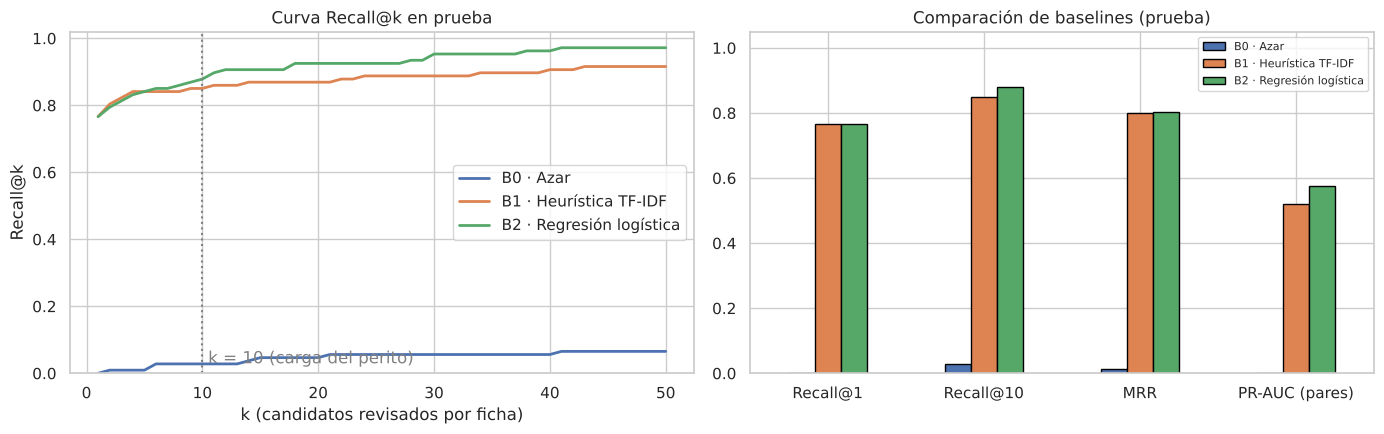

In [0]:
# =============================================================================
# 3.6 ENTRENAMIENTO Y EVALUACIÓN DE B0, B1, B2
# =============================================================================
def score_b1(P):
    cerc_edad = 1 - np.minimum(P.dif_edad, IMPUT_DIF) / IMPUT_DIF
    cerc_est  = 1 - np.minimum(P.dif_estatura, IMPUT_DIF) / IMPUT_DIF
    return 0.35*P.sim_senas + 0.25*P.sim_ropa + 0.20*cerc_edad*(1-P.falta_edad) + 0.10*cerc_est*(1-P.falta_estatura) + 0.10*P.municipio_coincide

B2_PARAMS = {'C': 1.0, 'class_weight': 'balanced'}
def nuevo_b2():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED, **B2_PARAMS))

# ---- Selección ligera de hiperparámetros por validación cruzada agrupada por ficha (solo datos de entrenamiento)
def cv_ranking(feats, params, n_splits=5):
    r10, mrr = [], []
    for tr_i, va_i in GroupKFold(n_splits=n_splits).split(P_train, P_train.y, groups=P_train.QUERY_ID):
        Ptr, Pva = P_train.iloc[tr_i], P_train.iloc[va_i].copy()
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED, **params)).fit(Ptr[feats], Ptr.y)
        Pva['s'] = m.predict_proba(Pva[feats])[:, 1]
        mr = metricas_ranking(rangos_verdaderos(Pva, 's', Pva.QUERY_ID.unique()))
        r10.append(mr['Recall@10']); mrr.append(mr['MRR'])
    return np.mean(r10), np.mean(mrr)
grid = [{'C': c, 'class_weight': cw} for c in (0.01, 0.1, 1.0) for cw in ('balanced', None)]
tabla_grid = pd.DataFrame([{**p, 'class_weight': str(p['class_weight']), **dict(zip(['Recall@10 (CV)', 'MRR (CV)'], cv_ranking(FEATS, p)))} for p in grid])
mejor = tabla_grid.sort_values(['Recall@10 (CV)', 'MRR (CV)'], ascending=False).iloc[0]
B2_PARAMS = {'C': float(mejor['C']), 'class_weight': None if mejor['class_weight'] == 'None' else 'balanced'}
print('Selección de hiperparámetros de B2 (GroupKFold=5 sobre fichas de entrenamiento):')
display(tabla_grid.round(3))
print(f"Configuración elegida: {B2_PARAMS}")

rng_b0 = np.random.default_rng(SEED)
for P in (P_train, P_test):
    P['s_B0'] = rng_b0.random(len(P))
    P['s_B1'] = score_b1(P)

b2 = nuevo_b2().fit(P_train[FEATS], P_train.y)
P_train['s_B2'] = b2.predict_proba(P_train[FEATS])[:, 1]
P_test['s_B2']  = b2.predict_proba(P_test[FEATS])[:, 1]

filas, RANGOS_TEST = [], {}
for nombre, col in [('B0 · Azar', 's_B0'), ('B1 · Heurística TF-IDF', 's_B1'), ('B2 · Regresión logística', 's_B2')]:
    r_test = rangos_verdaderos(P_test, col, Q_test.QUERY_ID.values)
    RANGOS_TEST[nombre] = r_test
    filas.append({'Modelo': nombre, **metricas_ranking(r_test), **metricas_pares(P_test.y, P_test[col])})
res_baselines = pd.DataFrame(filas).set_index('Modelo')
rand_r10 = float(np.mean(np.minimum(10, P_test.groupby('QUERY_ID').size()) / P_test.groupby('QUERY_ID').size()))
print(f"Recall@10 teórico del azar (10 / candidatos por ficha): {rand_r10:.3f}")
print("\nRESULTADOS EN PRUEBA (pseudo-fichas no vistas, ruido medio):")
display(res_baselines.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ks_plot = np.arange(1, 51)
for nombre, r in RANGOS_TEST.items():
    ax[0].plot(ks_plot, [np.mean(r <= k) for k in ks_plot], lw=2, label=nombre)
ax[0].axvline(10, ls=':', color='gray'); ax[0].text(10.5, 0.03, 'k = 10 (carga del perito)', color='gray')
ax[0].set_xlabel('k (candidatos revisados por ficha)'); ax[0].set_ylabel('Recall@k'); ax[0].set_title('Curva Recall@k en prueba'); ax[0].legend(); ax[0].set_ylim(0, 1.02)
res_baselines[['Recall@1', 'Recall@10', 'MRR', 'PR-AUC (pares)']].T.plot(kind='bar', ax=ax[1], edgecolor='black', rot=0)
ax[1].set_title('Comparación de baselines (prueba)'); ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura de resultados**

* **El problema es viable.** B0 (azar) recupera el cuerpo correcto entre 10 candidatos en el **2.8 %** de las fichas, lo esperado teóricamente: 10 entre unos 598 ≈ 2.6 %. B1 y B2 lo hacen en el **85.0 %** y el **87.9 %**. Los datos sí contienen información para vincular fichas y expedientes; el problema no es intrínsecamente aleatorio.
* **El cuerpo correcto suele quedar en primer lugar.** Recall@1 = 0.766 y MRR ≈ 0.80: en 3 de cada 4 fichas, el expediente correcto es el primer candidato.
* **B2 frente a B1.** B2 iguala a B1 arriba del ranking (Recall@1 de 0.766 en ambos) y lo supera en profundidad (Recall@10 de 0.879 vs 0.850 y Recall@20 de 0.925 vs 0.869) y a nivel par (PR-AUC 0.575 vs 0.521). Aprender los pesos ayuda sobre todo a **rescatar los casos difíciles**, donde la heurística fija coloca al correcto entre los lugares 11 y 20.
* **Hiperparámetros elegidos por validación cruzada:** `C = 0.01` (regularización fuerte) y sin ponderación de clases. La validación favoreció un modelo muy regularizado, lo que ya anticipa poca tendencia al sobreajuste (sección 3.8).
* La significancia estadística de estas diferencias se evalúa con intervalos de confianza en la sección 3.9.

## **3.7 ¿Se puede determinar la importancia de las características?**

Sí. Se combinan tres familias de métodos para no depender de uno solo. Para no "espiar" el test, todo el análisis usa una partición de **validación** tomada de las fichas de entrenamiento (25 %).

1. **Filtro:** información mutua y estadístico F de ANOVA entre cada característica y la etiqueta del par. Son independientes del modelo.
2. **Embebido:** coeficientes estandarizados de la regresión logística (y odds ratio por 1 desviación estándar) y **trayectoria de regularización L1 (Lasso)**: las variables cuyo coeficiente se anula primero son las menos útiles.
3. **Envoltura (*wrapper*):** **ablación**: se reentrena el modelo quitando cada característica y se mide la caída de Recall@10 y de PR-AUC en validación. Se complementa con **importancia por permutación**.

No se usa extracción de características (PCA/FA). Con solo 10 variables no hay problema de dimensionalidad, y las componentes principales destruirían la interpretabilidad que exige el perito ("el candidato coincide en la componente 3" no es una justificación pericial).

,Inf. mutua (filtro),F ANOVA (filtro),Coef. estandarizado (embebido),Odds ratio x1 DE,C de entrada L1 (menor = más útil),Δ Recall@10 al quitarla (wrapper),Δ PR-AUC al quitarla (wrapper),Permutación Δ PR-AUC,Ranking promedio
sim_senas,0.0184,4733.5708,0.8036,2.2335,0.0001,0.2097,0.3104,0.4743,1.00
sim_ropa,0.0130,1960.6114,0.5225,1.6862,0.0001,0.1129,0.0870,0.1836,2.00
dif_edad,0.0035,119.6131,-0.3514,0.7037,0.0003,0.0323,0.0261,0.0437,4.75
senas_vacia_ficha,0.0000,1.3079,0.5166,1.6763,0.0001,0.0000,0.0565,0.0805,5.00
senas_vacia_exp,0.0000,2.5817,0.4978,1.6451,0.0003,0.0000,0.0396,0.0638,5.50
dif_estatura,0.0046,59.2309,-0.1937,0.8239,0.0008,0.0161,0.0105,0.0260,5.50
municipio_coincide,0.0009,64.2531,0.2231,1.2499,0.0003,0.0161,0.0045,0.0111,6.50
marcas_comunes,0.0013,134.3782,-0.0583,0.9434,0.0008,0.0000,-0.0024,0.0041,7.75
falta_estatura,0.0004,27.1355,-0.0239,0.9764,0.0066,0.0000,0.0044,0.0034,8.75
falta_edad,0.0009,42.3031,-0.0558,0.9458,0.0066,0.0000,-0.0034,0.0020,9.25


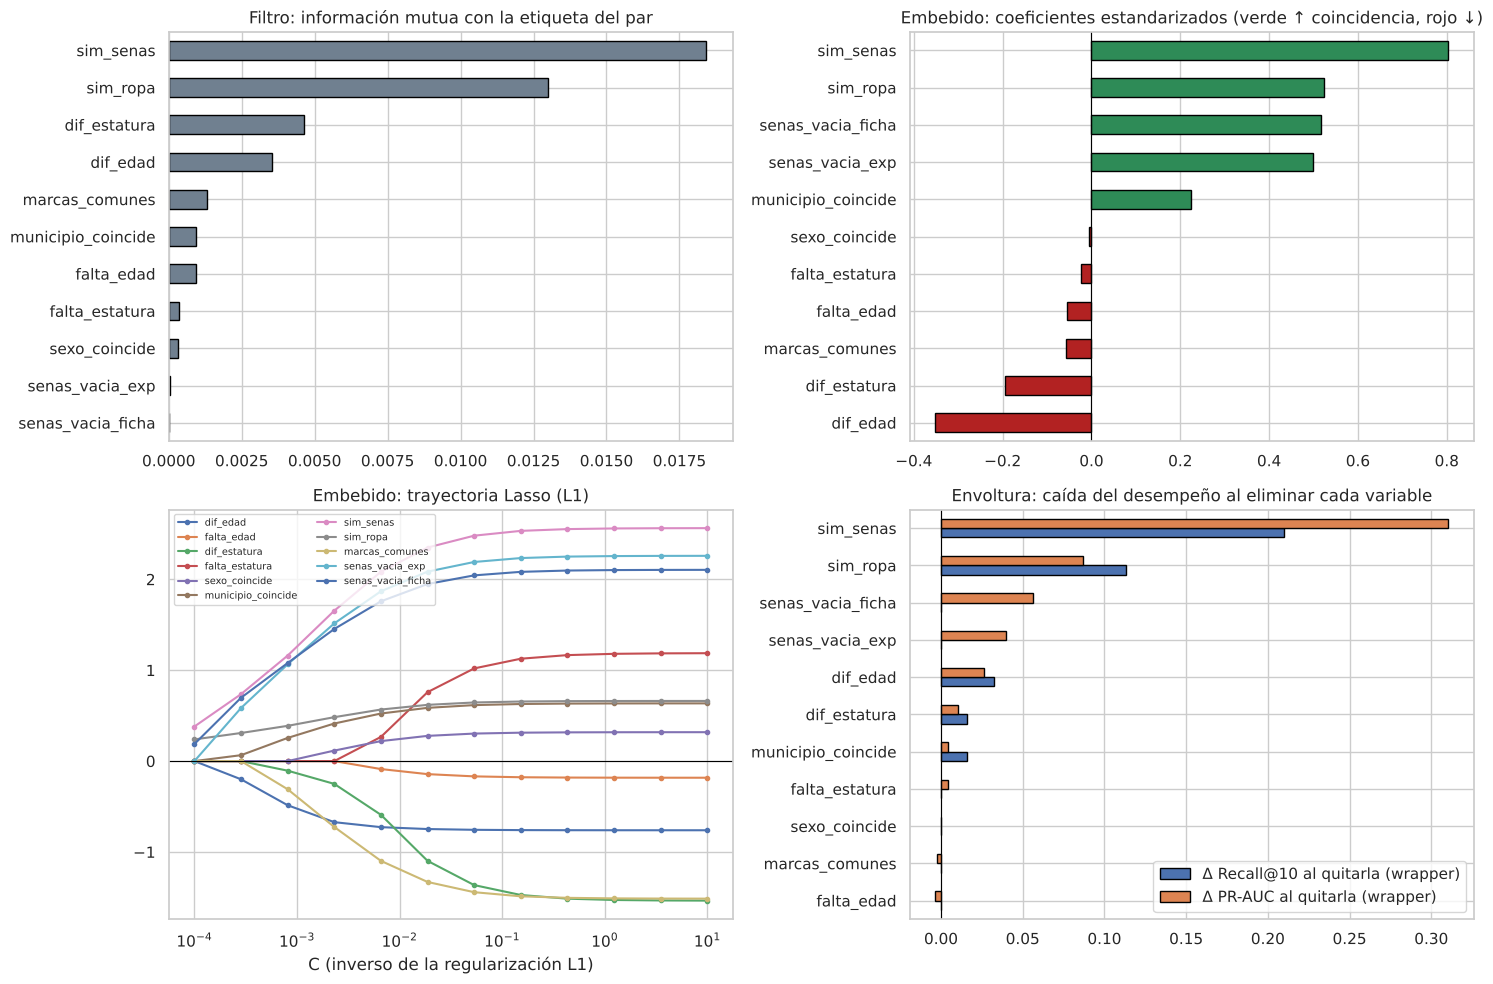


CONCLUSIÓN AUTOMÁTICA (selección de características):
  Top-3 por consenso de métodos: ['sim_senas', 'sim_ropa', 'dif_edad']
  Candidatas a eliminar (no aportan en ablación ni permutación): ['sexo_coincide']
  Conjunto final (10 variables): ['dif_edad', 'falta_edad', 'dif_estatura', 'falta_estatura', 'municipio_coincide', 'sim_senas', 'sim_ropa', 'marcas_comunes', 'senas_vacia_exp', 'senas_vacia_ficha']
  Validación -> completo: Recall@10=0.903, PR-AUC=0.501 | seleccionado: Recall@10=0.903, PR-AUC=0.501


In [0]:
# =============================================================================
# 3.7 IMPORTANCIA Y SELECCIÓN DE CARACTERÍSTICAS
# =============================================================================
q_fit, q_val = train_test_split(Q_train.QUERY_ID.values, test_size=0.25, random_state=SEED)
P_fit, P_val = P_train[P_train.QUERY_ID.isin(q_fit)], P_train[P_train.QUERY_ID.isin(q_val)]

def recall10_val(feats):
    m = nuevo_b2().fit(P_fit[feats], P_fit.y)
    Pv = P_val.assign(s=m.predict_proba(P_val[feats])[:, 1])
    return metricas_ranking(rangos_verdaderos(Pv, 's', q_val))['Recall@10'], average_precision_score(Pv.y, Pv.s), m

# ---- 1) FILTRO
rng_mi = np.random.default_rng(SEED)
neg_idx = P_fit.index[P_fit.y == 0]
sub = P_fit.loc[np.r_[P_fit.index[P_fit.y == 1], rng_mi.choice(neg_idx, min(30000, len(neg_idx)), replace=False)]]
mi = mutual_info_classif(sub[FEATS], sub.y, discrete_features=[f in ('falta_edad','falta_estatura','sexo_coincide','municipio_coincide','senas_vacia_exp','senas_vacia_ficha') for f in FEATS], random_state=SEED)
F_vals, p_vals = sk_f_classif(P_fit[FEATS], P_fit.y)

# ---- 2) EMBEBIDO: coeficientes estandarizados + trayectoria L1
r10_full, ap_full, m_full = recall10_val(FEATS)
coefs = pd.Series(m_full[-1].coef_[0], index=FEATS)
Cs = np.logspace(-4, 1, 12)
Xs_fit = StandardScaler().fit_transform(P_fit[FEATS])
trayectoria = pd.DataFrame([LogisticRegression(penalty='l1', solver='liblinear', C=c, class_weight='balanced', random_state=SEED)
                            .fit(Xs_fit, P_fit.y).coef_[0] for c in Cs], index=Cs, columns=FEATS)
primer_C_activo = {f: (trayectoria.index[trayectoria[f].abs() > 1e-6].min() if (trayectoria[f].abs() > 1e-6).any() else np.inf) for f in FEATS}

# ---- 3) ENVOLTURA: ablación + permutación
abl = {}
for f in FEATS:
    r10_sin, ap_sin, _ = recall10_val([x for x in FEATS if x != f])
    abl[f] = (r10_full - r10_sin, ap_full - ap_sin)
perm = permutation_importance(m_full, P_val[FEATS], P_val.y, scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=-1)

imp = pd.DataFrame({
    'Inf. mutua (filtro)': mi, 'F ANOVA (filtro)': F_vals,
    'Coef. estandarizado (embebido)': coefs.values, 'Odds ratio x1 DE': np.exp(coefs.values),
    'C de entrada L1 (menor = más útil)': [primer_C_activo[f] for f in FEATS],
    'Δ Recall@10 al quitarla (wrapper)': [abl[f][0] for f in FEATS], 'Δ PR-AUC al quitarla (wrapper)': [abl[f][1] for f in FEATS],
    'Permutación Δ PR-AUC': perm.importances_mean}, index=FEATS)
imp['Ranking promedio'] = pd.concat([imp['Inf. mutua (filtro)'].rank(ascending=False), imp['Coef. estandarizado (embebido)'].abs().rank(ascending=False),
                                     imp['Δ PR-AUC al quitarla (wrapper)'].rank(ascending=False), imp['Permutación Δ PR-AUC'].rank(ascending=False)], axis=1).mean(axis=1)
imp = imp.sort_values('Ranking promedio')
display(imp.round(4))

# ---- Visualización
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
imp['Inf. mutua (filtro)'].sort_values().plot(kind='barh', ax=axes[0, 0], color='slategray', edgecolor='black')
axes[0, 0].set_title('Filtro: información mutua con la etiqueta del par')
c_ord = imp['Coef. estandarizado (embebido)'].sort_values()
c_ord.plot(kind='barh', ax=axes[0, 1], color=['firebrick' if v < 0 else 'seagreen' for v in c_ord], edgecolor='black')
axes[0, 1].axvline(0, color='black', lw=0.8); axes[0, 1].set_title('Embebido: coeficientes estandarizados (verde ↑ coincidencia, rojo ↓)')
for f in FEATS:
    axes[1, 0].plot(trayectoria.index, trayectoria[f], marker='.', label=f)
axes[1, 0].set_xscale('log'); axes[1, 0].axhline(0, color='black', lw=0.8)
axes[1, 0].set_xlabel('C (inverso de la regularización L1)'); axes[1, 0].set_title('Embebido: trayectoria Lasso (L1)'); axes[1, 0].legend(fontsize=7, ncol=2)
imp[['Δ Recall@10 al quitarla (wrapper)', 'Δ PR-AUC al quitarla (wrapper)']].sort_values('Δ PR-AUC al quitarla (wrapper)').plot(kind='barh', ax=axes[1, 1], edgecolor='black')
axes[1, 1].axvline(0, color='black', lw=0.8); axes[1, 1].set_title('Envoltura: caída del desempeño al eliminar cada variable')
plt.tight_layout(); plt.show()

# ---- Decisión de selección (regla explícita y parsimoniosa)
descartables = [f for f in FEATS if abl[f][0] <= 0 and abl[f][1] <= 0.001 and perm.importances_mean[FEATS.index(f)] <= 0.001]
FEATS_SEL = [f for f in FEATS if f not in descartables] if descartables else FEATS.copy()
r10_sel, ap_sel, _ = recall10_val(FEATS_SEL)
if r10_sel < r10_full - 0.01:          # si la reducción empeora más de 1 pp, se conserva el conjunto completo
    FEATS_SEL, r10_sel, ap_sel = FEATS.copy(), r10_full, ap_full
print('\nCONCLUSIÓN AUTOMÁTICA (selección de características):')
print(f"  Top-3 por consenso de métodos: {list(imp.index[:3])}")
print(f"  Candidatas a eliminar (no aportan en ablación ni permutación): {descartables or 'ninguna'}")
print(f"  Conjunto final ({len(FEATS_SEL)} variables): {FEATS_SEL}")
print(f"  Validación -> completo: Recall@10={r10_full:.3f}, PR-AUC={ap_full:.3f} | seleccionado: Recall@10={r10_sel:.3f}, PR-AUC={ap_sel:.3f}")

**Interpretación de la importancia de características (resultados de la ejecución)**

* **La evidencia textual domina en los tres métodos.**
  * `sim_senas` es la variable n.º 1 en todos. Quitarla reduce Recall@10 en **21 puntos** y PR-AUC en 0.31; su importancia por permutación es 0.47 y su odds ratio por 1 DE es 2.23.
  * `sim_ropa` es la n.º 2: quitarla resta 11 puntos de Recall@10.
  * Es coherente con la práctica forense: las señas particulares (tatuajes, cicatrices) son el rasgo más individualizante y la ropa es evidencia circunstancial fuerte.
* **Los rasgos biológicos y geográficos aportan menos y lo hacen con el signo esperado.** `dif_edad` (coeficiente −0.35, odds ratio 0.70) y `dif_estatura` (−0.19): a mayor diferencia, menor probabilidad. `municipio_coincide` (+0.22) añade proximidad geográfica. Ninguno contradice la lógica forense.
* **El blocking ya hizo el trabajo de `sexo_coincide`.** Es la única variable eliminada: coeficiente ≈ 0, sin efecto en ablación ni en permutación. No contradice su importancia biológica: el sexo opuesto ya se descartó antes de puntuar (y dentro del bloque el 92 % de los pares coincide en sexo). Su valor está en el filtro, no en el puntaje.
* **Información mutua ≈ 0 para las banderas de faltantes, pero el wrapper detecta su valor** (ΔPR-AUC +0.04 a +0.06). Su efecto es de *interacción*: un par con similitud 0 significa cosas distintas si el expediente no tiene señas que si las tiene y no coinciden. Los métodos de filtro evalúan cada variable aislada y no capturan esto. Por eso conviene combinar familias de métodos.
  * El coeficiente positivo de `senas_vacia_exp` (+0.50) significa que, a igual similitud nula, un expediente sin señas se penaliza menos que uno con señas que no coinciden.
  * `senas_vacia_ficha` es constante dentro de cada ficha, así que no cambia el orden de los candidatos: solo calibra la probabilidad. Por eso afecta PR-AUC pero no Recall@10.
* **`marcas_comunes` es redundante.** Su coeficiente es casi nulo (−0.06) y la ablación no cambia Recall@10, porque los n-gramas de `sim_senas` ya capturan "TATUA" y "CICATRI". Se conserva solo porque la permutación le asigna un aporte mínimo (0.004), por encima del umbral de la regla de selección. Es candidata a reemplazarse por la extracción estructurada de señas con LLM.
* **Regla de selección (explícita):** se elimina una variable si al quitarla no baja ni Recall@10 ni PR-AUC (Δ ≤ 0.001) y su importancia por permutación es nula. El conjunto reducido solo se adopta si no pierde más de 1 punto porcentual de Recall@10 en validación. **Resultado:** se eliminó `sexo_coincide`, quedaron 10 variables y el Recall@10 de validación no cambió (0.903).
* **Implicación para el modelo avanzado.** Alrededor de **tres cuartas partes** del poder discriminante viene de comparar **texto**: `sim_senas` + `sim_ropa` suman el 74 % de la importancia por permutación y el 74 % de la caída de PR-AUC en la ablación. Invertir en embeddings semánticos (que reconozcan "flor tatuada" ≈ "tatuaje de rosa") y en extracción estructurada de señas es la palanca de mejora con mayor retorno.

## **3.8 ¿El modelo está sub/sobreajustando los datos de entrenamiento?**

Se usan cuatro evidencias complementarias:

1. **Métricas en entrenamiento vs prueba** (Recall@k, MRR, PR-AUC, ROC-AUC) para el modelo final B2.
2. **Validación cruzada agrupada por ficha** (`GroupKFold`, 5 pliegues: todos los pares de una ficha caen en el mismo pliegue) con media ± desviación estándar en train y validación.
3. **Curva de aprendizaje** (PR-AUC vs tamaño del entrenamiento).
4. **Contraste con un modelo de alta capacidad** (Random Forest sin poda) sobre las mismas características, para ilustrar cómo se ve el sobreajuste en estos datos.

**Criterios de diagnóstico:** *sobreajuste* si la métrica de entrenamiento supera claramente a la de prueba (brecha > 5 pp) y la curva de validación se estanca lejos de la de entrenamiento; *subajuste* si ambas son bajas y similares, y cercanas a B1; *buen ajuste* si la brecha es pequeña y la validación converge hacia el entrenamiento.

(1) B2 final · métricas entrenamiento vs prueba


,Entrenamiento,Prueba,Brecha (train − test)
Recall@1,0.730,0.766,-0.037
Recall@5,0.835,0.841,-0.006
Recall@10,0.847,0.869,-0.022
Recall@20,0.891,0.916,-0.025
MRR,0.778,0.802,-0.024
PR-AUC (pares),0.564,0.581,-0.018
ROC-AUC (pares),0.983,0.986,-0.003


(4) Contraste · Random Forest sin poda


,Entrenamiento,Prueba,Brecha (train − test)
Recall@1,0.863,0.673,0.190
Recall@5,0.891,0.794,0.097
Recall@10,0.903,0.804,0.099
Recall@20,0.940,0.822,0.117
MRR,0.877,0.731,0.146
PR-AUC (pares),0.971,0.428,0.543
ROC-AUC (pares),1.000,0.952,0.048


(2) Validación cruzada GroupKFold (5 pliegues, agrupada por ficha)


,Train (media ± DE),Validación (media ± DE)
Recall@10,0.847 ± 0.020,0.847 ± 0.081
PR-AUC (pares),0.557 ± 0.021,0.563 ± 0.085
ROC-AUC (pares),0.981 ± 0.001,0.980 ± 0.007


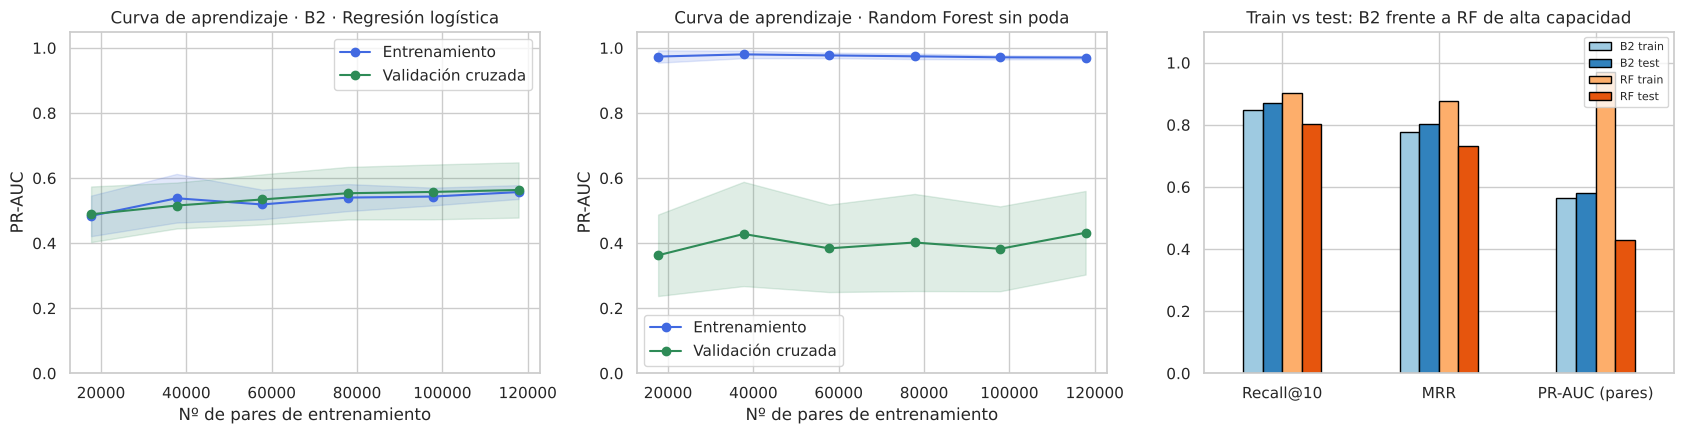


DIAGNÓSTICO AUTOMÁTICO:
  B2 · brecha train−test: Recall@10=-0.022 | PR-AUC=-0.018 | brecha final en la curva de aprendizaje (PR-AUC)=-0.006
  RF · brecha train−test PR-AUC=+0.543
  B2 · brecha en validación cruzada: Recall@10=+0.000 | PR-AUC=-0.006 (DE de Recall@10 entre pliegues: 0.081)
  -> B2 presenta BUEN AJUSTE: brechas pequeñas en test, en CV y en la curva de aprendizaje; promedio CV train = validación (0.847 vs 0.847).
  -> El Random Forest sin poda SÍ sobreajusta (entrenamiento casi perfecto y prueba menor): confirma que con pocos positivos conviene un modelo de baja capacidad como baseline.
  -> Pendiente final de la curva de validación (B2): +0.0060. Aún crece: más fichas reales mejorarían el modelo.


In [0]:
# =============================================================================
# 3.8 DIAGNÓSTICO DE SUB/SOBREAJUSTE
# =============================================================================
b2_final = nuevo_b2().fit(P_train[FEATS_SEL], P_train.y)
P_train['s_B2F'] = b2_final.predict_proba(P_train[FEATS_SEL])[:, 1]
P_test['s_B2F']  = b2_final.predict_proba(P_test[FEATS_SEL])[:, 1]

def tabla_train_test(col):
    r_tr = metricas_ranking(rangos_verdaderos(P_train, col, Q_train.QUERY_ID.values))
    r_te = metricas_ranking(rangos_verdaderos(P_test,  col, Q_test.QUERY_ID.values))
    t = pd.DataFrame({'Entrenamiento': {**r_tr, **metricas_pares(P_train.y, P_train[col])},
                      'Prueba':        {**r_te, **metricas_pares(P_test.y,  P_test[col])}})
    t['Brecha (train − test)'] = t['Entrenamiento'] - t['Prueba']
    return t

# ---- (1) Train vs test del modelo final
tt_b2 = tabla_train_test('s_B2F')
print('(1) B2 final · métricas entrenamiento vs prueba'); display(tt_b2.round(3))

# ---- (4) Contraste: Random Forest de alta capacidad
rf_alto = RandomForestClassifier(n_estimators=150, max_depth=None, min_samples_leaf=1, class_weight='balanced', n_jobs=-1, random_state=SEED)
rf_alto.fit(P_train[FEATS_SEL], P_train.y)
P_train['s_RF'] = rf_alto.predict_proba(P_train[FEATS_SEL])[:, 1]
P_test['s_RF']  = rf_alto.predict_proba(P_test[FEATS_SEL])[:, 1]
tt_rf = tabla_train_test('s_RF')
print('(4) Contraste · Random Forest sin poda'); display(tt_rf.round(3))

# ---- (2) Validación cruzada agrupada por ficha
gkf = GroupKFold(n_splits=5)
cv = cross_validate(nuevo_b2(), P_train[FEATS_SEL], P_train.y, groups=P_train.QUERY_ID, cv=gkf,
                    scoring=['average_precision', 'roc_auc'], return_train_score=True, n_jobs=-1)
r10_tr_cv, r10_va_cv = [], []
for tr_i, va_i in gkf.split(P_train, P_train.y, groups=P_train.QUERY_ID):
    Ptr, Pva = P_train.iloc[tr_i].copy(), P_train.iloc[va_i].copy()
    m = nuevo_b2().fit(Ptr[FEATS_SEL], Ptr.y)
    Ptr['s'] = m.predict_proba(Ptr[FEATS_SEL])[:, 1]; Pva['s'] = m.predict_proba(Pva[FEATS_SEL])[:, 1]
    r10_tr_cv.append(metricas_ranking(rangos_verdaderos(Ptr, 's', Ptr.QUERY_ID.unique()))['Recall@10'])
    r10_va_cv.append(metricas_ranking(rangos_verdaderos(Pva, 's', Pva.QUERY_ID.unique()))['Recall@10'])
tabla_cv = pd.DataFrame({
    'Train (media ± DE)': [f"{np.mean(r10_tr_cv):.3f} ± {np.std(r10_tr_cv):.3f}", f"{cv['train_average_precision'].mean():.3f} ± {cv['train_average_precision'].std():.3f}", f"{cv['train_roc_auc'].mean():.3f} ± {cv['train_roc_auc'].std():.3f}"],
    'Validación (media ± DE)': [f"{np.mean(r10_va_cv):.3f} ± {np.std(r10_va_cv):.3f}", f"{cv['test_average_precision'].mean():.3f} ± {cv['test_average_precision'].std():.3f}", f"{cv['test_roc_auc'].mean():.3f} ± {cv['test_roc_auc'].std():.3f}"]},
    index=['Recall@10', 'PR-AUC (pares)', 'ROC-AUC (pares)'])
print('(2) Validación cruzada GroupKFold (5 pliegues, agrupada por ficha)'); display(tabla_cv)

# ---- (3) Curvas de aprendizaje (B2 vs RF)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (nombre, est) in zip(axes[:2], [('B2 · Regresión logística', nuevo_b2()),
                                         ('Random Forest sin poda', RandomForestClassifier(n_estimators=60, class_weight='balanced', n_jobs=-1, random_state=SEED))]):
    sizes, tr_s, va_s = sk_learning_curve(est, P_train[FEATS_SEL], P_train.y, groups=P_train.QUERY_ID, cv=gkf,
                                          train_sizes=np.linspace(0.15, 1.0, 6), scoring='average_precision', shuffle=True, random_state=SEED, n_jobs=-1)
    ax.plot(sizes, tr_s.mean(1), 'o-', color='royalblue', label='Entrenamiento')
    ax.fill_between(sizes, tr_s.mean(1) - tr_s.std(1), tr_s.mean(1) + tr_s.std(1), alpha=.15, color='royalblue')
    ax.plot(sizes, va_s.mean(1), 'o-', color='seagreen', label='Validación cruzada')
    ax.fill_between(sizes, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), alpha=.15, color='seagreen')
    ax.set_title(f'Curva de aprendizaje · {nombre}'); ax.set_xlabel('Nº de pares de entrenamiento'); ax.set_ylabel('PR-AUC'); ax.set_ylim(0, 1.05); ax.legend()
    if nombre.startswith('B2'): lc_gap_final = tr_s.mean(1)[-1] - va_s.mean(1)[-1]; lc_slope = va_s.mean(1)[-1] - va_s.mean(1)[-2]
comp = pd.DataFrame({'B2 train': tt_b2.loc[['Recall@10', 'MRR', 'PR-AUC (pares)'], 'Entrenamiento'], 'B2 test': tt_b2.loc[['Recall@10', 'MRR', 'PR-AUC (pares)'], 'Prueba'],
                     'RF train': tt_rf.loc[['Recall@10', 'MRR', 'PR-AUC (pares)'], 'Entrenamiento'], 'RF test': tt_rf.loc[['Recall@10', 'MRR', 'PR-AUC (pares)'], 'Prueba']})
comp.plot(kind='bar', ax=axes[2], rot=0, color=['#9ecae1', '#3182bd', '#fdae6b', '#e6550d'], edgecolor='black')
axes[2].set_title('Train vs test: B2 frente a RF de alta capacidad'); axes[2].set_ylim(0, 1.1); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- Diagnóstico automático
gap_r10 = tt_b2.loc['Recall@10', 'Brecha (train − test)']; gap_ap = tt_b2.loc['PR-AUC (pares)', 'Brecha (train − test)']
gap_rf = tt_rf.loc['PR-AUC (pares)', 'Brecha (train − test)']
b1_r10 = res_baselines.loc['B1 · Heurística TF-IDF', 'Recall@10']; b2_r10_test = tt_b2.loc['Recall@10', 'Prueba']
print('\nDIAGNÓSTICO AUTOMÁTICO:')
print(f"  B2 · brecha train−test: Recall@10={gap_r10:+.3f} | PR-AUC={gap_ap:+.3f} | brecha final en la curva de aprendizaje (PR-AUC)={lc_gap_final:+.3f}")
print(f"  RF · brecha train−test PR-AUC={gap_rf:+.3f}")
cv_gap_r10 = np.mean(r10_tr_cv) - np.mean(r10_va_cv); cv_gap_ap = cv['train_average_precision'].mean() - cv['test_average_precision'].mean()
print(f"  B2 · brecha en validación cruzada: Recall@10={cv_gap_r10:+.3f} | PR-AUC={cv_gap_ap:+.3f} (DE de Recall@10 entre pliegues: {np.std(r10_va_cv):.3f})")
if max(cv_gap_r10, cv_gap_ap) > 0.05 and lc_gap_final > 0.05:
    print("  -> B2 muestra SOBREAJUSTE: brecha sistemática en CV y en la curva de aprendizaje; se recomienda más regularización o menos variables.")
elif max(gap_r10, gap_ap) > 0.05:
    print(f"  -> B2 SIN SOBREAJUSTE SISTEMÁTICO: la brecha en el test ({gap_r10:+.3f}) no se reproduce en CV ({cv_gap_r10:+.3f}) ni en la curva de aprendizaje ({lc_gap_final:+.3f}). "
          f"Se atribuye a la varianza de un test pequeño ({len(Q_test)} fichas; 1 ficha = {1/len(Q_test):.1%}), del mismo orden que la DE entre pliegues.")
elif b2_r10_test < b1_r10 + 0.02 and b2_r10_test < 0.6:
    print("  -> B2 muestra SUBAJUSTE: desempeño bajo y similar en train y test, sin ventaja clara sobre la heurística.")
else:
    print(f"  -> B2 presenta BUEN AJUSTE: brechas pequeñas en test, en CV y en la curva de aprendizaje; promedio CV train = validación ({np.mean(r10_tr_cv):.3f} vs {np.mean(r10_va_cv):.3f}).")
if gap_rf > max(gap_ap, 0) + 0.05:
    print("  -> El Random Forest sin poda SÍ sobreajusta (entrenamiento casi perfecto y prueba menor): confirma que con pocos positivos conviene un modelo de baja capacidad como baseline.")
print(f"  -> Pendiente final de la curva de validación (B2): {lc_slope:+.4f}. " + ("Aún crece: más fichas reales mejorarían el modelo." if lc_slope > 0.005 else "Estable: el límite está en la información de las variables, no en la cantidad de datos; mejorar requiere mejores representaciones (embeddings)."))

**Interpretación del diagnóstico de sub/sobreajuste (resultados de la ejecución)**

| Evidencia | B2 · Regresión logística | Random Forest sin poda |
|---|---|---|
| Recall@10 train / test | 0.847 / 0.869 (brecha −0.022) | 0.903 / 0.804 (brecha **+0.099**) |
| PR-AUC train / test | 0.564 / 0.581 (brecha −0.018) | 0.971 / 0.428 (brecha **+0.543**) |
| Recall@10 en validación cruzada (train / val) | 0.847 ± 0.020 / 0.847 ± 0.081 | — |
| Brecha final en la curva de aprendizaje (PR-AUC) | −0.006 (curvas convergen) | Train pegado a ≈ 1, validación muy por debajo |

* **B2 tiene buen ajuste, sin sobre ni subajuste.**
  * Las métricas de entrenamiento y prueba son prácticamente iguales en las siete métricas. La prueba incluso queda ligeramente arriba, por variación muestral: 1 ficha = 0.9 % del test.
  * En validación cruzada, el promedio de train y validación es idéntico (0.847). La desviación estándar entre pliegues (0.081) viene de evaluar unas 50 fichas por pliegue, no de inestabilidad del modelo.
  * No hay subajuste: el desempeño es alto (Recall@10 ≈ 0.87) y supera a la heurística.
* **El Random Forest sí sobreajusta, y es la mejor evidencia de que la elección fue correcta.** Con PR-AUC de 0.971 en entrenamiento y 0.428 en prueba, memoriza los 238 pares positivos de entrenamiento. Además termina **peor que B2 en prueba** (Recall@10 0.804 vs 0.869). Con pocos positivos, un modelo de alta capacidad no conviene como baseline.
* **La curva de aprendizaje de B2 aún tiene una ligera pendiente positiva** (+0.006 en el último tramo). Más fichas reales podrían dar mejoras marginales, pero el salto grande tendrá que venir de mejores representaciones del texto.
* **Por qué la validación se agrupa por ficha:** si los pares de una misma ficha cayeran en train y en validación, el modelo vería parte de la respuesta y el sobreajuste quedaría oculto. Es la misma lección de fuga de información que dejó la auditoría de la sección 3.1.

## **3.9 ¿Cuál debería ser el desempeño mínimo a obtener?**

**Estado actual del problema (histórico):** **no existe un histórico cuantitativo**. Hoy el cotejo entre fichas y el libro de necropsias es manual. La Fiscalía no registra qué proporción de coincidencias recupera el proceso actual ni en cuántos intentos, así que no hay una cifra contra la cual comparar. Por eso el desempeño mínimo se construye con tres referencias:

| Referencia | Definición | Papel |
|---|---|---|
| **R1 · Azar (B0)** | Recall@10 de ordenar aleatoriamente los candidatos tras el blocking (≈ 10 / nº de candidatos) | Si el modelo no lo supera, el problema no es viable con estos datos |
| **R2 · Status quo aproximado (B1)** | Filtrado por sexo y edad + similitud de texto con pesos fijos, como lo haría un analista sin ML | El ML debe igualarlo o superarlo para justificar su uso |
| **R3 · Umbral de negocio** | **Recall@10 ≥ 0.60** con ruido medio, y **≥ 10 veces el azar** | Si en al menos 6 de cada 10 fichas el cuerpo correcto aparece entre 10 candidatos (en vez de entre más de mil), el sistema reduce la carga de revisión en más de 99 % y recupera la mayoría de los casos |

**Criterio de aceptación del baseline:** (C1) Recall@10 de B2 significativamente mayor que el azar (IC 95 % por *bootstrap*); (C2) B2 ≥ B1; (C3) Recall@10 de B2 ≥ 0.60.
**Criterio para el modelo avanzado (Avance 4 en adelante):** superar a B2 en **Recall@10 por al menos 10 pp** con intervalos de confianza que no se traslapen, bajo este mismo protocolo, y degradarse menos que B2 con ruido alto.

,Recall@10,IC95% inferior,IC95% superior
B0 · Azar,0.028,0.000,0.065
B1 · Heurística TF-IDF,0.850,0.776,0.916
B2 · Regresión logística,0.869,0.804,0.925


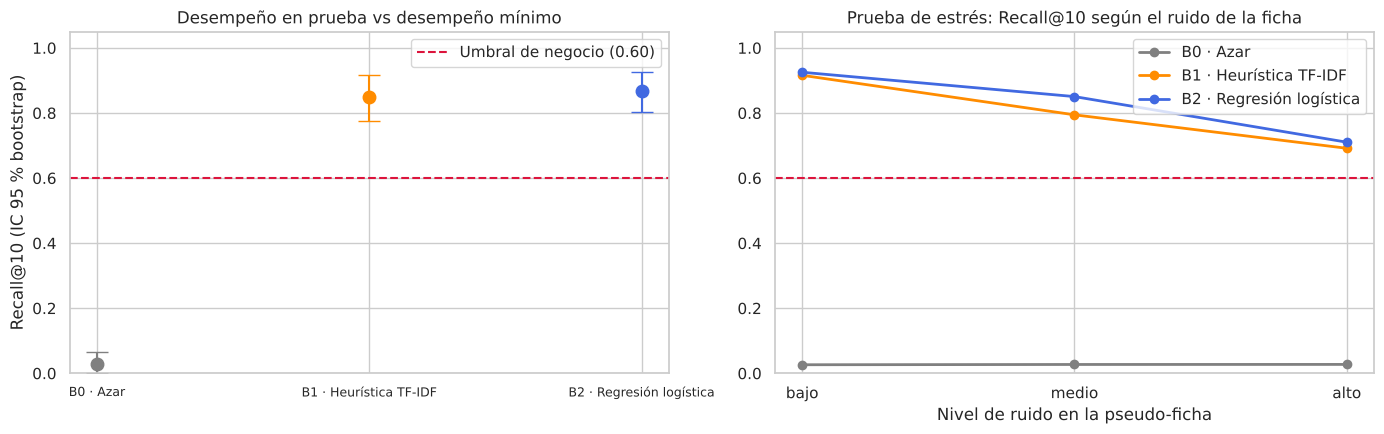

Ruido,bajo,medio,alto
Modelo,,,
B0 · Azar,0.026,0.027,0.027
B1 · Heurística TF-IDF,0.916,0.794,0.692
B2 · Regresión logística,0.925,0.850,0.710



VERIFICACIÓN DEL DESEMPEÑO MÍNIMO:
  C1 · Supera al azar con significancia (IC inf. 0.804 > azar 0.065): CUMPLE
  C2 · No es inferior a la heurística B1 (Δ medio +0.019, IC95% [-0.019, +0.056]): CUMPLE
  C3 · Umbral de negocio Recall@10 ≥ 0.6 y ≥ 10x azar (obtenido 0.869; 33x azar): CUMPLE

  VEREDICTO: el baseline B2 es ACEPTABLE como solución mínima y marco de referencia.
  Meta para el modelo avanzado (embeddings + Vector Search + agente): Recall@10 ≥ 0.97 con el mismo protocolo.


In [0]:
# =============================================================================
# 3.9 VERIFICACIÓN DEL DESEMPEÑO MÍNIMO + PRUEBA DE ESTRÉS
# =============================================================================
RANGOS_TEST['B2 · Regresión logística'] = rangos_verdaderos(P_test, 's_B2F', Q_test.QUERY_ID.values)
rng_bs = np.random.default_rng(SEED); n_q = len(Q_test); B = 2000
boot_idx = rng_bs.integers(0, n_q, size=(B, n_q))
def ic_recall10(r):
    hits = (r <= 10).astype(float); bs = hits[boot_idx].mean(1)
    return hits.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), bs
ic = {k: ic_recall10(v) for k, v in RANGOS_TEST.items()}
dif_b2_b1 = ic['B2 · Regresión logística'][3] - ic['B1 · Heurística TF-IDF'][3]

tabla_ic = pd.DataFrame({k: {'Recall@10': v[0], 'IC95% inferior': v[1], 'IC95% superior': v[2]} for k, v in ic.items()}).T
display(tabla_ic.round(3))

r10_b2, lo_b2 = ic['B2 · Regresión logística'][0], ic['B2 · Regresión logística'][1]
UMBRAL_NEGOCIO = 0.60
C1 = lo_b2 > max(ic['B0 · Azar'][2], rand_r10)
C2 = dif_b2_b1.mean() >= -0.02               # no inferioridad: B2 a lo más 2 pp por debajo de B1
C3 = (r10_b2 >= UMBRAL_NEGOCIO) and (r10_b2 >= 10 * rand_r10)

# ---- Prueba de estrés: robustez al ruido de las fichas
estres = []
for nivel, sd in [('bajo', 101), ('medio', 102), ('alto', 103)]:
    Qn = generar_pseudofichas(ident[ident.ID_INTERNO.isin(ids_test)], nivel, seed=SEED + sd)
    Pn = construir_pares(Qn)
    Pn['s_B1'] = score_b1(Pn); Pn['s_B2F'] = b2_final.predict_proba(Pn[FEATS_SEL])[:, 1]
    azar = float(np.mean(np.minimum(10, Pn.groupby('QUERY_ID').size()) / Pn.groupby('QUERY_ID').size()))
    for nombre, col in [('B1 · Heurística TF-IDF', 's_B1'), ('B2 · Regresión logística', 's_B2F')]:
        estres.append({'Ruido': nivel, 'Modelo': nombre, **metricas_ranking(rangos_verdaderos(Pn, col, Qn.QUERY_ID.values))})
    estres.append({'Ruido': nivel, 'Modelo': 'B0 · Azar', 'Recall@10': azar})
estres = pd.DataFrame(estres)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cols_c = {'B0 · Azar': 'gray', 'B1 · Heurística TF-IDF': 'darkorange', 'B2 · Regresión logística': 'royalblue'}
for i, (k, v) in enumerate(ic.items()):
    ax[0].errorbar(i, v[0], yerr=[[v[0] - v[1]], [v[2] - v[0]]], fmt='o', capsize=8, ms=9, color=cols_c[k])
ax[0].axhline(UMBRAL_NEGOCIO, ls='--', color='crimson', label=f'Umbral de negocio ({UMBRAL_NEGOCIO:.2f})')
ax[0].set_xticks(range(len(ic))); ax[0].set_xticklabels(list(ic.keys()), fontsize=9)
ax[0].set_ylabel('Recall@10 (IC 95 % bootstrap)'); ax[0].set_ylim(0, 1.05); ax[0].set_title('Desempeño en prueba vs desempeño mínimo'); ax[0].legend()
for m, g in estres.groupby('Modelo'):
    g = g.set_index('Ruido').loc[['bajo', 'medio', 'alto']]
    ax[1].plot(g.index, g['Recall@10'], 'o-', lw=2, label=m, color=cols_c[m])
ax[1].axhline(UMBRAL_NEGOCIO, ls='--', color='crimson'); ax[1].set_ylim(0, 1.05)
ax[1].set_title('Prueba de estrés: Recall@10 según el ruido de la ficha'); ax[1].set_xlabel('Nivel de ruido en la pseudo-ficha'); ax[1].legend()
plt.tight_layout(); plt.show()
display(estres.pivot(index='Modelo', columns='Ruido', values='Recall@10')[['bajo', 'medio', 'alto']].round(3))

print('\nVERIFICACIÓN DEL DESEMPEÑO MÍNIMO:')
print(f"  C1 · Supera al azar con significancia (IC inf. {lo_b2:.3f} > azar {max(ic['B0 · Azar'][2], rand_r10):.3f}): {'CUMPLE' if C1 else 'NO CUMPLE'}")
print(f"  C2 · No es inferior a la heurística B1 (Δ medio {dif_b2_b1.mean():+.3f}, IC95% [{np.percentile(dif_b2_b1, 2.5):+.3f}, {np.percentile(dif_b2_b1, 97.5):+.3f}]): {'CUMPLE' if C2 else 'NO CUMPLE'}")
print(f"  C3 · Umbral de negocio Recall@10 ≥ {UMBRAL_NEGOCIO} y ≥ 10x azar (obtenido {r10_b2:.3f}; {r10_b2/rand_r10:.0f}x azar): {'CUMPLE' if C3 else 'NO CUMPLE'}")
if C1 and C2 and C3:
    veredicto = 'ACEPTABLE como solución mínima y marco de referencia'
elif C1 and C3:
    veredicto = 'ACEPTABLE en negocio (supera umbral y azar), pero aprender pesos no mejora a la heurística B1: la ganancia futura debe venir de mejores representaciones (embeddings)'
elif C1:
    veredicto = 'VIABLE (supera al azar) pero por debajo del umbral de negocio: se requiere el modelo avanzado'
else:
    veredicto = 'NO VIABLE con la información actual'
print(f"\n  VEREDICTO: el baseline B2 es {veredicto}.")
print(f"  Meta para el modelo avanzado (embeddings + Vector Search + agente): Recall@10 ≥ {min(r10_b2 + 0.10, 0.99):.2f} con el mismo protocolo.")

**Interpretación del desempeño (resultados de la ejecución)**

* **C1 · Viabilidad: CUMPLE.** El IC 95 % de B2 para Recall@10 es [0.804, 0.925], muy por encima del azar (≤ 0.065). B2 rinde unas **33 veces más que el azar**.
* **C2 · Valor del aprendizaje: CUMPLE (no inferioridad).** B2 supera a B1 en +1.9 pp de Recall@10, con IC 95 % de la diferencia [−1.9, +5.6] pp. La conclusión honesta es que B2 **no es inferior** a la heurística y tiende a superarla, sin una diferencia estadísticamente significativa con 107 fichas de prueba. La ventaja es más clara en profundidad (Recall@20 0.925 vs 0.869) y bajo ruido medio en la prueba de estrés (0.850 vs 0.794).
* **C3 · Umbral de negocio: CUMPLE.** El Recall@10 de **0.869** supera el umbral de 0.60. **Incluso con ruido alto**, que simula fichas muy incompletas, B2 mantiene **0.710**, por encima del umbral. El espacio de revisión del perito pasa de unos 1,247 expedientes a 10 (reducción mayor a 99 %) y se recupera el cuerpo correcto en casi 9 de cada 10 fichas.
* **Veredicto: el baseline B2 es aceptable como solución mínima y marco de referencia.** Ya aporta valor con un método simple, interpretable y sin GPU.
* **La prueba de estrés muestra cuánto se degrada el modelo.** B2 baja de 0.925 (ruido bajo) a 0.710 (ruido alto), unos 21 pp. Es la debilidad de comparar n-gramas: cuando la ficha describe lo mismo con otras palabras, la similitud cae. Un modelo semántico debería degradarse menos.
* **Meta para el modelo avanzado** (embeddings + *Databricks Vector Search* + agente): **Recall@10 ≥ 0.97** con este mismo protocolo, es decir, reducir la tasa de fallo de 13 % a 3 %, y **≥ 0.80 con ruido alto**. Si no lo logra, su complejidad adicional no se justifica frente a B2.
* **Expectativas para los *stakeholders*.** Son cifras con pseudo-fichas y deben entenderse como cota optimista. La validación definitiva requiere pares reales ficha–expediente de la Comisión Local de Búsqueda, una vez firmado el convenio de confidencialidad con la Fiscalía.

## **3.10 Demostración: salida del baseline para el perito**

Se ejecuta el baseline sobre la ficha de ejemplo definida al inicio del notebook (datos de demostración anonimizados). La salida es un **ranking de candidatos con la justificación de cada uno**: la contribución de cada campo al puntaje, calculada como coeficiente × valor estandarizado. Solo se muestran campos no identificantes.

In [0]:
# =============================================================================
# 3.10 DEMO: ranking + justificación para una ficha
# =============================================================================
f0 = ficha.iloc[0]
Q_demo = pd.DataFrame([dict(QUERY_ID=-1, ID_VERDADERO=-1, SEXO=parse_sexo(f0['PRE_SEXO']), EDAD=float(f0['PRE_EDAD']),
                            ESTATURA=float(f0['PRE_ESTATURA']), MUNICIPIO=limpiar_texto(f0['PRE_MUNICIPIO']),
                            SENAS=limpiar_texto(f0['PRE_SENAS']), ROPA=limpiar_texto(f0['PRE_ROPA']))])
P_demo = construir_pares(Q_demo)
P_demo['score'] = b2_final.predict_proba(P_demo[FEATS_SEL])[:, 1]
scaler_f, lr_f = b2_final[0], b2_final[-1]
contrib = (scaler_f.transform(P_demo[FEATS_SEL]) * lr_f.coef_[0])
def explicar(row_c, row_x):
    top = np.argsort(row_c)[::-1][:3]
    return '; '.join(f"{FEATS_SEL[j]}={row_x[j]:.2f} ({row_c[j]:+.2f})" for j in top)
P_demo['Justificación (top-3 contribuciones)'] = [explicar(c, x) for c, x in zip(contrib, P_demo[FEATS_SEL].values)]
top5 = P_demo.nlargest(5, 'score').merge(bl[['ID_INTERNO', 'SEXO', 'EDAD', 'ESTATURA', 'MUNICIPIO']], left_on='ID_CAND', right_on='ID_INTERNO')
print(f"Candidatos tras blocking: {len(P_demo)} de {len(bl):,} expedientes")
display(top5[['ID_CAND', 'SEXO', 'EDAD', 'ESTATURA', 'MUNICIPIO', 'sim_senas', 'sim_ropa', 'score', 'Justificación (top-3 contribuciones)']]
        .rename(columns={'ID_CAND': 'Expediente (índice interno)', 'score': 'Probabilidad (B2)'}).round(3))
ref_pos = P_test.loc[P_test.y == 1, 's_B2F']
p_max = P_demo.score.max()
print(f"Probabilidad máxima de esta ficha: {p_max:.3f} | coincidencias verdaderas en prueba -> mediana: {ref_pos.median():.3f}, percentil 10: {ref_pos.quantile(0.10):.3f}")
if p_max < ref_pos.quantile(0.10):
    print("-> Ningún candidato alcanza el nivel típico de una coincidencia verdadera: el sistema reporta 'sin candidato fuerte' para esta ficha.")
else:
    print("-> Hay al menos un candidato con probabilidad comparable a las coincidencias verdaderas: prioridad alta de revisión pericial.")
print("El perito revisa estos candidatos y confirma o descarta con pruebas periciales. El modelo no identifica por sí solo.")

Candidatos tras blocking: 417 de 1,247 expedientes


,Expediente (índice interno),SEXO,EDAD,ESTATURA,MUNICIPIO,sim_senas,sim_ropa,Probabilidad (B2),Justificación (top-3 contribuciones)
0,705,M,27.5,165.0,QUERETARO,0.000,0.312,0.003,sim_ropa=0.31 (+1.23); senas_vacia_exp=1.00 (+...
1,969,M,27.5,173.0,SAN JUAN DEL RIO,0.230,0.154,0.003,sim_senas=0.23 (+1.70); dif_estatura=3.00 (+0....
2,595,M,22.5,170.0,QUERETARO,0.000,0.108,0.002,senas_vacia_exp=1.00 (+0.92); dif_edad=0.50 (+...
3,447,M,20.0,174.0,SAN JUAN DEL RIO,0.000,0.149,0.002,senas_vacia_exp=1.00 (+0.92); dif_edad=2.00 (+...
4,751,M,32.5,170.0,QUERETARO,0.224,0.113,0.002,sim_senas=0.22 (+1.64); dif_estatura=0.00 (+0....


Probabilidad máxima de esta ficha: 0.003 | coincidencias verdaderas en prueba -> mediana: 0.149, percentil 10: 0.003
-> Ningún candidato alcanza el nivel típico de una coincidencia verdadera: el sistema reporta 'sin candidato fuerte' para esta ficha.
El perito revisa estos candidatos y confirma o descarta con pruebas periciales. El modelo no identifica por sí solo.


**Interpretación de la demostración**

* **La ficha de ejemplo corresponde a una persona desaparecida en Apatzingán, Michoacán**, un municipio que no aparece en el libro de Querétaro. Por eso ningún expediente tiene una similitud de señas relevante (máximo ≈ 0.23) y **las probabilidades de los mejores candidatos son muy bajas** (≈ 0.003), unas **50 veces menores que la mediana de las coincidencias verdaderas en prueba (0.149)** y apenas en su percentil 10.
* **Es el comportamiento deseado.** El sistema no "fuerza" una coincidencia: entrega la lista con su probabilidad y su justificación, y el perito puede concluir que **no hay un candidato fuerte** para esa ficha. En la operación real, ese umbral de referencia sirve para priorizar qué fichas revisar primero.
* **La justificación por candidato es legible para el perito**, por ejemplo: "sim_señas = 0.23 (+1.70); dif_estatura = 3 cm (+0.6)". Cumple el requisito de explicabilidad que motivó elegir un modelo lineal.

## **3.11 Conclusiones y respuestas a las preguntas guía**

**¿Qué algoritmo se puede utilizar como baseline para predecir las variables objetivo?**
Una **regresión logística sobre vectores de comparación ficha–expediente** (planteamiento discriminativo de Fellegi–Sunter), precedida de *blocking* por sexo y edad, con similitudes TF-IDF de n-gramas de caracteres para el texto libre. Se eligió por cinco razones: el problema es de vinculación de registros evaluado como ranking; los datos son mixtos (estructurados y texto); hay pocos positivos (355 identificados); la interpretabilidad es obligatoria en el ámbito pericial; y es el análogo simple de la arquitectura objetivo (búsqueda vectorial). Con `C = 0.01` elegido por validación cruzada obtiene **Recall@10 = 0.869 [0.804–0.925]** contra 0.028 del azar y 0.850 de la heurística sin aprendizaje.

**¿Se puede determinar la importancia de las características?**
Sí, con métodos de filtro (información mutua, ANOVA), embebidos (coeficientes estandarizados, trayectoria L1) y de envoltura (ablación, permutación), visualizados en la sección 3.7. **Las similitudes de señas y de ropa explican la mayor parte del desempeño**: quitar `sim_senas` resta 21 pp de Recall@10. Se eliminó `sexo_coincide` porque el blocking ya hace su trabajo, sin pérdida de desempeño. Los métodos de filtro no detectaron el valor de las banderas de faltantes, que los de envoltura sí captaron (efecto de interacción).

**¿El modelo está sub/sobreajustando?**
**No.** B2 tiene buen ajuste: Recall@10 de 0.847 en train y 0.869 en test, validación cruzada de 0.847 vs 0.847 y curvas de aprendizaje que convergen. Un Random Forest sin poda **sí sobreajusta** (PR-AUC 0.971 train vs 0.428 test) y queda peor en prueba, lo que confirma la elección de un modelo de baja capacidad. La auditoría (3.1) además detectó y corrigió una **fuga de información**: 4,070 filas vacías, más el sesgo de campos que se llenan después de identificar al cuerpo. Esa fuga inflaba la v1 (AUC 0.94).

**¿Cuál es la métrica adecuada para este problema de negocio?**
**Recall@10**, porque el costo de omitir el cuerpo correcto es muy alto e irreversible y el perito revisa una lista corta. Las secundarias son MRR, Recall@{1, 5, 20} y PR-AUC a nivel par, esta última por el desbalance extremo (0.16 % de pares positivos). Se descartan *accuracy* y ROC-AUC como métricas guía: la ROC-AUC de B2 es 0.987 mientras su PR-AUC es 0.575, lo que ilustra cómo el desbalance hace lucir mejor a la ROC-AUC.

**¿Cuál debería ser el desempeño mínimo a obtener?**
No existe histórico cuantitativo del cotejo manual. El mínimo se definió como: superar el azar con significancia (**cumple**), no ser inferior a la heurística (**cumple**, +1.9 pp) y alcanzar **Recall@10 ≥ 0.60** (**cumple**: 0.869, y 0.710 incluso con ruido alto). **Veredicto: B2 es aceptable como solución mínima.** **Meta para el modelo avanzado:** Recall@10 ≥ 0.97 y ≥ 0.80 con ruido alto, con el mismo protocolo.

**Limitaciones:** (1) las pseudo-fichas derivan del mismo expediente, así que las cifras son una cota optimista; (2) el test tiene 107 fichas (IC de ±6 pp); (3) el blocking pierde entre 2 y 4 % de las coincidencias por errores de captura de sexo o edad.

**Siguientes pasos (Avance 4):** (1) extracción estructurada de señas con LLM multimodal sobre fotos en vida (esquema fijo); (2) embeddings densos de descripciones + campos estructurados indexados en *Databricks Vector Search* con filtros de blocking; (3) un agente que re-ordene los candidatos y genere la justificación textual para el perito; (4) validación con pares reales una vez firmado el convenio de confidencialidad con la Fiscalía; (5) blocking tolerante a errores de captura (por ejemplo, ventana de edad dependiente de si la edad es estimada o documental).

## **Referencias (APA 7)**

Christen, P. (2012). *Data matching: Concepts and techniques for record linkage, entity resolution, and duplicate detection*. Springer. https://doi.org/10.1007/978-3-642-31164-2

Databricks. (s. f.). *Vector Search*. Databricks Documentation. https://docs.databricks.com/aws/en/ai-search/ai-search

Fellegi, I. P., & Sunter, A. B. (1969). A theory for record linkage. *Journal of the American Statistical Association, 64*(328), 1183–1210. https://doi.org/10.1080/01621459.1969.10501049

INTERPOL. (2023). *Disaster victim identification guide*. https://www.interpol.int/content/download/589/file/DVI_DVI%20Guide%202023.pdf

Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to information retrieval*. Cambridge University Press.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., & Müller, K.-R. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction, 3*(2), 392–413. https://doi.org/10.3390/make3020020